# 12 — 지정 WP에서 세 ABCD 평면 비교 (4mu)

05–10의 현재 6D 결과를 **iso × iso / μ iso × |Δφ| / legacy 축 조합**의 세 열로 종합한다.
사용자 지정 **iso–iso 경계 (0.25, 0.30)**와 **μ iso–Δφ 경계 (0.30, 2.6), partner iso<0.5**를 사용한다.
iso–iso의 첫/둘째 축은 2mu2e에서 μ/EGM, 4mu에서 leading/subleading μ isolation이다.
legacy는 기존 closure 우선·신호 성능 기준의 선택을 유지한다. 상대 신호 성능은 새 μ iso–Δφ 지정점을 기준으로 계산한다.
선택 결과, 후보 전체와 선택 사유, 원본 재계산 검증, 슬라이드용 그림과 수치표를 함께 보존한다.

`Restart → Run All`로 실행한다. 계산·그림 함수는 이 노트북에 내장되어 있다.
입력은 06·08·10의 outputs CSV와 공통 current6D coffea다.
기존 노트북이나 임시 Python 파일을 실행할 필요가 없다.

In [1]:
from pathlib import Path
import ast
import gc
import hashlib
import json
import sys
from datetime import datetime, timezone

SIDM_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents) if p.name == "sidm"), None)
if SIDM_DIR is None:
    raise RuntimeError("Run this notebook from within the sidm repository.")
if str(SIDM_DIR.parent) not in sys.path:
    sys.path.insert(0, str(SIDM_DIR.parent))
NOTEBOOK_DIR = SIDM_DIR / "studies" / "ABCD_plane_summary"
STUDIES_DIR = SIDM_DIR / "studies"

# Import coffea/pyarrow before registering NumPy 2 pickle compatibility aliases.
import coffea.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
if int(np.__version__.split(".")[0]) < 2:
    import numpy.core as _numpy_core
    import numpy.core.multiarray as _numpy_multiarray
    import numpy.core.numeric as _numpy_numeric
    sys.modules.setdefault("numpy._core", _numpy_core)
    sys.modules.setdefault("numpy._core.multiarray", _numpy_multiarray)
    sys.modules.setdefault("numpy._core.numeric", _numpy_numeric)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "pdf.fonttype": 42})
pd.set_option("display.max_columns", 20)

import copy
import yaml
from IPython.display import Markdown
plt.rcParams.update({"figure.max_open_warning": 0})


## 입력과 비교 규칙

- 모든 평면은 같은 current6D production, M(LJ,LJ)≥150 GeV를 사용한다. iso–iso만 |Δφ|≥2.0 event cut을 유지한다. 각도 축을 쓰는 두 평면에는 별도 Δφ event cut을 넣지 않는다.
- 2mu2e SR은 mu pixel≤2 AND EGM lost≥1, VR은 mu pixel>2 AND EGM lost<1이다. 4mu는 두 pixel 조건을 동시에 반전한다. 혼합 pass/fail displacement는 제외한다.
- legacy는 09의 EGM iso–Δφ / 10의 max(mu iso)–Δφ 축 조합이다. 05·06의 옛 production `legacy_025`는 후보에서 제외한다. 현재 iso 정의로 재구성한 비교이며 전임 분석 전체의 재현은 아니다.
- iso는 경계 미만, Δφ는 경계 이상이 pass다. iso–iso A는 low/low, 각도 평면 A는 low/high다. $\hat A=BC/D$, $\kappa=A/\hat A$를 사용한다.
- 신호는 기존 네 displaced reference를 각각 평가한다. 신호 정규화는 잠정값이며 서로 다른 가설의 yield를 합쳐 민감도로 해석하지 않는다.

In [2]:
TOPOLOGY = '4mu'
NOTEBOOK_NAME = '12_Optimized_ABCD_4mu_comparison.ipynb'
OUTPUT_DIR = NOTEBOOK_DIR / '12_Optimized_ABCD_4mu_comparison_outputs'
RUN_POOLED_SIGNALS = True
CONFIG = {
    'topology': TOPOLOGY,
    'output_dir': OUTPUT_DIR,
    'sources': {'iso_iso': '06_Initial_ABCD_4mu_6D_comparison', 'mu_dphi': '08_MuIso_DPhi_4mu_6D_comparison', 'legacy': '10_MaxIso_DPhi_4mu_6D_comparison'},
    'bkg_dir': NOTEBOOK_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_bkg_merged_samples_v1',
    'signal_dir': NOTEBOOK_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_signal_merged_samples_v1',
    'data_dir': NOTEBOOK_DIR / 'ABCD_6D_inclusive_eHEM_skimv1_v1_data_merged_samples_v1',
    'current_hist': 'abcd6d_' + TOPOLOGY,
    'expected_current_channel': 'abcd6d_inclusive_' + TOPOLOGY + '_dxySpread_cosAlpha_mu_veto_eHEM',
    'signal_references': {'mA200': '4Mu_200GeV_0p25GeV_1p0mm', 'mA500': '4Mu_500GeV_0p25GeV_0p4mm', 'mA800': '4Mu_800GeV_0p25GeV_0p25mm', 'mA1000': '4Mu_1000GeV_0p25GeV_0p2mm'},
    'mass_min': 150., 'pixel_max': 2, 'lost_min': 1,
    'closure_band': (.9, 1.1), 'min_neff': 10.,
    'fixed_wps': {
        'iso_iso': {'profile': 'inclusive', 'tx': .25, 'ty': .30},
        'mu_dphi': {'profile': 'p050', 'tx': .30, 'ty': 2.6},
    },
}
print('채널:', TOPOLOGY, '| 출력:', OUTPUT_DIR)


채널: 4mu | 출력: /home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/12_Optimized_ABCD_4mu_comparison_outputs


## WP 선택 기준과 해석 범위

1. 저장된 1D 및 2D 스캔의 **현재 6D 물리 WP**를 합친다. 동일한 selection·tx·ty를 여러 benchmark나 scan에 기록한 중복은 한 번만 센다.
2. 기존 네 reference 각각의 SR leakage=$S_{BCD}/S_{ABCD}<0.15$ gate를 통과하고 DATA VR κ와 오차가 유한하며 A/B/C/D의 Neff≥10인 후보를 사용한다. SR MC 저통계는 숨기지 않고 별도 표시한다.
3. iso–iso는 **(tx,ty)=(0.25,0.30)**, μ iso–Δφ는 **(0.30,2.6), partner iso<0.5**로 고정한다. `CONFIG['fixed_wps']`가 유일한 지정점 설정이며, closure band 밖이어도 유효한 사용자 지정점은 대체하지 않는다. legacy는 κ∈[0.9,1.1] 후보 중 성능 최대점을 유지한다. legacy에 해당 후보가 없을 때만 **closure 미달 fallback**을 사용한다.
4. 지정 WP의 비교와 legacy 후보 순위에 쓰는 성능 점수는 네 reference 각각의 $S_A/\sqrt{B_{MC,A}}$를 같은 신호의 μ iso–Δφ 기준값으로 나눈 뒤 기하평균한 값이다. 질량별 정규화 크기가 순위를 지배하지 않도록 동일 비중을 준다. 점수 동률은 |κ−1|, κ 오차, tx, ty 순으로 결정한다.
5. 신호 효율은 동일 displacement와 mass≥150, 두 isolation underflow 제외 조건의 공통 baseline을 분모로 계산한다. plane별 $1-\mathrm{leakage}$와는 구분한다.

이 결과는 기존 스캔 범위의 **탐색적 WP 비교**다. 같은 VR로 고르고 평가한 closure를 독립 검증으로 해석하지 않는다.
S/√B는 MC 통계·체계오차를 포함한 expected limit가 아니다. 큰 MC 배경 오차와 신호별 결과를 함께 확인한다.
새 1D/2D 그림은 선택 WP의 반대 축과 event cut을 고정한 진단이며, 그 그림을 이용해 여기서 정한 WP를 다시 선택하지 않는다.

## 계산 함수

05의 iso–iso projection과 사분면, 07의 μ iso–Δφ 및 통계·gate, 09의 EGM/max projection을 내장했다.
저장된 bin edge에서만 분할하고 sumw/sumw²를 사용한다. isolation underflow는 제외하고 fail overflow는 유지한다.
각도 flow는 양쪽 사분면에, mass overflow는 선택에 포함한다. Photon lost-hit sentinel 999는 displacement overflow로 처리한다.
DATA는 MC gate를 먼저 재계산한 뒤 double-inverse VR만 투영·평가한다. SR DATA는 분석 대상에 포함하지 않는다.

In [3]:
# 05/07/09 계산 함수의 내장 사본. 원본 노트북을 실행하거나 import하지 않는다.
COMPARISON_VARIABLES = ("iso0", "iso1", "disp0", "disp1", "abs_dphi", "ljlj_mass")
PLANE_CONTEXTS = ("SR", "VR")
def _comparison_json(value):
    def convert(item):
        if isinstance(item, (set, frozenset)):
            return sorted(item, key=str)
        if isinstance(item, np.generic):
            return item.item()
        if isinstance(item, np.ndarray):
            return item.tolist()
        if isinstance(item, Path):
            return str(item)
        return str(item)
    return json.dumps(value, sort_keys=True, default=convert)

def _comparison_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def _comparison_group(sample):
    if sample.startswith("QCD_"):
        return "QCD"
    if sample.startswith("DYJetsTo"):
        return "DY"
    if sample == "TTJets":
        return "TTJets"
    if sample in {"WW", "WZ", "ZZ"}:
        return "Diboson"
    raise ValueError(f"Unexpected MC background sample: {sample}")

def _comparison_split(edges, threshold):
    matches = np.flatnonzero(np.isclose(edges, float(threshold), rtol=0, atol=1e-12))
    if len(matches) != 1:
        raise ValueError(f"A requested threshold is not a unique stored bin edge: {threshold}")
    return int(matches[0]) + 1

def _comparison_validate_arrays(values, variances):
    if variances is None or values.shape != variances.shape:
        raise ValueError("Weighted values and sumw2 must have the same shape.")
    if not np.isfinite(values).all() or not np.isfinite(variances).all():
        raise ValueError("The selected histogram contains nonfinite weights or sumw2.")
    if np.any(variances < 0):
        raise ValueError("The selected histogram contains negative sumw2.")

def _comparison_plane(values, variances, xedges, yedges):
    values = np.asarray(values, dtype=float).copy()
    variances = np.asarray(variances, dtype=float).copy()
    _comparison_validate_arrays(values, variances)
    xedges = np.asarray(xedges, dtype=float).copy()
    yedges = np.asarray(yedges, dtype=float).copy()
    if values.shape != (len(xedges) + 1, len(yedges) + 1):
        raise ValueError("The 2D plane must contain both numeric flow bins on each axis.")
    return dict(values=values, variances=variances, xedges=xedges, yedges=yedges)

def _comparison_add(target, incoming, component):
    if target is None:
        target = _comparison_plane(incoming["values"], incoming["variances"],
                                   incoming["xedges"], incoming["yedges"])
        target["values"][:] = 0
        target["variances"][:] = 0
        target["components"] = {}
    if not all(np.array_equal(target[key], incoming[key]) for key in ("xedges", "yedges")):
        raise ValueError("Cannot combine planes with different numeric bin edges.")
    target["values"] += incoming["values"]
    target["variances"] += incoming["variances"]
    if component not in target["components"]:
        target["components"][component] = dict(
            values=np.zeros_like(incoming["values"]),
            variances=np.zeros_like(incoming["variances"]))
    target["components"][component]["values"] += incoming["values"]
    target["components"][component]["variances"] += incoming["variances"]
    return target

def _comparison_payload(path, source):
    loaded = coffea.util.load(path)
    outputs = loaded.get("out", loaded) if isinstance(loaded, dict) else None
    if outputs is None or set(outputs) != {path.stem}:
        raise ValueError(f"The payload sample identity does not match its file name: {path}")
    payload = outputs[path.stem]
    metadata = payload.get("metadata", {})
    if set(metadata.get("is_data", ())) != {False}:
        raise ValueError(f"Only explicitly identified MC backgrounds may be loaded: {path}")
    if set(metadata.get("unweighted_hist", ())) != {False}:
        raise ValueError(f"A weighted production is required: {path}")
    if {str(value) for value in metadata.get("year", ())} != {"2018"}:
        raise ValueError(f"The payload must have a unique 2018 year: {path}")
    if "hists" not in payload or "cutflow" not in payload:
        raise ValueError(f"Missing histograms or production cutflows: {path}")
    return loaded, payload

def _comparison_validate_hist(histogram, path):
    if histogram.storage_type.__name__ != "Weight":
        raise ValueError(f"Weight storage is required: {path}")
    for axis in histogram.axes:
        if not axis.traits.discrete and not (axis.traits.underflow and axis.traits.overflow):
            raise ValueError(f"Numeric flow bins are required: {path}/{axis.name}")

def _comparison_current_cube(payload, path, config):
    expected_hists = {f"abcd6d_{topology}" for topology in ("2mu2e", "4mu")} | {
        f"abcd6d_ref_{topology}_{pair}" for topology in ("2mu2e", "4mu")
        for pair in ("iso0_vs_iso1", "iso0_vs_abs_dphi", "disp0_vs_disp1")}
    if set(payload["hists"]) != expected_hists:
        raise ValueError(f"The current 6D campaign histogram schema differs: {path}")
    histogram = payload["hists"][config["current_hist"]]
    _comparison_validate_hist(histogram, path)
    if tuple(axis.name for axis in histogram.axes) != ("channel",) + COMPARISON_VARIABLES:
        raise ValueError(f"Current 6D axis order mismatch: {path}")
    channel_axis = histogram.axes["channel"]
    if (list(channel_axis) != [config["expected_current_channel"]]
            or not channel_axis.traits.discrete
            or channel_axis.traits.underflow or channel_axis.traits.overflow):
        raise ValueError(f"Current topology channel identity/flow mismatch: {path}")
    expected_edges = {
        "iso0": [0, .05, .1, .15, .2, .25, .3, .4, .5, .75, 1, 2, 5],
        "iso1": [0, .05, .1, .15, .2, .25, .3, .4, .5, .75, 1, 2, 5],
        "disp0": np.arange(-.5, 12, 1),
        "disp1": np.arange(-.5, 10 if config["topology"] == "2mu2e" else 12, 1),
        "abs_dphi": [0, .5, 1, 1.5, 2, 2.2, 2.4, 2.6, 2.7, 2.8, 2.9, 3, 3.05, 3.1, np.pi],
        "ljlj_mass": [0, 50, 100, 150, 200, 300, 400, 600, 800, 1000, 1500, 2500],
    }
    edges = {name: np.asarray(histogram.axes[name].edges, dtype=float) for name in COMPARISON_VARIABLES}
    for name in COMPARISON_VARIABLES:
        expected = np.asarray(expected_edges[name], dtype=float)
        if edges[name].shape != expected.shape or not np.allclose(edges[name], expected, rtol=0, atol=1e-12):
            raise ValueError(f"Current campaign stored bin edges differ: {path}/{name}")
    weights, variances = histogram.values(flow=True), histogram.variances(flow=True)
    expected_shape = (1,) + tuple(len(edges[name]) + 1 for name in COMPARISON_VARIABLES)
    if variances is None or weights.shape != expected_shape or variances.shape != expected_shape:
        raise ValueError(f"Current 6D weighted values/variance shape mismatch: {path}")
    return weights[0], variances[0], edges

def plane_statistics(plane, tx, ty, include_iso_underflow=False, min_neff=10.):
    """Match notebook 10 prediction/closure conventions; annotate edge cases.

    B, C and D are total background sums. No negative sumw is clipped. The
    relative-error formula intentionally reproduces notebook 10's zero-sideband
    uncertainty convention; its mathematical limitation is flagged in status.
    """
    regions = _comparison_regions(plane, tx, ty, include_iso_underflow)
    row = dict(tx=float(tx), ty=float(ty), pred=np.nan, pred_error=np.nan,
               kappa=np.nan, kappa_error=np.nan, pull=np.nan,
               status="UNDEFINED_PREDICTION", kappa_status="UNDEFINED_PREDICTION")
    for name, item in regions.items():
        row.update({name: item["value"], "var_" + name: item["variance"],
                    name + "_error": item["error"], "neff_" + name: item["neff"]})
    neffs = np.array([regions[name]["neff"] for name in "ABCD"])
    row.update(neff_min=float(np.min(neffs)), min_neff=float(np.min(neffs)),
               min_sideband_neff=float(np.min(neffs[1:])),
               low_stat=bool(not np.all(np.isfinite(neffs) & (neffs >= min_neff))))
    a, b, c, d = (regions[name]["value"] for name in "ABCD")
    ea, eb, ec, ed = (regions[name]["error"] for name in "ABCD")
    if d <= 0 or not np.all(np.isfinite([b, eb, c, ec, d, ed])):
        row["status"] = "NONPOSITIVE_D_OR_NONFINITE_SIDEBAND"
        row["kappa_status"] = row["status"]
        return row
    pred = b * c / d
    terms = [(eb / b)**2 if b else 0., (ec / c)**2 if c else 0., (ed / d)**2]
    epred = abs(pred) * np.sqrt(sum(terms))
    row.update(pred=pred, pred_error=epred)
    if b == 0 or c == 0:
        row["status"] = "ZERO_SIDEBAND_LEGACY_ZERO_PREDICTION_ERROR"
    elif b < 0 or c < 0:
        row["status"] = "NEGATIVE_SIDEBAND_RETAINED"
    else:
        row["status"] = "LOW_STAT_SIDEBAND" if not np.all(
            np.isfinite(neffs[1:]) & (neffs[1:] >= min_neff)) else "OK"
    if np.isfinite(a) and pred > 0:
        row["kappa"] = a / pred
        if a > 0:
            row["kappa_error"] = abs(row["kappa"]) * np.sqrt((ea / a)**2 + (epred / pred)**2)
            row["kappa_status"] = "LOW_STAT" if row["low_stat"] else "OK"
        else:
            row["kappa_status"] = "NONPOSITIVE_A_LEGACY_KAPPA_ERROR_UNDEFINED"
    else:
        row["kappa_status"] = "NONPOSITIVE_PREDICTION_OR_NONFINITE_A"
    if np.isfinite(a) and ea**2 + epred**2 > 0:
        row["pull"] = (a - pred) / np.sqrt(ea**2 + epred**2)
    return row

def _extension_coarsen_regular(plane, ex, ey, key):
    """Exclude flow and regular bins outside the common support; never fold tails."""
    native_x, native_y = plane["xedges"], plane["yedges"]
    values = np.asarray(plane[key], dtype=float)[1:-1, 1:-1]
    selected_x = (native_x[:-1] >= ex[0] - 1e-12) & (native_x[1:] <= ex[-1] + 1e-12)
    selected_y = (native_y[:-1] >= ey[0] - 1e-12) & (native_y[1:] <= ey[-1] + 1e-12)
    low_x, low_y = native_x[:-1][selected_x].copy(), native_y[:-1][selected_y].copy()
    for edge in ex:
        low_x[np.isclose(low_x, edge, rtol=0, atol=1e-12)] = edge
    for edge in ey:
        low_y[np.isclose(low_y, edge, rtol=0, atol=1e-12)] = edge
    ix, iy = np.searchsorted(ex, low_x, side="right") - 1, np.searchsorted(ey, low_y, side="right") - 1
    xx, yy = np.meshgrid(ix, iy, indexing="ij")
    output = np.zeros((len(ex) - 1, len(ey) - 1), dtype=float)
    np.add.at(output, (xx.ravel(), yy.ravel()), values[np.ix_(selected_x, selected_y)].ravel())
    return output

def extension_correlations(plane, tx, ty, ex, ey, min_neff=10.):
    """Weighted Pearson in All/A/B/C/D at centers of shared coarsened bins."""
    regions = ("All", "A", "B", "C", "D")
    if plane is None:
        return [dict(region=region, correlation=np.nan, rho=np.nan, neff=np.nan,
                     status="GATE_BLOCKED", sumw=np.nan, sumw2=np.nan, negative_bins=np.nan,
                     display_binning=_comparison_json(dict(xedges=ex, yedges=ey)),
                     support="Native regular-bin support only; both plane flow axes excluded")
                for region in regions]
    values = _extension_coarsen_regular(plane, ex, ey, "values")
    variances = _extension_coarsen_regular(plane, ex, ey, "variances")
    negative_plane = dict(plane, values=(plane["values"] < 0).astype(float))
    native_negative = _extension_coarsen_regular(negative_plane, ex, ey, "values")
    xx, yy = np.broadcast_arrays(((ex[:-1] + ex[1:]) / 2)[:, None], ((ey[:-1] + ey[1:]) / 2)[None, :])
    xpass, ypass = xx < tx, yy >= ty
    masks = (np.ones(xx.shape, bool), xpass & ypass, ~xpass & ypass, xpass & ~ypass, ~xpass & ~ypass)
    rows = []
    for region, mask in zip(regions, masks):
        weights, vars_ = values[mask], variances[mask]
        row = dict(region=region, correlation=np.nan, rho=np.nan, neff=np.nan, status="EMPTY",
                   sumw=float(weights.sum()), sumw2=float(vars_.sum()), negative_bins=int(np.sum(weights < 0)),
                   native_negative_bins=int(native_negative[mask].sum()),
                   display_binning=_comparison_json(dict(xedges=ex, yedges=ey)),
                   support="Native regular-bin support only; both plane flow axes excluded")
        if not np.isfinite(weights).all() or not np.isfinite(vars_).all() or np.any(vars_ < 0):
            row["status"] = "INVALID_WEIGHT_OR_VARIANCE"
        elif np.any(weights < 0) or row["native_negative_bins"] > 0:
            row["status"] = "NEGATIVE_BINS_NOT_A_PROBABILITY_DISTRIBUTION"
        elif row["sumw"] > 0 and row["sumw2"] > 0:
            row["neff"] = row["sumw"]**2 / row["sumw2"]
            xs, ys = xx[mask], yy[mask]
            mx, my = np.dot(weights, xs) / row["sumw"], np.dot(weights, ys) / row["sumw"]
            vx = np.dot(weights, (xs - mx)**2) / row["sumw"]
            vy = np.dot(weights, (ys - my)**2) / row["sumw"]
            if vx <= 0 or vy <= 0:
                row["status"] = "NO_SPREAD"
            else:
                rho = float(np.dot(weights, (xs - mx) * (ys - my)) / row["sumw"] / np.sqrt(vx * vy))
                if not np.isfinite(rho) or abs(rho) > 1 + 1e-10:
                    row["status"] = "INVALID_MOMENTS"
                else:
                    row.update(rho=float(np.clip(rho, -1, 1)), correlation=float(np.clip(rho, -1, 1)),
                               status="LOW_STAT" if row["neff"] < min_neff else "OK")
        elif row["sumw"] > 0:
            row["status"] = "ZERO_VARIANCE_UNSUPPORTED"
        rows.append(row)
    return rows

def _extension_reference_metadata(config):
    """Validate the four displaced mass references and describe their physical points."""
    expected = {"mA200": (200., 1.), "mA500": (500., .4),
                "mA800": (800., .25), "mA1000": (1000., .2)}
    references = config["signal_references"]
    if set(references) != set(expected) or len(set(references.values())) != 4:
        raise ValueError("Exactly four distinct displaced references for mA=200, 500, 800 and 1000 GeV are required.")
    prefix = "2Mu2E" if config["topology"] == "2mu2e" else "4Mu"
    physical = {}
    for role, (mass, lifetime) in expected.items():
        sample = references[role]
        parts = sample.split("_")
        try:
            if len(parts) != 4 or parts[0] != prefix:
                raise ValueError("Topology/sample naming mismatch")
            mA = float(parts[1].removesuffix("GeV").replace("p", "."))
            mZd = float(parts[2].removesuffix("GeV").replace("p", "."))
            ctau = float(parts[3].removesuffix("mm").replace("p", "."))
        except (ValueError, AttributeError) as error:
            raise ValueError(f"Invalid named displaced reference: {role}/{sample}") from error
        if not all(np.isclose(actual, required, rtol=0, atol=1e-12)
                   for actual, required in ((mA, mass), (mZd, .25), (ctau, lifetime))):
            raise ValueError(f"Displaced reference {role} must have mA={mass:g} GeV, mZd=0.25 GeV and ctau={lifetime:g} mm.")
        supplied = config.get("signal_reference_metadata", {}).get(role, {})
        for key, actual in (("mA_GeV", mA), ("mZd_GeV", mZd), ("ctau_mm", ctau)):
            if key in supplied and not np.isclose(float(supplied[key]), actual, rtol=0, atol=1e-12):
                raise ValueError(f"Reference metadata contradict the sample identity: {role}/{key}")
        if supplied.get("reference_kind", "displaced") != "displaced":
            raise ValueError(f"Every named reference must be displaced: {role}")
        average = float(supplied.get("avg_transverse_cm", 30.))
        if not np.isfinite(average) or not np.isclose(average, 30., rtol=0, atol=1e-12):
            raise ValueError("The selected four-reference comparison uses a nominal average transverse displacement of 30 cm.")
        physical[role] = dict(mA_GeV=mA, mZd_GeV=mZd, ctau_mm=ctau,
                              reference_kind="displaced", avg_transverse_cm=average,
                              displacement_metadata="Nominal signal-grid average transverse decay length; not an event-level requirement")
    return physical

def _extension_data_payload(path):
    """Validate DATA identity without inspecting any DATA SR selection or values."""
    loaded = coffea.util.load(path)
    outputs = loaded.get("out", loaded) if isinstance(loaded, dict) else None
    if outputs is None or set(outputs) != {path.stem}:
        raise ValueError(f"DATA payload sample identity mismatch: {path}")
    payload = outputs[path.stem]
    metadata = payload.get("metadata", {})
    if set(metadata.get("is_data", [])) != {True}:
        raise ValueError(f"Explicit DATA metadata are required: {path}")
    if set(metadata.get("unweighted_hist", [])) != {False}:
        raise ValueError(f"Expected weighted DATA storage configuration: {path}")
    if {str(value) for value in metadata.get("year", [])} != {"2018"}:
        raise ValueError(f"Expected unique 2018 DATA metadata: {path}")
    return loaded, payload

def _extension_signal_statistics(signal, background, tx, ty, min_neff):
    stats = _comparison_regions(signal, tx, ty)
    bkg = _comparison_regions(background, tx, ty)
    row = dict(tx=float(tx), ty=float(ty), s_over_b=np.nan, s_over_b_error=np.nan,
               signal_to_background=np.nan, leakage=np.nan, leakage_error=np.nan,
               leakage_percent=np.nan, signal_total=np.nan, status="UNSUPPORTED", signal_status="UNSUPPORTED")
    for region in "ABCD":
        row.update({"signal_" + region: stats[region]["value"],
                    "signal_var_" + region: stats[region]["variance"],
                    "var_signal_" + region: stats[region]["variance"],
                    "signal_neff_" + region: stats[region]["neff"],
                    "background_" + region: bkg[region]["value"]})
    values = np.array([stats[region]["value"] for region in "ABCD"])
    if not np.isfinite(values).all() or np.any(values < 0):
        row.update(status="NEGATIVE_OR_UNDEFINED_SIGNAL", signal_status="NEGATIVE_OR_UNDEFINED_SIGNAL")
        return row
    a, va = values[0], stats["A"]["variance"]
    ba, bva = bkg["A"]["value"], bkg["A"]["variance"]
    row["s_over_b_status"] = "OK" if np.isfinite(ba) and ba > 0 else "NONPOSITIVE_OR_UNDEFINED_BACKGROUND_A"
    if np.isfinite(ba) and ba > 0:
        row.update(s_over_b=a / ba, signal_to_background=a / ba,
                   s_over_b_error=np.sqrt(va / ba**2 + a**2 * bva / ba**4))
    neffs = np.array([stats[region]["neff"] for region in "ABCD"])
    row["signal_neff_min"] = float(np.min(neffs))
    total = float(values.sum())
    row["signal_total"] = total
    if total <= 0:
        row.update(status="EMPTY_SIGNAL", signal_status="EMPTY_SIGNAL")
        return row
    leakage_yield = float(values[1:].sum())
    vl = sum(stats[region]["variance"] for region in "BCD")
    row.update(leakage=leakage_yield / total, leakage_percent=100 * leakage_yield / total,
               leakage_error=np.sqrt((a**2 * vl + leakage_yield**2 * va) / total**4))
    status = "OK" if np.all(np.isfinite(neffs) & (neffs >= min_neff)) else "LOW_STAT"
    row.update(status=status, signal_status=status)
    return row

def extension_gate(background, signal_planes, tx, ty, limit=.10, *,
                   gate_mode="leakage", leakage_limit=.15, leakage_contexts=("SR",)):
    """Apply the configured criteria separately to every named signal hypothesis."""
    mode, leakage_limit, leakage_contexts = _gate_policy_options(gate_mode, leakage_limit, leakage_contexts)
    limit = float(limit)
    if not np.isfinite(limit) or not 0 < limit < 1:
        raise ValueError("A finite contamination limit strictly between zero and one is required.")
    contamination_reasons, fractions, vr_reasons, vr_fractions, contamination_candidates = [], [], [], [], []
    for context, regions in (("SR", "BCD"), ("VR", "ABCD")):
        bkg = _comparison_regions(background[context], tx, ty)
        for role in signal_planes:
            signal = _comparison_regions(signal_planes[role][context], tx, ty)
            for region in regions:
                b, s = bkg[region]["value"], signal[region]["value"]
                label = f"{role}_{context}_{region}"
                if not np.isfinite(b) or b <= 0:
                    reason = label + ":nonpositive_or_undefined_MC_background"
                    contamination_reasons.append(reason)
                    if context == "VR":
                        vr_reasons.append(reason)
                elif not np.isfinite(s) or s < 0:
                    reason = label + ":negative_or_undefined_signal"
                    contamination_reasons.append(reason)
                    if context == "VR":
                        vr_reasons.append(reason)
                else:
                    fraction = s / (s + b)
                    fractions.append((fraction, label))
                    contamination_candidates.append((fraction / limit, label, role, context, region, "contamination"))
                    if context == "VR":
                        vr_fractions.append((fraction, label))
                    if fraction > limit and not np.isclose(fraction, limit, rtol=0, atol=2 * np.finfo(float).eps):
                        reason = label + ":signal_fraction_exceeds_limit"
                        contamination_reasons.append(reason)
                        if context == "VR":
                            vr_reasons.append(reason)
    leakage_reasons, leakages, leakage_candidates = [], [], []
    for role, context_planes in signal_planes.items():
        for context in leakage_contexts:
            result = _reference_leakage_requirement(context_planes[context], tx, ty, leakage_limit)
            label = f"{role}_{context}"
            if not result["passed"]:
                leakage_reasons.append(label + ":" + result["reason"])
            if np.isfinite(result["leakage"]):
                leakages.append((result["leakage"], label))
                leakage_candidates.append((result["leakage"] / leakage_limit, label, role, context, "BCD/ABCD", "leakage"))
    reasons, candidates = [], []
    if mode in {"contamination", "both"}:
        reasons.extend(contamination_reasons)
        candidates.extend(contamination_candidates)
    if mode in {"leakage", "both"}:
        reasons.extend(leakage_reasons)
        candidates.extend(leakage_candidates)
    passed = not reasons
    worst = max(candidates) if candidates else (np.nan, "UNDEFINED", "UNDEFINED", "UNDEFINED", "UNDEFINED", mode)
    worst_limit = limit if worst[5] == "contamination" else leakage_limit if worst[5] == "leakage" else np.nan
    active_fraction = worst[0] * worst_limit if np.isfinite(worst[0]) else np.nan
    active_rule = {"contamination": "SR BCD and VR ABCD contamination <= limit",
                   "leakage": "Signal leakage strictly < limit in configured contexts",
                   "both": "Both contamination and strict signal leakage requirements"}[mode]
    return dict(approved=passed, gate_passed=passed, gate_reason="; ".join(reasons),
                gate_max_fraction=max(fractions)[0] if fractions else np.nan,
                gate_worst=worst[1], gate_worst_reference=worst[2], gate_worst_context=worst[3],
                gate_worst_region=worst[4], gate_worst_criterion=worst[5],
                gate_active_fraction=active_fraction, gate_active_limit=worst_limit,
                gate_worst_ratio_to_limit=worst[0],
                gate_mode=mode, gate_criterion=active_rule, max_signal_fraction=limit,
                contamination_gate_passed=not contamination_reasons,
                contamination_gate_reason="; ".join(contamination_reasons),
                contamination_gate_worst=max(fractions)[1] if fractions else "UNDEFINED",
                leakage_gate_passed=not leakage_reasons, leakage_gate_reason="; ".join(leakage_reasons),
                gate_max_leakage=max(leakages)[0] if leakages else np.nan,
                leakage_gate_worst=max(leakages)[1] if leakages else "UNDEFINED",
                leakage_limit=leakage_limit, leakage_contexts="+".join(leakage_contexts),
                leakage_comparison="strict <; equality fails",
                vr_only_gate_passed=not vr_reasons,
                vr_only_gate_reason="; ".join(vr_reasons),
                vr_only_gate_max_fraction=max(vr_fractions)[0] if vr_fractions else np.nan,
                vr_only_gate_worst=max(vr_fractions)[1] if vr_fractions else "UNDEFINED",
                vr_only_gate_policy="Hypothetical contamination diagnostic only; not the active DATA criterion",
                reference_count=len(signal_planes), gate_reference_mode="Each named displaced mass reference independently",
                envelope_policy="Maximum fraction is an audit summary only; reference signals are not summed",
                signal_normalization_verified=False,
                policy=f"Conditional four-reference {mode} gate; full signal-grid safety and normalization are not established")

def _extension_blank_statistics(tx, ty, reason="GATE_BLOCKED"):
    row = dict(tx=float(tx), ty=float(ty), pred=np.nan, pred_error=np.nan,
               kappa=np.nan, kappa_error=np.nan, pull=np.nan, neff_min=np.nan, min_neff=np.nan,
               min_sideband_neff=np.nan, low_stat=True, status=reason, kappa_status=reason)
    for region in "ABCD":
        row.update({region: np.nan, "var_" + region: np.nan, region + "_error": np.nan, "neff_" + region: np.nan})
    return row

def _gate_policy_options(gate_mode="leakage", leakage_limit=.15, leakage_contexts=("SR",)):
    mode = str(gate_mode).lower()
    if mode not in {"contamination", "leakage", "both"}:
        raise ValueError("gate_mode must be contamination, leakage, or both.")
    leakage_limit = float(leakage_limit)
    if not np.isfinite(leakage_limit) or not 0 < leakage_limit < 1:
        raise ValueError("A finite leakage limit strictly between zero and one is required.")
    contexts = (leakage_contexts,) if isinstance(leakage_contexts, str) else tuple(leakage_contexts)
    if not contexts or len(set(contexts)) != len(contexts) or set(contexts) - {"SR", "VR"}:
        raise ValueError("Leakage contexts must be SR only or SR plus VR, without duplicates.")
    if "SR" not in contexts:
        raise ValueError("The configured leakage gate requires SR; VR may additionally be included.")
    return mode, leakage_limit, tuple(context for context in ("SR", "VR") if context in contexts)

def _reference_leakage_requirement(plane, tx, ty, limit):
    """Signal-only leakage; strict '<' with no equality tolerance or MC denominator."""
    regions = _comparison_regions(plane, tx, ty)
    values = np.array([regions[region]["value"] for region in "ABCD"], dtype=float)
    row = dict(leakage=np.nan, leakage_error=np.nan, signal_total=np.nan,
               signal_BCD=np.nan, signal_total_variance=np.nan, signal_BCD_variance=np.nan,
               signal_total_neff=np.nan, supported=False, passed=False,
               status="NEGATIVE_OR_UNDEFINED_SIGNAL", reason="negative_or_undefined_signal")
    if not np.isfinite(values).all() or np.any(values < 0):
        return row
    total, sideband = float(values.sum()), float(values[1:].sum())
    total_variance = float(sum(regions[region]["variance"] for region in "ABCD"))
    sideband_variance = float(sum(regions[region]["variance"] for region in "BCD"))
    row.update(signal_total=total, signal_BCD=sideband,
               signal_total_variance=total_variance, signal_BCD_variance=sideband_variance,
               signal_total_neff=total**2 / total_variance if total_variance > 0 else np.nan)
    if not np.isfinite(total) or total <= 0:
        row.update(status="NONPOSITIVE_OR_UNDEFINED_SIGNAL_TOTAL", reason="nonpositive_or_undefined_signal_total")
        return row
    leakage = sideband / total
    if not np.isfinite(leakage):
        row.update(status="UNDEFINED_LEAKAGE", reason="undefined_leakage")
        return row
    passed = bool(leakage < limit)
    row.update(leakage=leakage,
               leakage_error=np.sqrt((values[0]**2 * sideband_variance + sideband**2 * regions["A"]["variance"]) / total**4),
               supported=True, passed=passed,
               status="PASS" if passed else "LEAKAGE_NOT_STRICTLY_BELOW_LIMIT",
               reason="" if passed else "leakage_not_strictly_below_limit")
    return row
def _iso_regions(plane, tx, ty, include_iso_underflow=False):
    ix = _comparison_split(plane["xedges"], tx)
    iy = _comparison_split(plane["yedges"], ty)
    start = 0 if include_iso_underflow else 1
    slices = {"A": (slice(start, ix), slice(start, iy)),
              "B": (slice(ix, None), slice(start, iy)),
              "C": (slice(start, ix), slice(iy, None)),
              "D": (slice(ix, None), slice(iy, None))}
    regions = {}
    for region, index in slices.items():
        value = float(plane["values"][index].sum())
        variance = float(plane["variances"][index].sum())
        regions[region] = dict(value=value, variance=variance, error=np.sqrt(variance),
                               neff=value**2 / variance if variance > 0 else np.nan)
    return regions
def _angle_regions(plane, tx, ty, include_iso_underflow=False):
    """A=low isolation/high angle; retain both angle flows and exclude iso UF."""
    if include_iso_underflow:
        raise ValueError("This plane comparison excludes isolation underflow in every ABCD region.")
    ix = _comparison_split(plane["xedges"], tx)
    iy = _comparison_split(plane["yedges"], ty)
    slices = {"A": (slice(1, ix), slice(iy, None)),
              "B": (slice(ix, None), slice(iy, None)),
              "C": (slice(1, ix), slice(None, iy)),
              "D": (slice(ix, None), slice(None, iy))}
    result = {}
    for region, index in slices.items():
        value = float(plane["values"][index].sum())
        variance = float(plane["variances"][index].sum())
        result[region] = dict(value=value, variance=variance, error=np.sqrt(variance),
                              neff=value**2 / variance if variance > 0 else np.nan)
    return result

def _comparison_regions(plane, tx, ty, include_iso_underflow=False):
    function = _iso_regions if plane['kind'] == 'iso_iso' else _angle_regions
    return function(plane, tx, ty, include_iso_underflow)

def _iso_project(weights, variances, edges, context, config, mass_min, dphi_min):
    pixel = _comparison_split(edges["disp0"], config["pixel_max"] + .5)
    first = slice(None, pixel) if context == "SR" else slice(pixel, None)
    if config["topology"] == "2mu2e":
        lost = _comparison_split(edges["disp1"], config["lost_min"] - .5)
        second = slice(lost, None) if context == "SR" else slice(None, lost)
    else:
        pixel1 = _comparison_split(edges["disp1"], config["pixel_max"] + .5)
        second = slice(None, pixel1) if context == "SR" else slice(pixel1, None)
    mass = slice(None) if mass_min is None else slice(_comparison_split(edges["ljlj_mass"], mass_min), None)
    dphi = slice(None) if dphi_min is None else slice(_comparison_split(edges["abs_dphi"], dphi_min), None)
    indices = (slice(None), slice(None), first, second, dphi, mass)
    w, v = weights[indices], variances[indices]
    _comparison_validate_arrays(w, v)
    return _comparison_plane(w.sum(axis=(2, 3, 4, 5)), v.sum(axis=(2, 3, 4, 5)),
                             edges["iso0"], edges["iso1"])
def _mu_project(weights, variances, edges, context, config, partner_iso_max=None):
    if context not in PLANE_CONTEXTS:
        raise ValueError(context)
    if partner_iso_max is None:
        partner_iso_max = config.get("partner_iso_max", .5)
    partner = slice(1, _comparison_split(edges["iso1"], float(partner_iso_max)))
    pixel = _comparison_split(edges["disp0"], config["pixel_max"] + .5)
    first = slice(None, pixel) if context == "SR" else slice(pixel, None)
    if config["topology"] == "2mu2e":
        lost = _comparison_split(edges["disp1"], config["lost_min"] - .5)
        second = slice(lost, None) if context == "SR" else slice(None, lost)
    else:
        pixel1 = _comparison_split(edges["disp1"], config["pixel_max"] + .5)
        second = slice(None, pixel1) if context == "SR" else slice(pixel1, None)
    mass = slice(_comparison_split(edges["ljlj_mass"], config["mass_min"]), None)
    selection = (slice(None), partner, first, second, slice(None), mass)
    selected_w, selected_v = weights[selection], variances[selection]
    _comparison_validate_arrays(selected_w, selected_v)
    # No isolation-0 or angle event preselection: preserve both plane axes.
    return _comparison_plane(selected_w.sum(axis=(1, 2, 3, 5)), selected_v.sum(axis=(1, 2, 3, 5)),
                             edges["iso0"], edges["abs_dphi"])
def _legacy_project(weights, variances, edges, context, config, row_value=None):
    if context not in PLANE_CONTEXTS:
        raise ValueError(context)
    pixel = _comparison_split(edges["disp0"], config["pixel_max"] + .5)
    first = slice(None, pixel) if context == "SR" else slice(pixel, None)
    if config["topology"] == "2mu2e":
        lost = _comparison_split(edges["disp1"], config["lost_min"] - .5)
        second = slice(lost, None) if context == "SR" else slice(None, lost)
    else:
        pixel1 = _comparison_split(edges["disp1"], config["pixel_max"] + .5)
        second = slice(None, pixel1) if context == "SR" else slice(pixel1, None)
    mass = slice(_comparison_split(edges["ljlj_mass"], config["mass_min"]), None)
    # Exclude each original isolation underflow before projection or max folding.
    first_iso = slice(1, None)
    if config["plane_kind"] == "egm_iso":
        if row_value is None:
            raise ValueError("The EGM plane needs an explicit muon-isolation precut.")
        first_iso = slice(1, _comparison_split(edges["iso0"], row_value))
    elif config["plane_kind"] != "max_mu_iso":
        raise ValueError(config["plane_kind"])
    selection = (first_iso, slice(1, None), first, second, slice(None), mass)
    selected_w, selected_v = weights[selection], variances[selection]
    _comparison_validate_arrays(selected_w, selected_v)
    projected = []
    for array in (selected_w, selected_v):
        if config["plane_kind"] == "egm_iso":
            reduced = array.sum(axis=(0, 2, 3, 5))
        else:
            if not np.array_equal(edges["iso0"], edges["iso1"]):
                raise ValueError("Exact max-isolation folding requires identical isolation edges.")
            joint = array.sum(axis=(2, 3, 5))
            reduced = np.stack([joint[k, :k + 1].sum(axis=0) + joint[:k, k].sum(axis=0)
                                for k in range(joint.shape[0])])
        # Restore the zero underflow row expected by all downstream flow-aware helpers.
        plane = np.pad(reduced, ((1, 0), (0, 0)))
        np.testing.assert_allclose(plane.sum(), array.sum(), rtol=1e-10, atol=1e-8,
                                   err_msg="Projection must conserve selected sumw and sumw2.")
        projected.append(plane)
    return _comparison_plane(*projected, edges["iso1"], edges["abs_dphi"])
def _iso_correlations(plane, tx, ty, ex, ey, min_neff=10.):
    """Weighted Pearson in All/A/B/C/D at centers of shared coarsened bins."""
    regions = ("All", "A", "B", "C", "D")
    if plane is None:
        return [dict(region=region, correlation=np.nan, rho=np.nan, neff=np.nan,
                     status="GATE_BLOCKED", sumw=np.nan, sumw2=np.nan, negative_bins=np.nan,
                     display_binning=_comparison_json(dict(xedges=ex, yedges=ey)),
                     support="Native regular-bin support only; both plane flow axes excluded")
                for region in regions]
    values = _extension_coarsen_regular(plane, ex, ey, "values")
    variances = _extension_coarsen_regular(plane, ex, ey, "variances")
    negative_plane = dict(plane, values=(plane["values"] < 0).astype(float))
    native_negative = _extension_coarsen_regular(negative_plane, ex, ey, "values")
    xx, yy = np.broadcast_arrays(((ex[:-1] + ex[1:]) / 2)[:, None], ((ey[:-1] + ey[1:]) / 2)[None, :])
    xpass, ypass = xx < tx, yy < ty
    masks = (np.ones(xx.shape, bool), xpass & ypass, ~xpass & ypass, xpass & ~ypass, ~xpass & ~ypass)
    rows = []
    for region, mask in zip(regions, masks):
        weights, vars_ = values[mask], variances[mask]
        row = dict(region=region, correlation=np.nan, rho=np.nan, neff=np.nan, status="EMPTY",
                   sumw=float(weights.sum()), sumw2=float(vars_.sum()), negative_bins=int(np.sum(weights < 0)),
                   native_negative_bins=int(native_negative[mask].sum()),
                   display_binning=_comparison_json(dict(xedges=ex, yedges=ey)),
                   support="Native regular-bin support only; both plane flow axes excluded")
        if not np.isfinite(weights).all() or not np.isfinite(vars_).all() or np.any(vars_ < 0):
            row["status"] = "INVALID_WEIGHT_OR_VARIANCE"
        elif np.any(weights < 0) or row["native_negative_bins"] > 0:
            row["status"] = "NEGATIVE_BINS_NOT_A_PROBABILITY_DISTRIBUTION"
        elif row["sumw"] > 0 and row["sumw2"] > 0:
            row["neff"] = row["sumw"]**2 / row["sumw2"]
            xs, ys = xx[mask], yy[mask]
            mx, my = np.dot(weights, xs) / row["sumw"], np.dot(weights, ys) / row["sumw"]
            vx = np.dot(weights, (xs - mx)**2) / row["sumw"]
            vy = np.dot(weights, (ys - my)**2) / row["sumw"]
            if vx <= 0 or vy <= 0:
                row["status"] = "NO_SPREAD"
            else:
                rho = float(np.dot(weights, (xs - mx) * (ys - my)) / row["sumw"] / np.sqrt(vx * vy))
                if not np.isfinite(rho) or abs(rho) > 1 + 1e-10:
                    row["status"] = "INVALID_MOMENTS"
                else:
                    row.update(rho=float(np.clip(rho, -1, 1)), correlation=float(np.clip(rho, -1, 1)),
                               status="LOW_STAT" if row["neff"] < min_neff else "OK")
        elif row["sumw"] > 0:
            row["status"] = "ZERO_VARIANCE_UNSUPPORTED"
        rows.append(row)
    return rows


In [4]:
# 05–10의 저장된 스캔을 동일 물리 WP로 묶고 선택한 세 평면을 재계산한다.
def candidate_profile(frame, plane, topology):
    if plane == 'iso_iso' or (plane == 'legacy' and topology == '4mu'):
        return pd.Series('inclusive', index=frame.index)
    return frame.benchmark.str.split('_').str[0]


def read_candidate_tables(config):
    candidates, counts, manifests, signal_candidates = [], [], [], []
    for plane, source in config['sources'].items():
        directory = NOTEBOOK_DIR / (source + '_outputs')
        scans = []
        for category, name in [('1D', 'data_VR_one_d_scan'), ('2D', 'data_VR_kappa_grid')]:
            path = directory / (name + '.csv')
            frame = pd.read_csv(path)
            manifests.append(dict(path=str(path), sha256=_comparison_hash(path), purpose='WP selection'))
            if plane == 'iso_iso':
                frame = frame.loc[frame.benchmark.str.startswith('sixd_')].copy()
            frame['profile'] = candidate_profile(frame, plane, config['topology'])
            frame['plane'], frame['scan_origin'] = plane, category
            frame['tx'], frame['ty'] = frame.tx.round(10), frame.ty.round(10)
            frame = frame.drop_duplicates(['profile', 'tx', 'ty'])
            scans.append(frame)
        combined = pd.concat(scans, ignore_index=True).drop_duplicates(['profile', 'tx', 'ty'])
        for category, frame in [('1D', scans[0]), ('2D', scans[1]), ('1D+2D union', combined)]:
            finite = frame.approved & np.isfinite(frame.kappa) & np.isfinite(frame.kappa_error)
            target = finite & frame.kappa.between(*config['closure_band'])
            counts.append(dict(plane=plane, scan=category, unique_points=len(frame),
                               finite_approved=int(finite.sum()), in_band=int(target.sum()),
                               in_band_supported=int((target & ~frame.low_stat).sum())))
        audit_path = directory / 'data_gate_region_audit.csv'
        audit = pd.read_csv(audit_path)
        manifests.append(dict(path=str(audit_path), sha256=_comparison_hash(audit_path), purpose='Candidate signal/background metrics'))
        if plane == 'iso_iso':
            audit = audit.loc[audit.benchmark.str.startswith('sixd_')].copy()
        audit['profile'] = candidate_profile(audit, plane, config['topology'])
        audit['tx'], audit['ty'] = audit.tx.round(10), audit.ty.round(10)
        metric = audit.loc[audit.mc_context.eq('SR') & audit.region.eq('A') & audit.criterion_type.eq('contamination')].copy()
        metric = metric.drop_duplicates(['profile', 'tx', 'ty', 'reference_role'])
        metric['plane'] = plane
        metric['s_over_sqrt_b'] = np.where(metric.background > 0, metric.signal / np.sqrt(metric.background.where(metric.background > 0)), np.nan)
        metric['s_over_b'] = metric.signal / metric.background.where(metric.background > 0)
        signal_candidates.append(metric)
        candidates.append(combined)
    frame = pd.concat(candidates, ignore_index=True)
    signals = pd.concat(signal_candidates, ignore_index=True)
    anchor_wp = config['fixed_wps']['mu_dphi']
    anchor = signals.loc[signals.plane.eq('mu_dphi') & signals.profile.eq(anchor_wp['profile'])
                         & signals.tx.eq(anchor_wp['tx']) & signals.ty.eq(anchor_wp['ty'])]
    if set(anchor.reference_role) != set(config['signal_references']):
        raise ValueError('기준점의 네 신호 reference가 모두 필요합니다.')
    anchor_scores = anchor.set_index('reference_role').s_over_sqrt_b
    signals['relative_sensitivity'] = signals.s_over_sqrt_b / signals.reference_role.map(anchor_scores)
    scores = []
    for keys, group in signals.groupby(['plane', 'profile', 'tx', 'ty'], sort=False):
        valid = (len(group) == 4 and set(group.reference_role) == set(config['signal_references'])
                 and np.isfinite(group.relative_sensitivity).all() and (group.relative_sensitivity > 0).all())
        scores.append(dict(zip(['plane', 'profile', 'tx', 'ty'], keys),
                           performance_score=float(np.exp(np.log(group.relative_sensitivity).mean())) if valid else np.nan,
                           worst_reference_improvement=group.relative_sensitivity.min() if valid else np.nan,
                           background_A=group.background.iloc[0], background_A_error=np.sqrt(group.background_variance.iloc[0]),
                           background_A_neff=group.background_neff.iloc[0], reference_count=len(group)))
    frame = frame.merge(pd.DataFrame(scores), on=['plane', 'profile', 'tx', 'ty'], how='left', validate='one_to_one')
    frame['in_closure_band'] = frame.kappa.between(*config['closure_band'])
    frame['eligible'] = frame.approved & np.isfinite(frame.kappa) & np.isfinite(frame.kappa_error) & np.isfinite(frame.performance_score) & ~frame.low_stat
    frame['closure_distance'] = abs(frame.kappa - 1)
    chosen = []
    for plane in ('iso_iso', 'mu_dphi', 'legacy'):
        if plane in config['fixed_wps']:
            wp = config['fixed_wps'][plane]
            pool = frame.loc[frame.plane.eq(plane) & frame.profile.eq(wp['profile'])
                             & frame.tx.eq(wp['tx']) & frame.ty.eq(wp['ty'])]
            if len(pool) != 1 or not pool.iloc[0].eligible:
                raise ValueError(f'{plane}: 지정 WP의 MC gate 또는 DATA/신호 통계 지원이 충족되지 않습니다.')
            reason = 'User-fixed anchor' if plane == 'mu_dphi' else 'User-fixed comparison WP'
        else:
            pool = frame.loc[frame.plane.eq(plane) & frame.eligible]
            if pool.empty:
                raise ValueError(f'{plane}: 지원되는 DATA VR/신호 후보가 없습니다.')
            matched = pool.loc[pool.in_closure_band]
            reason = 'Best sensitivity within closure band' if len(matched) else 'Sensitivity fallback: no closure-band candidate'
            if len(matched):
                pool = matched
            pool = pool.sort_values(['performance_score', 'closure_distance', 'kappa_error', 'tx', 'ty'], ascending=[False, True, True, True, True])
        row = pool.iloc[0].to_dict()
        row['selection_reason'] = reason
        chosen.append(row)
    return dict(selected=pd.DataFrame(chosen), candidates=frame, candidate_counts=pd.DataFrame(counts),
                candidate_signals=signals, source_manifest=pd.DataFrame(manifests))


def selected_specs(selection, config):
    specs = {}
    partner_label = 'EGM iso' if config['topology'] == '2mu2e' else 'Subleading mu iso'
    for row in selection['selected'].to_dict('records'):
        plane = row['plane']
        spec = dict(tx=row['tx'], ty=row['ty'], profile=row['profile'], mass_min=config['mass_min'])
        if plane == 'iso_iso':
            spec.update(kind='iso_iso', label='Iso × iso', x_label='Mu-LJ isolation' if config['topology']=='2mu2e' else 'Leading mu-LJ isolation',
                        y_label='EGM-LJ isolation' if config['topology']=='2mu2e' else 'Subleading mu-LJ isolation',
                        dphi_min=2., selection='M ≥ 150 GeV; |Δφ| ≥ 2.0')
        elif plane == 'mu_dphi':
            spec.update(kind='mu_dphi', label='Mu iso × |Δφ|', x_label='Mu-LJ isolation' if config['topology']=='2mu2e' else 'Leading mu-LJ isolation',
                        y_label='|Δφ| [rad]', partner_iso_max=.5, selection=f'M ≥ 150 GeV; {partner_label} < 0.5')
        elif config['topology'] == '2mu2e':
            limit = {'p025': .25, 'p050': .5}[row['profile']]
            spec.update(kind='egm_iso', label='Legacy: EGM iso × |Δφ|', x_label='EGM-LJ isolation', y_label='|Δφ| [rad]',
                        mu_iso_precut=limit, selection=f'M ≥ 150 GeV; mu iso < {limit:g}')
        else:
            spec.update(kind='max_mu_iso', label='Legacy: max iso × |Δφ|', x_label='Max mu-LJ isolation', y_label='|Δφ| [rad]',
                        selection='M ≥ 150 GeV; no partner iso cut')
        specs[plane] = spec
    return specs


def project_selected(weights, variances, edges, context, spec, config):
    if spec['kind'] == 'iso_iso':
        plane = _iso_project(weights, variances, edges, context, config, config['mass_min'], spec['dphi_min'])
    elif spec['kind'] == 'mu_dphi':
        plane = _mu_project(weights, variances, edges, context, config, spec['partner_iso_max'])
    else:
        plane = _legacy_project(weights, variances, edges, context, dict(config, plane_kind=spec['kind']), spec.get('mu_iso_precut'))
    plane['kind'] = spec['kind']
    return plane


def add_selected(target, incoming, component):
    result = _comparison_add(target, incoming, component)
    result['kind'] = incoming['kind']
    return result


def input_record(path, kind):
    info = path.stat()
    return dict(path=str(path.resolve()), kind=kind, size_bytes=info.st_size, mtime_ns=info.st_mtime_ns, sha256=_comparison_hash(path))


def load_selected_mc(specs, config):
    planes = {key: dict(SR=None, VR=None) for key in specs}
    signals = {key: {} for key in specs}
    manifest = []
    paths = sorted(config['bkg_dir'].glob('*.coffea'))
    if len(paths) != 18:
        raise ValueError(f'배경 파일 18개가 필요합니다: {len(paths)}')
    for i, path in enumerate(paths, 1):
        loaded, payload = _comparison_payload(path, 'sixd')
        weights, variances, edges = _comparison_current_cube(payload, path, config)
        for key, spec in specs.items():
            for context in ('SR', 'VR'):
                incoming = project_selected(weights, variances, edges, context, spec, config)
                planes[key][context] = add_selected(planes[key][context], incoming, _comparison_group(path.stem))
        manifest.append(input_record(path, 'Background'))
        del loaded, payload, weights, variances
        gc.collect()
        print(f'배경 {i}/{len(paths)}: {path.stem}', flush=True)
    _extension_reference_metadata(config)
    for role, sample in config['signal_references'].items():
        path = config['signal_dir'] / (sample + '.coffea')
        loaded, payload = _comparison_payload(path, 'sixd')
        weights, variances, edges = _comparison_current_cube(payload, path, config)
        for key, spec in specs.items():
            signals[key][role] = {context: project_selected(weights, variances, edges, context, spec, config) for context in ('SR', 'VR')}
            for context in ('SR', 'VR'):
                baseline = _iso_project(weights, variances, edges, context, config, config['mass_min'], None)
                signals[key][role][context]['baseline_sumw'] = float(baseline['values'][1:,1:].sum())
                signals[key][role][context]['baseline_sumw2'] = float(baseline['variances'][1:,1:].sum())
        manifest.append(input_record(path, 'Reference signal'))
        del loaded, payload, weights, variances
        gc.collect()
        print(f'신호 reference: {sample}', flush=True)
    return planes, signals, manifest


def selected_scan_coordinates(plane, spec):
    x = plane['xedges'][(plane['xedges'] > 0) & (plane['xedges'] <= 1.)]
    y = plane['yedges'][(plane['yedges'] > 0) & (plane['yedges'] <= (1. if spec['kind']=='iso_iso' else np.pi))]
    scan = ([dict(scan_axis='x', threshold=float(t), tx=float(t), ty=spec['ty']) for t in x]
            + [dict(scan_axis='y', threshold=float(t), tx=spec['tx'], ty=float(t)) for t in y])
    gx = sorted(set([.05,.10,.15,.20,.25,.30,.40,.50, spec['tx']]))
    gy = sorted(set(([.05,.10,.15,.20,.25,.30,.40,.50] if spec['kind']=='iso_iso' else [1.,1.5,2.,2.2,2.4,2.6,2.8,3.]) + [spec['ty']]))
    grid = [dict(tx=float(tx), ty=float(ty)) for tx in gx for ty in gy]
    return scan, grid


def prepare_selected_gates(planes, signals, specs, config):
    gates, coordinates, rows = {}, {}, []
    for key, spec in specs.items():
        coordinates[key] = selected_scan_coordinates(planes[key]['SR'], spec)
        points = {(spec['tx'], spec['ty'])} | {(r['tx'], r['ty']) for seq in coordinates[key] for r in seq}
        for tx, ty in sorted(points):
            gate = extension_gate(planes[key], signals[key], tx, ty, gate_mode='leakage', leakage_limit=.15, leakage_contexts=('SR',))
            gates[key, tx, ty] = gate
            rows.append(dict(plane=key, tx=tx, ty=ty, **gate))
    return gates, coordinates, pd.DataFrame(rows)


def load_selected_data(specs, gates, config):
    # 05–10과 동일: MC leakage gate를 먼저 준비하고 DATA는 double-inverse VR만 투영한다.
    data_planes = {key: None for key in specs}
    allowed = {key: any(g['approved'] for (plane, _, _), g in gates.items() if plane == key) for key in specs}
    manifest = []
    paths = sorted(config['data_dir'].glob('*.coffea'))
    if len(paths) != 68:
        raise ValueError(f'DATA 파일 68개가 필요합니다: {len(paths)}')
    if not any(allowed.values()):
        return data_planes, manifest
    for i, path in enumerate(paths, 1):
        loaded, payload = _extension_data_payload(path)
        weights, variances, edges = _comparison_current_cube(payload, path, config)
        for key, spec in specs.items():
            if allowed[key]:
                incoming = project_selected(weights, variances, edges, 'VR', spec, config)
                data_planes[key] = add_selected(data_planes[key], incoming, 'Total')
        manifest.append(input_record(path, 'DATA VR only'))
        del loaded, payload, weights, variances
        gc.collect()
        if i % 10 == 0 or i == len(paths):
            print(f'DATA VR {i}/{len(paths)}', flush=True)
    return data_planes, manifest


def selected_correlations(plane, spec):
    # 기존 regular-bin Pearson의 y 방향만 각 평면에 맞춘다.
    source = extension_correlations if spec['kind'] != 'iso_iso' else _iso_correlations
    return source(plane, spec['tx'], spec['ty'], plane['xedges'], plane['yedges'], 10.)


def collect_selected_tables(selection, specs, planes, signals, data_planes, gates, coordinates, config):
    closure, scan, grid, signal_rows, composition, correlations, regression = [], [], [], [], [], [], []
    for key, spec in specs.items():
        tx, ty = spec['tx'], spec['ty']
        for source, context in [('MC','SR'), ('MC','VR'), ('DATA','VR')]:
            plane = planes[key][context] if source == 'MC' else data_planes[key]
            gate = gates[key, tx, ty]
            if source == 'DATA' and not gate['approved']:
                raise ValueError('선택된 WP의 DATA gate가 raw 재계산에서 실패했습니다.')
            stats = plane_statistics(plane, tx, ty)
            closure.append(dict(plane=key, source=source, context=context, **stats, **gate))
            for row in selected_correlations(plane, spec):
                correlations.append(dict(plane=key, source=source, context=context, **row))
            for target, seq in [(scan, coordinates[key][0]), (grid, coordinates[key][1])]:
                for point in seq:
                    gx, gy = point['tx'], point['ty']
                    point_gate = gates[key, gx, gy]
                    point_stats = (plane_statistics(plane, gx, gy) if source=='MC' or point_gate['approved']
                                   else _extension_blank_statistics(gx, gy))
                    target.append(dict(plane=key, source=source, context=context, **point, **{k:v for k,v in point_stats.items() if k not in point}, **point_gate))
            if source == 'DATA':
                saved = selection['selected'].set_index('plane').loc[key]
                for metric in ('A','B','C','D','pred','kappa','kappa_error'):
                    np.testing.assert_allclose(stats[metric], saved[metric], rtol=1e-8, atol=1e-8,
                                               err_msg=f'{key} DATA VR {metric}: cached/raw mismatch')
                    regression.append(dict(plane=key, source='DATA', context='VR', metric=metric, cached=saved[metric], recalculated=stats[metric], passed=True))
        for context in ('SR','VR'):
            bkg = planes[key][context]
            for role, signal in signals[key].items():
                row = _extension_signal_statistics(signal[context], bkg, tx, ty, 10.)
                s, vs, b, vb = row['signal_A'], row['signal_var_A'], row['background_A'], plane_statistics(bkg,tx,ty)['var_A']
                row['s_over_sqrt_b'] = s/np.sqrt(b) if b>0 else np.nan
                row['s_over_sqrt_b_error'] = np.sqrt(vs/b + s*s*vb/(4*b**3)) if b>0 else np.nan
                # 1-leakage는 해당 plane에 선택된 신호 중 A fraction이다. 공통 baseline efficiency와 구분.
                row['selected_A_fraction'] = s/row['signal_total'] if row['signal_total']>0 else np.nan
                denominator = signal[context]['baseline_sumw']
                baseline_variance = signal[context]['baseline_sumw2']
                row['baseline_signal'] = denominator
                row['signal_efficiency'] = s/denominator if denominator>0 else np.nan
                row['signal_efficiency_error'] = np.sqrt(max(0., ((denominator-s)**2*vs + s*s*(baseline_variance-vs))/denominator**4)) if denominator>0 else np.nan
                signal_rows.append(dict(plane=key, context=context, role=role, **row))
            for component, values in bkg['components'].items():
                component_plane = dict(bkg, **values)
                for region, entry in _comparison_regions(component_plane, tx, ty).items():
                    composition.append(dict(plane=key, context=context, component=component, region=region,
                                            **{'yield':entry['value']}, error=entry['error'], neff=entry['neff']))
    sig = pd.DataFrame(signal_rows)
    anchor = sig.loc[sig.plane.eq('mu_dphi')].set_index(['context','role'])
    sig['relative_sensitivity'] = [row.s_over_sqrt_b / anchor.loc[(row.context,row.role),'s_over_sqrt_b'] for row in sig.itertuples()]
    sig['relative_signal_yield'] = [row.signal_A / anchor.loc[(row.context,row.role),'signal_A'] for row in sig.itertuples()]
    # 캐시에서 WP 순위에 사용한 신호/배경도 raw 입력으로 검증한다.
    for row in selection['selected'].itertuples():
        cache = selection['candidate_signals']
        cache = cache.loc[cache.plane.eq(row.plane) & cache.profile.eq(row.profile) & cache.tx.eq(row.tx) & cache.ty.eq(row.ty)].set_index('reference_role')
        for actual in sig.loc[sig.plane.eq(row.plane) & sig.context.eq('SR')].itertuples():
            for field, old in [('signal_A','signal'),('background_A','background'),('s_over_sqrt_b','s_over_sqrt_b')]:
                expected, recalculated = cache.loc[actual.role,old], getattr(actual,field)
                np.testing.assert_allclose(recalculated, expected, rtol=1e-8, atol=1e-8)
                regression.append(dict(plane=row.plane, source=actual.role, context='SR', metric=field, cached=expected, recalculated=recalculated, passed=True))
    return dict(closure=pd.DataFrame(closure), scan=pd.DataFrame(scan), grid=pd.DataFrame(grid), signal=sig,
                composition=pd.DataFrame(composition), correlations=pd.DataFrame(correlations), regression=pd.DataFrame(regression))


def run_selected_comparison(selection, config):
    specs = selected_specs(selection, config)
    planes, signals, mc_manifest = load_selected_mc(specs, config)
    gates, coordinates, gate_table = prepare_selected_gates(planes, signals, specs, config)
    data_planes, data_manifest = load_selected_data(specs, gates, config)
    tables = collect_selected_tables(selection, specs, planes, signals, data_planes, gates, coordinates, config)
    tables.update(selection, gate=gate_table, input_manifest=pd.DataFrame(mc_manifest+data_manifest))
    tables['signal_scan'] = collect_signal_scans(planes, signals, coordinates, gates)
    tables['selection'] = pd.DataFrame([dict(plane=k, **v) for k,v in specs.items()])
    return dict(specs=specs, selected=selection['selected'], planes=planes, signals=signals, data_planes=data_planes, tables=tables)


def aggregate_selected_signals(result, config):
    # 이전 노트북의 all-180 pooled shape와 같은 범위. 민감도/신호 gate에 사용하지 않는다.
    pooled = {key: dict(SR=None, VR=None) for key in result['specs']}
    paths = sorted(config['signal_dir'].glob('*.coffea'))
    if len(paths) != 180:
        raise ValueError(f'전체 signal 파일 180개가 필요합니다: {len(paths)}')
    rows, manifest = [], []
    for i,path in enumerate(paths,1):
        loaded,payload = _comparison_payload(path,'sixd')
        weights,variances,edges = _comparison_current_cube(payload,path,config)
        for key,spec in result['specs'].items():
            for context in ('SR','VR'):
                plane = project_selected(weights,variances,edges,context,spec,config)
                pooled[key][context] = add_selected(pooled[key][context],plane,'Mixed signals')
                rows.append(dict(plane=key,context=context,sample=path.stem,sumw=float(plane['values'].sum()),sumw2=float(plane['variances'].sum()), mixed_hypotheses=True))
        manifest.append(input_record(path,'Pooled shape signal'))
        del loaded,payload,weights,variances
        gc.collect()
        if i%30==0 or i==len(paths): print(f'전체 신호 shape {i}/{len(paths)}',flush=True)
    result['pooled'] = pooled
    result['tables']['pooled_signal_summary'] = pd.DataFrame(rows)
    result['tables']['pooled_signal_manifest'] = pd.DataFrame(manifest)


def export_selected_comparison(result, config, figures):
    from matplotlib.backends.backend_pdf import PdfPages
    output = config['output_dir']
    output.mkdir(parents=True, exist_ok=True)
    figure_rows = []
    with PdfPages(output / 'comparison_slides.pdf') as deck:
        for figure, stem in figures:
            deck.savefig(figure, bbox_inches='tight')
            for extension in ('png','pdf'):
                figure.savefig(output / (stem+'.'+extension),dpi=160,bbox_inches='tight')
            figure_rows.append(dict(figure=stem, png=stem+'.png',pdf=stem+'.pdf'))
    result['tables']['figure_manifest'] = pd.DataFrame(figure_rows)
    for name, frame in result['tables'].items():
        if isinstance(frame,pd.DataFrame): frame.to_csv(output/(name+'.csv'),index=False)
    manifest = dict(topology=config['topology'], created_utc=datetime.now(timezone.utc).isoformat(),
                    settings=_comparison_json(config), selection=result['selected'].to_dict('records'),
                    selection_metric='Geometric mean of four per-reference S/sqrt(B_MC,A) ratios to the user-fixed mu-dphi anchor',
                    selection_policy='User-fixed iso-iso and mu-dphi WPs; legacy retains closure-first sensitivity selection',
                    closure_band=config['closure_band'], selection_space='Existing 05–10 1D+2D scan union, current 6D only',
                    data_access='Double-inverse DATA VR only; per-point SR signal leakage < 0.15 in every named reference',
                    normalization='Stored weights, no extra scale. Signal normalization provisional.',
                    validation='Cached selected yields, kappa and SR reference signal metrics agree with raw current6D reprojection',
                    caveat='Exploratory VR-tuned comparison. No independent validation or expected-limit optimization.',
                    figures=figure_rows)
    (output/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2,default=str)+'\n')
    print('저장:', output)


def collect_signal_scans(planes, signals, coordinates, gates):
    rows = []
    for key in planes:
        for context in ('SR', 'VR'):
            background = planes[key][context]
            for point in coordinates[key][0]:
                tx, ty = point['tx'], point['ty']
                bkg = plane_statistics(background, tx, ty)
                for role, signal in signals[key].items():
                    row = _extension_signal_statistics(signal[context], background, tx, ty, 10.)
                    s, vs, b, vb = row['signal_A'], row['signal_var_A'], bkg['A'], bkg['var_A']
                    row['s_over_sqrt_b'] = s/np.sqrt(b) if b>0 else np.nan
                    row['s_over_sqrt_b_error'] = np.sqrt(vs/b+s*s*vb/(4*b**3)) if b>0 else np.nan
                    row.update(plane=key, context=context, role=role, approved=gates[key,tx,ty]['approved'], **point)
                    rows.append(row)
    return pd.DataFrame(rows)


## 1. 후보 수와 지정·선택 WP

`1D`, `2D`는 각각의 중복 제거 결과이고 `1D+2D union`은 두 스캔 간 중복도 제거한 수다.
`in_band`는 승인된 유한 κ의 central value가 0.9–1.1에 있는 수,
`in_band_supported`는 추가로 DATA VR low-stat flag가 없는 수다. 서로 다른 행의 개수를 더하지 않는다.

In [5]:
selection = read_candidate_tables(CONFIG)
display(selection['candidate_counts'])
selection_columns = ['plane','profile','tx','ty','kappa','kappa_error','in_closure_band',
                     'performance_score','worst_reference_improvement','background_A','background_A_error',
                     'background_A_neff','selection_reason']
with pd.option_context('display.max_columns',None,'display.max_colwidth',100):
    display(selection['selected'][selection_columns])
for plane in ('iso_iso','legacy'):
    print(plane, '참고용 성능 상위 후보 — 사용자 지정 WP는 변경하지 않음')
    display(selection['candidates'].loc[lambda d: d.plane.eq(plane) & d.eligible]
            .sort_values(['in_closure_band','performance_score'],ascending=False)[selection_columns[:-1]].head(8))


,plane,scan,unique_points,finite_approved,in_band,in_band_supported
0,iso_iso,1D,36,30,0,0
1,iso_iso,2D,64,40,0,0
2,iso_iso,1D+2D union,72,48,0,0
3,mu_dphi,1D,88,60,3,3
4,mu_dphi,2D,128,80,8,7
5,mu_dphi,1D+2D union,160,96,9,8
6,legacy,1D,44,27,2,1
7,legacy,2D,64,33,2,2
8,legacy,1D+2D union,80,40,3,2


,plane,profile,tx,ty,kappa,kappa_error,in_closure_band,performance_score,worst_reference_improvement,background_A,background_A_error,background_A_neff,selection_reason
0,iso_iso,inclusive,0.25,0.3,4.655912,0.539466,False,1.043833,1.034168,3.250611,3.248041,1.001583,User-fixed comparison WP
1,mu_dphi,p050,0.30,2.6,1.064815,0.178833,True,1.000000,1.000000,3.253182,3.248042,1.003167,User-fixed anchor
2,legacy,inclusive,0.25,2.6,0.939925,0.169886,True,0.989475,0.973451,3.250611,3.248041,1.001583,Best sensitivity within closure band


iso_iso 참고용 성능 상위 후보 — 사용자 지정 WP는 변경하지 않음


,plane,profile,tx,ty,kappa,kappa_error,in_closure_band,performance_score,worst_reference_improvement,background_A,background_A_error,background_A_neff
17,iso_iso,inclusive,0.25,0.75,2.936535,0.283849,False,1.052143,1.038201,3.253182,3.248042,1.003167
18,iso_iso,inclusive,0.25,1.00,2.743902,0.281662,False,1.052074,1.038029,3.259133,3.248044,1.006840
23,iso_iso,inclusive,0.30,0.50,3.270684,0.312568,False,1.050765,1.036646,3.253182,3.248042,1.003167
16,iso_iso,inclusive,0.25,0.50,3.374783,0.333759,False,1.049669,1.036535,3.253182,3.248042,1.003167
65,iso_iso,inclusive,0.30,0.40,3.412350,0.347675,False,1.049247,1.036279,3.250611,3.248041,1.001583
15,iso_iso,inclusive,0.25,0.40,3.735306,0.389794,False,1.048149,1.036167,3.250611,3.248041,1.001583
22,iso_iso,inclusive,0.20,0.50,3.824779,0.397591,False,1.047385,1.036424,3.253182,3.248042,1.003167
24,iso_iso,inclusive,0.40,0.50,2.729971,0.252427,False,1.047190,1.032471,3.282356,3.248173,1.021159


legacy 참고용 성능 상위 후보 — 사용자 지정 WP는 변경하지 않음


,plane,profile,tx,ty,kappa,kappa_error,in_closure_band,performance_score,worst_reference_improvement,background_A,background_A_error,background_A_neff
247,legacy,inclusive,0.25,2.6,0.939925,0.169886,True,0.989475,0.973451,3.250611,3.248041,1.001583
297,legacy,inclusive,0.20,2.6,0.948227,0.186228,True,0.979119,0.944400,3.250611,3.248041,1.001583
260,legacy,inclusive,0.40,1.5,0.570652,0.164075,False,1.052223,1.036230,3.282356,3.248173,1.021159
259,legacy,inclusive,0.30,1.5,0.552946,0.178041,False,1.051455,1.038423,3.253182,3.248042,1.003167
244,legacy,inclusive,0.25,1.5,0.496281,0.166021,False,1.046090,1.036868,3.253182,3.248042,1.003167
238,legacy,inclusive,0.40,2.0,0.684233,0.151237,False,1.045676,1.032102,3.279785,3.248172,1.019560
237,legacy,inclusive,0.30,2.0,0.708881,0.180988,False,1.044917,1.034279,3.250611,3.248041,1.001583
236,legacy,inclusive,0.25,2.0,0.700785,0.192921,False,1.039619,1.032835,3.250611,3.248041,1.001583


## 2. 선택한 세 평면의 원본 재계산

배경 18개와 네 reference를 먼저 읽고, 선택 WP 및 진단 스캔의 MC gate를 준비한다.
그 뒤 DATA 68개에서 VR만 투영한다. 선택 WP의 A/B/C/D·예측·κ·오차와 SR 신호/배경이 저장된 CSV와 일치하지 않으면 중단한다.

In [6]:
results = run_selected_comparison(selection, CONFIG)
tables = results['tables']
display(tables['selection'])
display(tables['regression'].groupby(['source','context']).passed.agg(['count','all']))
with pd.option_context('display.max_columns',None):
    display(tables['closure'][['plane','source','context','A','A_error','pred','pred_error','kappa','kappa_error','min_sideband_neff','low_stat']])
    display(tables['signal'].loc[lambda d:d.context.eq('SR'), ['plane','role','signal_A','signal_efficiency','s_over_b','s_over_sqrt_b','s_over_sqrt_b_error','relative_sensitivity','leakage']])


배경 1/18: DYJetsToLL_M10to50


배경 2/18: DYJetsToLL_M50


배경 3/18: QCD_Pt1000


배경 4/18: QCD_Pt120To170


배경 5/18: QCD_Pt15To20


...

DATA VR 68/68


,plane,tx,ty,profile,mass_min,kind,label,x_label,y_label,dphi_min,selection,partner_iso_max
0,iso_iso,0.25,0.3,inclusive,150.0,iso_iso,Iso × iso,Leading mu-LJ isolation,Subleading mu-LJ isolation,2.0,M ≥ 150 GeV; |Δφ| ≥ 2.0,NaN
1,mu_dphi,0.30,2.6,p050,150.0,mu_dphi,Mu iso × |Δφ|,Leading mu-LJ isolation,|Δφ| [rad],NaN,M ≥ 150 GeV; Subleading mu iso < 0.5,0.5
2,legacy,0.25,2.6,inclusive,150.0,max_mu_iso,Legacy: max iso × |Δφ|,Max mu-LJ isolation,|Δφ| [rad],NaN,M ≥ 150 GeV; no partner iso cut,NaN


,,count,all
source,context,,
DATA,VR,21,True
mA1000,SR,9,True
mA200,SR,9,True
mA500,SR,9,True
mA800,SR,9,True


,plane,source,context,A,A_error,pred,pred_error,kappa,kappa_error,min_sideband_neff,low_stat
0,iso_iso,MC,SR,3.250611,3.248041,0.057530,0.066484,56.502540,86.319373,1.331866,True
1,iso_iso,MC,VR,325.856756,139.526378,32.525298,12.593401,10.018563,5.783543,12.345870,True
2,iso_iso,DATA,VR,209.000000,14.456832,44.889163,4.172629,4.655912,0.539466,180.000000,False
3,mu_dphi,MC,SR,3.253182,3.248042,0.002099,0.003244,1550.183866,2852.868948,1.000000,True
4,mu_dphi,MC,VR,462.061925,183.372843,136.764649,145.349815,3.378519,3.832770,1.842684,True
5,mu_dphi,DATA,VR,276.000000,16.613248,259.200000,40.640157,1.064815,0.178833,90.000000,False
6,legacy,MC,SR,3.250611,3.248041,0.040855,0.048838,79.565024,123.964140,1.000000,True
7,legacy,MC,VR,111.616163,19.553910,45.700038,24.204331,2.442365,1.362490,4.821183,True
8,legacy,DATA,VR,162.000000,12.727922,172.354212,28.054939,0.939925,0.169886,42.000000,False


,plane,role,signal_A,signal_efficiency,s_over_b,s_over_sqrt_b,s_over_sqrt_b_error,relative_sensitivity,leakage
0,iso_iso,mA200,0.957873,0.954738,0.294675,0.531282,0.265439,1.059440,0.028275
1,iso_iso,mA500,15.603600,0.981695,4.800206,8.654507,4.323998,1.044263,0.008553
2,iso_iso,mA800,51.730972,0.984255,15.914233,28.692485,14.336021,1.037642,0.008319
3,iso_iso,mA1000,1.207174,0.984975,0.371368,0.669557,0.334586,1.034168,0.007040
8,mu_dphi,mA200,0.904488,0.901529,0.278032,0.501475,0.250349,1.000000,0.092144
9,mu_dphi,mA500,14.948127,0.940456,4.594925,8.287673,4.137455,1.000000,0.056717
10,mu_dphi,mA800,49.874066,0.948925,15.330859,27.651623,13.805088,1.000000,0.047527
11,mu_dphi,mA1000,1.167752,0.952809,0.358957,0.647435,0.323278,1.000000,0.043852
16,legacy,mA200,0.880127,0.877247,0.270758,0.488161,0.243895,0.973451,0.122753
17,legacy,mA500,14.842107,0.933786,4.565945,8.232147,4.112984,0.993300,0.066214


## 3. 전체 180개 신호의 pooled shape

05–10과 같이 두 생성 decay topology의 전체 180개 sample을 각 분석 채널에서 합친 **모양 진단**이다.
분포는 표시할 때 정규화하며, 민감도·WP 순위·DATA gate에는 사용하지 않는다.
`RUN_POOLED_SIGNALS=False`로 이 추가 진단만 생략할 수 있다.

In [7]:
if RUN_POOLED_SIGNALS:
    aggregate_selected_signals(results, CONFIG)
    display(tables['pooled_signal_summary'].groupby(['plane','context'])[['sumw','sumw2']].sum())


전체 신호 shape 30/180


전체 신호 shape 60/180


전체 신호 shape 90/180


전체 신호 shape 120/180


전체 신호 shape 150/180


전체 신호 shape 180/180


sumw     sumw2
plane   context                       
iso_iso SR        507.935041  1.227005
        VR       2076.714351  4.898761
legacy  SR        510.756667  1.232484
        VR       2088.335581  4.922666
mu_dphi SR        508.944251  1.227834
        VR       2084.080850  4.912119

## 4. 노트북에서 직접 보는 세 평면 비교 플롯

각 그림의 세 열은 선택된 **iso–iso / μ iso–Δφ / legacy**다.
05–10과 대응되는 그림은 원본의 패널 구성·색상·마커·선·범례를 따른다.

- **1D scan은 05·06의 3열 × 3단 구성**: 위 `Observed A / BC/D`, 가운데 `κ`, 아래 보라색 `S/B_MC`와 주황색 `leakage`의 이중 y축이다.
  네 reference mass의 선·마커와 leakage 15% 기준선은 05–10과 같다. DATA VR의 모든 행에는 같은 point gate mask를 적용한다.
- isolation scan은 0–1, angle scan은 0–π를 표시한다. MC SR yield 표시는 05·07의 0–100(2mu2e), 06·08의 0–10(4mu)을 세 plane에 공통 적용한다. 범위 밖 yield는 원본과 같은 색의 ▲/▼로 표시한다.
- closure의 κ축은 **0–2**이며, 범위 밖 중앙값은 검정 ▲/▼, 잘린 오차는 개수로 표시한다. 실제 값·오차는 표에 보존한다.
- 분포와 pooled shape는 이전처럼 isolation 0–2에 high-iso tail과 overflow를 마지막 bin으로 접어서 표시한다. 각도 flow도 원본 방식으로 edge bin에 포함하며, 이 표시용 접기는 수치 계산과 correlation에 사용하지 않는다.
- 관측값·ABCD 예측·closure, 배경 조성, 유효 통계와 correlation은 이전의 source/context별 패널 형식으로 표시한다.
- 새로 추가한 지정·선택 WP 요약·reference별 효율·S/√B 비교 및 S/√B scan은 추가 최적화 진단으로 유지한다.

2D closure 지도는 **0–2**의 색상 범위를 사용하며 κ>2는 가장 진한 빨강으로 포화한다.
각 칸에는 포화 전 실제 κ를 적고 선택 WP는 검은 테두리로 표시한다. DATA gate 실패점은 관측된 closure로 표시하지 않는다.
Correlation은 native regular bin 중심의 Pearson이므로 flow 포함 ABCD yield와 support가 다르다.
WP는 같은 이벤트를 공유할 수 있으므로 차이의 오차를 독립 측정으로 합성하지 않는다.

In [8]:
"""Slide figures for one selected working point in each of three ABCD planes.

All displayed values come from the result tables; this module does not choose
working points, access inputs, or evaluate DATA outside approved VR points.
"""
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize, SymLogNorm, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle


_opt_ORDER = ("iso_iso", "mu_dphi", "legacy")
_opt_SAMPLES = (("MC", "SR"), ("MC", "VR"), ("DATA", "VR"))
_opt_COLORS = {"MC SR": "#0072B2", "MC VR": "#E69F00", "DATA VR": "#202020",
               "A": "#222222", "B": "#009E73", "C": "#D55E00", "D": "#CC79A7",
               "pred": "#D55E00"}


def _opt_frame(result, table, **filters):
    frame = result.get("tables", {}).get(table, pd.DataFrame())
    frame = frame.copy() if isinstance(frame, pd.DataFrame) else pd.DataFrame(frame)
    for key, value in filters.items():
        if key not in frame:
            return frame.iloc[:0]
        frame = frame.loc[frame[key].eq(value)]
    return frame


def _opt_wp(result, key):
    selected = result["selected"]
    if not isinstance(selected, pd.DataFrame):
        selected = pd.DataFrame(selected)
    rows = selected.loc[selected["plane"].eq(key)]
    if len(rows) != 1:
        raise ValueError(f"Exactly one selected point is required for {key}.")
    return rows.iloc[0]


def _opt_angular(result, key):
    return result["specs"][key]["kind"] != "iso_iso"


def _opt_title(result, key):
    spec, selected = result["specs"][key], _opt_wp(result, key)
    tx, ty = float(selected["tx"]), float(selected["ty"])
    relation = "≥" if _opt_angular(result, key) else "<"
    selection = spec.get("selection", "")
    if isinstance(selection, dict):
        selection = "; ".join(f"{name}={value}" for name, value in selection.items())
    elif isinstance(selection, (tuple, list)):
        selection = "; ".join(map(str, selection))
    selection = "\n".join(textwrap.wrap(str(selection), width=49))
    title = f"{spec.get('label', key)}\nx < {tx:g}; y {relation} {ty:g}"
    return title + ("\n" + selection if selection else "")


def _opt_channel(config):
    return config.get("topology_label", "2μ2e" if config.get("topology") == "2mu2e" else "4μ")


def _opt_figure(result, config, title, rows=1, sharey=False, height=None):
    height = height or (6.5 if rows == 1 else 8.5 if rows == 2 else 10.)
    fig, axes = plt.subplots(rows, 3, figsize=(18., height), squeeze=False, sharey=sharey)
    fig.suptitle(f"{_opt_channel(config)} · {title}", fontsize=12, y=.975)
    for index, key in enumerate(_opt_ORDER):
        axes[0, index].set_title(_opt_title(result, key), fontsize=11, pad=10)
    for ax in axes.ravel():
        ax.tick_params(labelsize=9)
        ax.grid(alpha=.25)
        ax.set_axisbelow(True)
    # Reserve independent bands for x labels, the shared legend and the caption.
    fig.subplots_adjust(left=.085, right=.96, top=.79, bottom=.25,
                        wspace=.27, hspace=.35)
    return fig, axes


def _opt_caption(fig, caption):
    wrapped = '\n'.join(textwrap.fill(line, width=185) for line in caption.splitlines())
    fig.text(.5, .012, wrapped, fontsize=8.5, va="bottom", ha="center")


def _opt_unavailable(ax, text="Unavailable", gate=False):
    ax.set_facecolor("#eeeeee" if gate else "#f7f7f7")
    ax.text(.5, .5, text, transform=ax.transAxes, ha="center", va="center", fontsize=10,
            bbox=dict(facecolor="white", edgecolor="none", alpha=.85))


def _opt_norm(arrays, closure=False):
    finite = [np.asarray(a)[np.isfinite(a)] for a in arrays]
    values = np.concatenate(finite) if finite else np.array([])
    if not values.size:
        return Normalize(0, 1), "viridis"
    if closure:
        return TwoSlopeNorm(vmin=min(float(values.min()), .9), vcenter=1.,
                            vmax=max(float(values.max()), 1.1)), "coolwarm"
    if np.any(values < 0):
        maximum = max(float(np.max(np.abs(values))), 1e-12)
        return SymLogNorm(linthresh=max(maximum * 1e-3, 1e-12), vmin=-maximum,
                          vmax=maximum), "coolwarm"
    positive = values[values > 0]
    if not positive.size:
        return Normalize(0, 1), "viridis"
    lower, upper = float(positive.min()), float(positive.max())
    if np.isclose(lower, upper):
        lower, upper = lower * .9, upper * 1.1
    return LogNorm(lower, upper), "viridis"


def _opt_errorbar(ax, x, y, error=None, **style):
    x, y = np.asarray(x), np.asarray(y, dtype=float)
    valid = np.isfinite(y)
    if not np.any(valid):
        return
    # Keep NaN gaps in the line, including DATA points blocked by the MC gate.
    ax.plot(x, np.where(valid, y, np.nan), **style)
    if error is not None:
        error = np.asarray(error, dtype=float)
        with_error = valid & np.isfinite(error) & (error >= 0)
        if np.any(with_error):
            ax.errorbar(x[with_error], y[with_error], yerr=error[with_error], capsize=2.5,
                        fmt="none", ecolor=style.get("color"), elinewidth=style.get("lw", 1.))


def _opt_dynamic_scale(axes, values):
    values = np.asarray(values, dtype=float)
    finite = values[np.isfinite(values)]
    nonzero = np.abs(finite[finite != 0])
    if not nonzero.size or not (np.any(finite < 0) or nonzero.max() / nonzero.min() > 100):
        return
    from matplotlib.ticker import SymmetricalLogLocator, NullLocator
    threshold = max(float(np.percentile(nonzero, 10)) * .2, 1e-8)
    axes = np.asarray(axes).ravel()
    extents = np.array([[ax.dataLim.ymin, ax.dataLim.ymax] for ax in axes])
    extents = extents[np.isfinite(extents).all(axis=1)]
    for ax in axes:
        ax.set_yscale("symlog", linthresh=threshold)
        locator = SymmetricalLogLocator(linthresh=threshold, base=10)
        locator.set_params(numticks=7)
        ax.yaxis.set_major_locator(locator)
        ax.yaxis.set_minor_locator(NullLocator())
    if len(extents):
        lower, upper = extents[:, 0].min(), extents[:, 1].max()
        transform = axes[0].yaxis.get_transform()
        limits = transform.transform([lower, upper])
        span = max(float(limits[1] - limits[0]), threshold)
        view = transform.inverted().transform([limits[0] - .08 * span, limits[1] + .12 * span])
        if lower >= 0:
            view[0] = max(0., view[0])
        for ax in axes:
            ax.set_ylim(*view)


def _opt_distribution_figures(result, config, pooled=False):
    figures = []
    samples = (("SIGNAL", "SR"), ("SIGNAL", "VR")) if pooled else _opt_SAMPLES
    for source, context in samples:
        planes = []
        for key in _opt_ORDER:
            if pooled:
                plane = result.get("pooled", {}).get(key, {}).get(context)
            elif source == "DATA":
                plane = result.get("data_planes", {}).get(key)
            else:
                plane = result.get("planes", {}).get(key, {}).get(context)
            planes.append(plane)
        upper = float(config.get("iso_display_max", 2.))
        ex = _opt_distribution_edges(planes, "xedges", upper)
        ey_iso = _opt_distribution_edges([plane for key, plane in zip(_opt_ORDER, planes)
                                          if not _opt_angular(result, key)], "yedges", upper)
        ey_angle = _opt_distribution_edges([plane for key, plane in zip(_opt_ORDER, planes)
                                            if _opt_angular(result, key)], "yedges", np.pi)
        edges = [(ex, ey_angle if _opt_angular(result, key) else ey_iso) for key in _opt_ORDER]
        folded = [_opt_fold_distribution(plane, xx, yy, _opt_angular(result, key), normalize=pooled)
                  if plane is not None else (None, np.nan)
                  for key, plane, (xx, yy) in zip(_opt_ORDER, planes, edges)]
        norm, cmap, color_label = _opt_distribution_norm([array for array, _ in folded if array is not None])
        if pooled:
            color_label = "Unit-area weighted fraction / common bin"
        elif source == "DATA":
            color_label = color_label.replace("Weighted events", "Events")
        fig, axes = plt.subplots(1, 3, figsize=(16, 6 if pooled else 5.8))
        mesh = None
        for ax, key, (xx, yy), (array, total) in zip(axes, _opt_ORDER, edges, folded):
            angular = _opt_angular(result, key)
            spec = result["specs"][key]
            ax.set_title(_opt_title(result, key), fontsize=11)
            ax.set_xlabel(spec["x_label"])
            ax.set_ylabel(spec["y_label"])
            ax.set(xlim=(xx[0], xx[-1]), ylim=(yy[0], yy[-1]))
            if array is None:
                _opt_unavailable(ax, "Unsupported pooled shape\nMissing or nonpositive selected sumw" if pooled
                                 else "DATA VR not available\nMC gate not approved" if source == "DATA"
                                 else "No supported plane", gate=source == "DATA")
                continue
            if not pooled:
                ax.set_facecolor("#eeeeee")
            mesh = ax.pcolormesh(xx, yy, array.T, norm=norm, cmap=cmap, shading="flat")
            tx, ty = (float(_opt_wp(result, key)[name]) for name in ("tx", "ty"))
            linewidth = 1.6 if pooled else 1.7 if angular else 1.8
            ax.axvline(tx, color="#cc3311", lw=linewidth)
            ax.axhline(ty, color="#cc3311", lw=linewidth)
            lowx, highx = (xx[0] + tx) / 2, (tx + xx[-1]) / 2
            lowy, highy = (yy[0] + ty) / 2, (ty + yy[-1]) / 2
            passy, faily = (highy, lowy) if angular else (lowy, highy)
            for region, (x, y) in zip("ABCD", ((lowx, passy), (highx, passy), (lowx, faily), (highx, faily))):
                ax.text(x, y, region, ha="center", va="center", color="white", fontsize=11 if pooled else 12,
                        bbox={"facecolor": "black", "alpha": .65, "edgecolor": "none", "pad": 2})
            if not pooled and not angular:
                ax.set_aspect("equal", adjustable="box")
        mass = float(config.get("mass_min", 150.))
        if pooled:
            title = (f"{_opt_channel(config)} simulated all-signal mixture · {context} · M(LJ,LJ) ≥ {mass:g} GeV\n"
                     "Unit-area diagnostic shape after pooling all available hypotheses, including both decay topologies")
            caption = ("This weighted hypothesis mixture represents no single physical signal model and is not used for MC gates, S/B, leakage, or background estimation.\n"
                       "Each column uses its selected WP and event cuts. Isolation axes stop at 2; high-isolation tails and overflow fold into the final bins.\n"
                       "Isolation underflow is excluded; angle underflow/overflow fold into edge bins. Each plane is normalized over its full selected numeric domain.\n"
                       "Raw sumw/sumw² remain in tables; display folding does not enter closure, correlations, or signal-performance metrics.")
        else:
            title = (f"{_opt_channel(config)} {source} · {context} · M(LJ,LJ) ≥ {mass:g} GeV\n"
                     "ABCD distributions at optimized working points")
            caption = ("Display only: exact common bins to iso=2; all higher-isolation tails and overflow are folded into the final bins.\n"
                       "Both isolation underflows are excluded for iso × iso; angular planes exclude isolation underflow and fold angle flows into their first/last bins.\n"
                       "A/B pass the high-angle boundary in angular planes. Full selected yields remain in tables; no display folding enters correlations.")
            if source == "DATA":
                caption += "\nDATA are evaluated only in VR at selected WPs approved by the MC gate."
        fig.suptitle(title, fontsize=13)
        fig.text(.5, .012, caption, ha="center", va="bottom", fontsize=8.5)
        fig.subplots_adjust(top=.76, bottom=.25, left=.065, right=.86, wspace=.30)
        if mesh is not None:
            cax = fig.add_axes([.90, .27, .014, .48])
            fig.colorbar(mesh, cax=cax, label=color_label)
        figures.append((fig, f"{'pooled_signal' if pooled else source.lower()}_{context}_planes"))
    return figures


def _opt_closure_figure(result, config):
    """Use the 05–10 observed/predicted and closure style for each source/context."""
    figures = []
    for source, context in _opt_SAMPLES:
        fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey="row",
                                 gridspec_kw={"height_ratios": [2.1, 1]})
        for column, key in enumerate(_opt_ORDER):
            top, bottom = axes[:, column]
            top.set_title(_opt_title(result, key), fontsize=11)
            rows = _opt_frame(result, "closure", plane=key, source=source, context=context)
            if rows.empty:
                _opt_unavailable(top)
                _opt_unavailable(bottom)
                bottom.set_ylim(0, 2)
                continue
            row = rows.iloc[0]
            _opt_reference_errorbar(top, [0], [row["A"]], error=[row["A_error"]],
                                    fmt="o", capsize=4, color="#222222", label=f"Observed {source} A")
            _opt_reference_errorbar(top, [1], [row["pred"]], error=[row["pred_error"]],
                                    fmt="s", capsize=4, color="#D55E00", label="ABCD prediction BC/D")
            top.set_xticks([0, 1], [f"Observed {source} A", "BC/D"])
            top.set_xlim(-.55, 1.55)
            top.axhline(0, color="#888888", lw=.7)
            top.grid(axis="y", alpha=.25)
            top.text(.04, .95, f"A = {_opt_summary_number(row['A'])}\n"
                     f"BC/D = {_opt_summary_number(row['pred'])}\n"
                     f"min N_eff = {_opt_summary_number(row['neff_min'])}",
                     transform=top.transAxes, va="top", fontsize=9)
            kappa, sigma = float(row["kappa"]), float(row["kappa_error"])
            _opt_reference_errorbar(bottom, [.5], [kappa], error=[sigma],
                                    fmt="o", capsize=4, color="#0072B2")
            bottom.axhline(1, color="#555555", lw=1, ls="--")
            bottom.set_xlim(-.55, 1.55)
            bottom.set_xticks([])
            bottom.grid(axis="y", alpha=.25)
            annotation = (f"κ = {_opt_summary_number(kappa)} ± {_opt_summary_number(sigma)}"
                          if np.isfinite(sigma) else
                          f"κ = {_opt_summary_number(kappa)}; uncertainty undefined")
            bottom.text(.04, .56, annotation, transform=bottom.transAxes, va="top", fontsize=9,
                        bbox={"facecolor": "white", "alpha": .8, "edgecolor": "none", "pad": 1})
            _opt_closure_limits(bottom, [.5], [kappa], [sigma])
            if not np.isfinite(kappa):
                bottom.text(.5, .4, "Closure undefined", ha="center", transform=bottom.transAxes, fontsize=10)
        axes[0, 0].set_ylabel("Weighted events" if source == "MC" else "Events")
        axes[1, 0].set_ylabel("κ = A / (BC/D)")
        _opt_summary_finish(fig, config, source, context, "Closure at the three selected ABCD planes",
                            "κ display follows 05–10: range 0–2; ▲/▼ mark values outside it. Full values and errors remain in tables.\n"
                            "N_eff = (Σw)²/Σw² is a weighted-statistics diagnostic; small N_eff weakens closure inference.")
        figures.append((fig, f"{source.lower()}_{context}_selected_closure"))
    return figures


def _opt_scan_figures(result, config):
    """05–10 scan layout: A/BC/D, kappa, and S/B plus leakage per plane."""
    from matplotlib.ticker import PercentFormatter

    signals = _opt_frame(result, "signal_scan")
    references = _opt_signal_reference_styles(signals, config) if len(signals) else []
    reference_caption = _opt_signal_reference_caption(signals, config)
    figures = []
    for source, context in _opt_SAMPLES:
        # The existing 05/07 (06/08) SR display is 0–100 (0–10).
        # This is a common display range only; no table values are changed.
        yield_limits = (0., 100. if config["topology"] == "2mu2e" else 10.) if source == "MC" and context == "SR" else None
        for direction in ("x", "y"):
            fig, axes = plt.subplots(3, 3, figsize=(16, 10.8), sharex="col", sharey="row",
                                     gridspec_kw={"height_ratios": [1.8, 1.3, 1.5]})
            for col, key in enumerate(_opt_ORDER):
                spec, selected = result["specs"][key], _opt_wp(result, key)
                rows = _opt_frame(result, "scan", plane=key, source=source, context=context,
                                  scan_axis=direction).sort_values("threshold")
                other = "ty" if direction == "x" else "tx"
                fixed_axis = "y" if direction == "x" else "x"
                expected_fixed = float(selected[other])
                angular = direction == "y" and _opt_angular(result, key)
                scan_max = np.pi if angular else 1.
                if len(rows):
                    rows = rows.loc[rows.threshold.le(scan_max) | np.isclose(rows.threshold, scan_max)]
                    if not np.all(np.isclose(rows[other], expected_fixed, rtol=0, atol=1e-10)):
                        raise ValueError("A scan must hold the opposite boundary at the selected WP.")
                axes[0, col].set_title(
                    f"{spec['label']}\n{spec['selection']}\n{spec[fixed_axis + '_label']}\n"
                    f"ABCD boundary = {expected_fixed:g} (fixed)", fontsize=9)
                axes[2, col].set_xlabel(spec[direction + "_label"] + " threshold\n"
                                        + ("(high side passes)" if angular else "(low side passes)"))
                for ax in axes[:2, col]:
                    ax.tick_params(axis="x", labelbottom=False)
                if not len(rows):
                    for ax in axes[:, col]:
                        _opt_unavailable(ax, "No permitted scan points")
                    axes[1, col].set_ylim(0, 2)
                    continue
                threshold = rows.threshold.to_numpy(float)
                if not np.isfinite(threshold).all() or len(np.unique(threshold)) != len(threshold):
                    raise ValueError("Native 1D scan thresholds must be finite and unique.")
                allowed = (rows.approved.fillna(False).to_numpy(bool) if source == "DATA"
                           else np.ones(len(rows), dtype=bool))
                def shown(name):
                    return np.where(allowed, rows[name].to_numpy(float), np.nan)
                observed, observed_error = shown("A"), shown("A_error")
                predicted, predicted_error = shown("pred"), shown("pred_error")
                _opt_reference_errorbar(axes[0, col], threshold, observed, error=observed_error,
                                        fmt="o-", markersize=3, lw=1, capsize=2, color=_opt_COLORS["A"],
                                        label=f"Observed {source} A")
                _opt_reference_errorbar(axes[0, col], threshold, predicted, error=predicted_error,
                                        fmt="s--", markersize=3, lw=1, capsize=2, color=_opt_COLORS["pred"], label="BC/D")
                _opt_yield_display_limits(axes[0, col], threshold, observed, observed_error,
                                          predicted, predicted_error, yield_limits)
                kappa, error = shown("kappa"), shown("kappa_error")
                _opt_reference_errorbar(axes[1, col], threshold, kappa, error=error,
                                        fmt="o-", markersize=3, lw=1, capsize=2, color="#0072B2")
                _opt_closure_limits(axes[1, col], threshold, kappa, error)
                right = axes[2, col].twinx()
                right.set_ylim(0, 1)
                right.yaxis.set_major_formatter(PercentFormatter(xmax=1))
                right.tick_params(axis="y", labelcolor="tab:orange", labelright=(col == 2))
                if col == 2:
                    right.set_ylabel("Signal leakage", color="tab:orange")
                right.axhline(.15, color=".4", ls=":", lw=1, alpha=.8,
                              label="Leakage 15% (reference)")
                matching = _opt_frame(result, "signal_scan", plane=key, context=context,
                                      scan_axis=direction)
                for role, role_label, style, marker in references:
                    line = matching.loc[matching.role.eq(role)].copy()
                    if len(line) and not np.all(np.isclose(line[other], expected_fixed, rtol=0, atol=1e-10)):
                        raise ValueError("Signal scan uses a different fixed ABCD boundary.")
                    if line.threshold.duplicated().any():
                        raise ValueError("Signal scan has duplicate thresholds for a reference.")
                    line = line.set_index("threshold").reindex(threshold)
                    sb, leakage = line.s_over_b.to_numpy(float), line.leakage.to_numpy(float)
                    axes[2, col].plot(threshold, np.where(allowed, sb, np.nan), marker=marker,
                                      ls=style, ms=3, lw=1.4, color="tab:purple", label=f"{role_label} · S/B_MC")
                    right.plot(threshold, np.where(allowed, leakage, np.nan), marker=marker,
                               ls=style, ms=3, lw=1.4, color="tab:orange", label=f"{role_label} · leakage")
                if not references:
                    axes[2, col].text(.5, .5, "Reference signal diagnostics unavailable", ha="center",
                                      transform=axes[2, col].transAxes, fontsize=9)
                axes[0, col].axhline(0, color="#888888", lw=.7)
                axes[1, col].axhline(1, color="#555555", lw=1, ls="--")
                axes[2, col].tick_params(axis="y", labelcolor="tab:purple")
                for ax in axes[:, col]:
                    ax.axvline(float(selected["t" + direction]), color="#cc3311", lw=1, ls=":")
                    ax.grid(alpha=.25)
                    ax.set_xlim(0, scan_max)
                if axes[0, col].get_legend_handles_labels()[0]:
                    axes[0, col].legend(fontsize=8, loc="best", title_fontsize=7,
                                       title="▲/▼: outside yield range" if yield_limits is not None else None)
                if source == "DATA":
                    _opt_data_missing_markers(axes[1, col], threshold, allowed, kappa, rows)
                    if not allowed.any():
                        for ax in axes[:, col]:
                            _opt_unavailable(ax, "No DATA queried: all scan points fail the MC gate")
            axes[0, 0].set_ylabel("Weighted events in A" if source == "MC" else "Events in A")
            axes[1, 0].set_ylabel("κ = A / (BC/D)")
            axes[2, 0].set_ylabel("S/B_MC = S_A / B_MC,A", color="tab:purple")
            axes[2, 0].set_ylim(bottom=0)
            if yield_limits is not None:
                axes[0, 0].set_ylim(*yield_limits)
            fig.suptitle(f"{_opt_channel(config)} · {source} {context} · selected ABCD planes\n"
                         f"One-dimensional closure scan: {direction} boundary", fontsize=13)
            yield_caption = (f"Top display range {yield_limits[0]:g}–{yield_limits[1]:g}: series-colored ▲/▼ show outside yields; full yields/errors remain in tables.\n"
                             if yield_limits is not None else "")
            caption = (yield_caption
                       + "κ range 0–2: black ▲/▼ and counts show outside values/errors. The opposite boundary and event selections are fixed.\n"
                       + "S/B uses this production's MC background. Leakage = S_BCD / S_ABCD; the dotted 15% guide follows the SR gate policy.\n"
                       + reference_caption + "\n"
                       + ("Flags below κ: × MC gate blocked; ◇ κ undefined; □ DATA unavailable. DATA and signal curves use the same point gate mask."
                          if source == "DATA" else "Signal normalization is provisional; stored production scales are retained. Each mass is shown independently."))
            fig.text(.5, .012, caption, ha="center", va="bottom", fontsize=8.5)
            if references:
                fig.legend(*_opt_signal_style_legend(references), loc="lower center",
                           bbox_to_anchor=(.5, .105), ncol=4, fontsize=8, frameon=False)
            # Three plane columns use the original 05/06 proportions. The small
            # extra bottom margin accommodates the angular/iso direction labels.
            fig.subplots_adjust(top=.83, bottom=.245, left=.075, right=.94, wspace=.09, hspace=.14)
            figures.append((fig, f"{source.lower()}_{context}_{direction}_scan"))
    return figures


def _opt_cell_edges(values):
    values = np.asarray(values, dtype=float)
    if len(values) == 1:
        width = max(abs(values[0]) * .05, .025)
        return np.array([values[0] - width, values[0] + width])
    return np.r_[values[0] - (values[1] - values[0]) / 2,
                 (values[1:] + values[:-1]) / 2, values[-1] + (values[-1] - values[-2]) / 2]


def _opt_grid_figures(result, config):
    from matplotlib.colors import LinearSegmentedColormap

    cmap = LinearSegmentedColormap.from_list(
        "optimized_blue_gray_red", ["#2166ac", "#bdbdbd", "#b2182b"], N=257)
    cmap.set_under(cmap(0.)); cmap.set_over(cmap(1.)); cmap.set_bad("#eeeeee")
    norm = TwoSlopeNorm(vmin=0., vcenter=1., vmax=2.)
    figures = []
    for source, context in _opt_SAMPLES:
        frames = [_opt_frame(result, "grid", plane=key, source=source, context=context) for key in _opt_ORDER]
        fig, axes = _opt_figure(result, config, f"{source} {context} · closure maps", height=6.4)
        fig.subplots_adjust(right=.88, bottom=.28, wspace=.32)
        mesh = None
        for ax, key, frame in zip(axes[0], _opt_ORDER, frames):
            ax.set_xlabel(result["specs"][key]["x_label"] + " boundary", fontsize=9)
            ax.set_ylabel(result["specs"][key]["y_label"] + "\nboundary", fontsize=9, labelpad=5)
            if not len(frame):
                _opt_unavailable(ax, "No grid points available")
                continue
            if frame.duplicated(["tx", "ty"]).any():
                raise ValueError("Closure grid contains duplicate WP coordinates.")
            xs = np.sort(frame.tx.dropna().unique().astype(float))
            ys = np.sort(frame.ty.dropna().unique().astype(float))
            zz = np.full((len(ys), len(xs)), np.nan)
            blocked, undefined = [], []
            for _, row in frame.iterrows():
                ix = int(np.flatnonzero(np.isclose(xs, row.tx, rtol=0, atol=1e-10))[0])
                iy = int(np.flatnonzero(np.isclose(ys, row.ty, rtol=0, atol=1e-10))[0])
                approved = row.get("approved", True)
                allowed = source != "DATA" or (pd.notna(approved) and bool(approved))
                value = float(row.get("kappa", np.nan))
                if not allowed:
                    blocked.append((ix, iy))
                elif np.isfinite(value):
                    zz[iy, ix] = value
                else:
                    undefined.append((ix, iy))
            mesh = ax.imshow(np.ma.masked_invalid(zz), origin="lower", aspect="auto",
                             interpolation="nearest", cmap=cmap, norm=norm)
            for iy, ix in np.ndindex(zz.shape):
                value = zz[iy, ix]
                if not np.isfinite(value):
                    continue
                color = cmap(norm(value))
                luminance = .299 * color[0] + .587 * color[1] + .114 * color[2]
                ax.text(ix, iy, f"{value:.2f}" if abs(value) < 100 else f"{value:.1e}",
                        ha="center", va="center", fontsize=7.5,
                        color="white" if luminance < .48 else "#222222", zorder=4)
                if .9 <= value <= 1.1:
                    ax.add_patch(Rectangle((ix - .49, iy - .49), .98, .98,
                                           facecolor="none", edgecolor="#009E73", lw=1.7, zorder=3))
            for ix, iy in blocked:
                ax.add_patch(Rectangle((ix - .5, iy - .5), 1., 1., facecolor="#eeeeee",
                                       edgecolor="#999999", hatch="///", lw=0, zorder=3))
            for ix, iy in undefined:
                ax.plot(ix, iy, "x", color="#666666", ms=5, zorder=4)
            selected = _opt_wp(result, key)
            ix = np.flatnonzero(np.isclose(xs, float(selected.tx), rtol=0, atol=1e-10))
            iy = np.flatnonzero(np.isclose(ys, float(selected.ty), rtol=0, atol=1e-10))
            if len(ix) != 1 or len(iy) != 1:
                raise ValueError("The selected WP must occur in the stored closure grid.")
            ax.add_patch(Rectangle((ix[0] - .42, iy[0] - .42), .84, .84,
                                   facecolor="none", edgecolor="black", lw=2, zorder=5))
            ax.set_xticks(np.arange(len(xs)), [f"{value:g}" for value in xs], rotation=60, fontsize=8)
            ax.set_yticks(np.arange(len(ys)), [f"{value:g}" for value in ys], fontsize=8)
            ax.set_xlim(-.5, len(xs) - .5); ax.set_ylim(-.5, len(ys) - .5)
            ax.set_facecolor("#eeeeee")
            ax.spines[:].set_visible(True)
            ax.grid(False)
        if mesh is not None:
            fig.colorbar(mesh, cax=fig.add_axes([.91, .28, .015, .50]),
                         label="Closure κ = A / (BC/D)", ticks=np.arange(0, 2.1, .5))
        legend = [Patch(facecolor="none", edgecolor="black", lw=2, label="Selected WP"),
                  Patch(facecolor="none", edgecolor="#009E73", lw=1.7, label="0.9 ≤ κ ≤ 1.1"),
                  Patch(facecolor="#eeeeee", edgecolor="#999999", hatch="///", label="DATA blocked by MC gate"),
                  Line2D([], [], color="grey", marker="x", ls="none", label="κ undefined")]
        fig.legend(handles=legend, loc="lower center", bbox_to_anchor=(.5, .11),
                   ncol=4, frameon=False, fontsize=9)
        _opt_caption(fig, "Native thresholds are shown at equal spacing. Blue: κ ≤ 0; grey: κ = 1; darkest red: κ ≥ 2. "
                     "Cell labels show actual κ values, including those outside the color range.\n"
                     "Hatched DATA cells are not evaluated; × marks undefined κ; unmarked grey cells were not scanned. "
                     "Event cuts match the selected plane.")
        figures.append((fig, f"{source.lower()}_{context}_closure_grid"))
    return figures


def _opt_signal_figures(result, config):
    figures = []
    groups = (("efficiency_sensitivity", (("signal_efficiency", "Common-baseline signal efficiency"),
                                          ("s_over_sqrt_b", "S / √B"))),
              ("purity_leakage", (("s_over_b", "S / B"), ("leakage", "Signal sideband leakage"))))
    for context in ("SR", "VR"):
        table = _opt_frame(result, "signal", context=context)
        if not len(table):
            continue
        roles = sorted(table.role.unique(), key=lambda role: float(str(role).removeprefix("mA"))
                       if str(role).removeprefix("mA").replace(".", "", 1).isdigit() else float("inf"))
        for group, metrics in groups:
            fig, axes = _opt_figure(result, config, f"{context} · reference-signal {group.replace('_', ' and ')}",
                                    rows=2, sharey="row")
            for column, key in enumerate(_opt_ORDER):
                frame = table.loc[table.plane.eq(key)].set_index("role").reindex(roles)
                for row_index, (metric, label) in enumerate(metrics):
                    ax = axes[row_index, column]
                    values = frame[metric].to_numpy(float) if metric in frame else np.full(len(roles), np.nan)
                    valid = np.isfinite(values)
                    ax.bar(np.arange(len(roles))[valid], values[valid], color="#0072B2", width=.65)
                    errors = frame[metric + "_error"].to_numpy(float) if metric + "_error" in frame else np.full(len(roles), np.nan)
                    with_error = valid & np.isfinite(errors) & (errors >= 0)
                    if np.any(with_error):
                        ax.errorbar(np.arange(len(roles))[with_error], values[with_error], yerr=errors[with_error],
                                    fmt="none", color="#202020", capsize=3, lw=1)
                    for ix, value in enumerate(values):
                        if np.isfinite(value):
                            error = errors[ix] if np.isfinite(errors[ix]) and errors[ix] >= 0 else 0.
                            ax.annotate(f"{value:.3g}", (ix, value + error if value >= 0 else value - error), xytext=(0, 3 if value >= 0 else -3),
                                        textcoords="offset points", ha="center", va="bottom" if value >= 0 else "top", fontsize=8)
                        else:
                            ax.text(ix, .04, "Undefined", transform=ax.get_xaxis_transform(), ha="center", rotation=90, fontsize=8)
                    ax.set_xticks(range(len(roles)), [str(role).removeprefix("mA") + " GeV" for role in roles])
                    ax.margins(y=.25)
                    if column == 0:
                        ax.set_ylabel(label)
            _opt_caption(fig, "Each reference uses its own stored normalization; S and B are selected A-region yields. "
                         "S/√B is a counting proxy, not an expected limit or significance.\n"
                         "Efficiency denominator: M ≥ 150 GeV, same displacement selection, both isolation underflows excluded, no additional iso or |Δφ| cut.\n"
                         "Leakage = (S_B + S_C + S_D) / S_total after each plane's event cuts. Errors include the stored statistical uncertainties.")
            figures.append((fig, f"signal_{context}_{group}"))
    return figures


def _opt_composition_figures(result, config):
    """Keep background composition and effective counts separate, as in 05–10."""
    process_order = ("QCD", "DY", "TTJets", "Diboson")
    process_colors = {"QCD": "#56B4E9", "DY": "#E69F00", "TTJets": "#009E73", "Diboson": "#CC79A7"}
    regions = ("A", "B", "C", "D")
    figures = []
    for context in ("SR", "VR"):
        fig, axes = plt.subplots(1, 3, figsize=(15, 5.9), sharey=True)
        for ax, key in zip(axes, _opt_ORDER):
            rows = _opt_frame(result, "composition", plane=key, context=context)
            positive, negative = np.zeros(4), np.zeros(4)
            for group in process_order:
                component = rows.loc[rows["component"].eq(group)].set_index("region")
                if not component.index.is_unique:
                    raise ValueError(f"Repeated region yield for {key}/{context}/{group}.")
                values = component["yield"].reindex(regions, fill_value=0).to_numpy(float)
                pos, neg = np.maximum(values, 0), np.minimum(values, 0)
                ax.bar(np.arange(4), pos, bottom=positive, color=process_colors[group], label=group, width=.65)
                ax.bar(np.arange(4), neg, bottom=negative, color=process_colors[group], width=.65)
                positive += pos
                negative += neg
            total = _opt_frame(result, "closure", plane=key, source="MC", context=context)
            if len(total):
                row = total.iloc[0]
                _opt_reference_errorbar(ax, np.arange(4), [row[r] for r in regions],
                                        error=[row[r + "_error"] for r in regions],
                                        fmt="o", color="black", capsize=3, markersize=3, label="Total ± stat.")
            ax.axhline(0, color="#888888", lw=.8)
            ax.set_xticks(np.arange(4), regions)
            ax.set_xlabel("ABCD region")
            ax.set_title(_opt_title(result, key), fontsize=11)
            ax.grid(axis="y", alpha=.25)
        axes[0].set_ylabel("Weighted events")
        handles, names = axes[0].get_legend_handles_labels()
        fig.legend(handles, names, loc="lower center", bbox_to_anchor=(.5, .09), ncol=5, frameon=False, fontsize=9)
        _opt_summary_finish(fig, config, "MC", context, "Background composition at the three selected ABCD planes",
                            "Positive and negative contributions are stacked separately; the total marker is the algebraic sum.\n"
                            "Each column uses its selected WP and event cuts; all yields and statistical errors are retained in tables.",
                            bottom=.23, top=.76)
        figures.append((fig, f"mc_{context}_composition"))

        fig, axes = plt.subplots(1, 3, figsize=(15, 5.8), sharey=True)
        for ax, key in zip(axes, _opt_ORDER):
            ax.set_title(_opt_title(result, key), fontsize=11)
            rows = _opt_frame(result, "closure", plane=key, source="MC", context=context)
            if rows.empty:
                _opt_unavailable(ax)
                continue
            row = rows.iloc[0]
            neff = np.array([row["neff_" + region] for region in regions], dtype=float)
            bars = ax.bar(np.arange(4), np.where(np.isfinite(neff), neff, 0), width=.65, color="#0072B2", alpha=.75)
            for bar, value in zip(bars, neff):
                if np.isfinite(value):
                    ax.annotate(_opt_summary_number(value), (bar.get_x() + bar.get_width() / 2, value),
                                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9)
                else:
                    ax.text(bar.get_x() + bar.get_width() / 2, .04, "undefined", ha="center", va="bottom",
                            rotation=90, transform=ax.get_xaxis_transform(), fontsize=8)
            ax.set_xticks(np.arange(4), regions)
            ax.set_xlabel("ABCD region")
            ax.grid(axis="y", alpha=.25)
            minimum = config.get("min_neff")
            if minimum is not None:
                ax.axhline(minimum, color="#cc3311", lw=1, ls="--", label=f"Diagnostic reference: {minimum:g}")
            ax.margins(y=.18)
        axes[0].set_ylabel("N_eff = (Σw)² / Σw²")
        _opt_summary_finish(fig, config, "MC", context, "Effective background counts at the three selected ABCD planes",
                            "Effective counts use stored weighted yields and variances. They are statistical support diagnostics, not raw event counts.\n"
                            "Small effective counts require caution when interpreting delta-method closure errors.", bottom=.17, top=.76)
        figures.append((fig, f"mc_{context}_effective_counts"))
    return figures


def _opt_correlation_figure(result, config):
    """Reuse the 05–10 correlation panels with the three selected planes."""
    figures = []
    regions = ("All", "A", "B", "C", "D")
    for source, context in _opt_SAMPLES:
        table = _opt_frame(result, "correlations", source=source, context=context)
        fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)
        mesh = None
        for ax, key in zip(axes, _opt_ORDER):
            rows = table.loc[table.plane.eq(key)] if len(table) else table
            ax.set_title(_opt_title(result, key), fontsize=11)
            ax.set_xticks(range(5), regions)
            ax.set_yticks([])
            ax.set_xlabel("ABCD window at this column's WP")
            if rows.empty:
                _opt_unavailable(ax, "No approved DATA VR correlation" if source == "DATA"
                                 else "Correlation unavailable", gate=source == "DATA")
                ax.set(xlim=(-.5, 4.5), ylim=(-.5, .5))
                continue
            if not rows.region.is_unique:
                raise ValueError("Correlation summary must contain one row per plane/source/context/region.")
            rows = rows.set_index("region").reindex(regions)
            rho = rows["rho"].to_numpy(float)
            cmap = plt.get_cmap("coolwarm").copy()
            cmap.set_bad("#eeeeee")
            mesh = ax.imshow(np.ma.masked_invalid(rho[None, :]), aspect="auto", origin="lower",
                             interpolation="nearest", norm=Normalize(-1, 1), cmap=cmap)
            for index, (_, row) in enumerate(rows.iterrows()):
                value, neff = float(row["rho"]), float(row["neff"])
                label = f"ρ = {value:.3f}" if np.isfinite(value) else "ρ undefined"
                neff_label = f"{neff:.3g}".replace("e+0", "e").replace("e-0", "e-") if np.isfinite(neff) else "undefined"
                label += "\nN_eff = " + neff_label
                if "LOW_STAT" in str(row.get("status", "")):
                    label += "\nLow statistics"
                ax.text(index, 0, label, ha="center", va="center", fontsize=8,
                        color="white" if np.isfinite(value) and abs(value) > .65 else "#222222")
        selection = "nominal displacement" if context == "SR" else "double inverse displacement only"
        mass = float(config.get("mass_min", 150.))
        fig.suptitle(f"{_opt_channel(config)} {source} · {context}: {selection} · M(LJ,LJ) ≥ {mass:g} GeV\n"
                     "Correlation and effective statistical support at the selected WPs", fontsize=13)
        _opt_caption(fig, "Pearson ρ uses stored native regular-bin support; underflow, overflow and display-only tail folding are excluded.\n"
                     "Negative bins, empty support or zero spread make ρ undefined. Low statistics marks the stored LOW_STAT status.\n"
                     + ("Only approved inverse-displacement DATA VR values are shown; full support and status remain in the numerical table."
                        if source == "DATA" else "The three planes retain their own variables and event selections. Full support and status remain in the numerical table."))
        fig.subplots_adjust(left=.06, right=.90, top=.72, bottom=.24, wspace=.10)
        if mesh is not None:
            cax = fig.add_axes([.92, .26, .014, .44])
            fig.colorbar(mesh, cax=cax, label="Pearson ρ")
        figures.append((fig, f"{source.lower()}_{context}_correlations"))
    return figures


def make_comparison_figures(result, config):
    """Return (Figure, output_stem) pairs for the three selected ABCD planes."""
    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10,
                         "axes.labelsize": 10, "axes.titlesize": 11, "savefig.dpi": 170}):
        figures = _opt_overview_figure(result, config)
        figures += _opt_distribution_figures(result, config)
        figures += _opt_closure_figure(result, config)
        figures += _opt_scan_figures(result, config)
        figures += _opt_grid_figures(result, config)
        figures += _opt_signal_figures(result, config)
        figures += _opt_signal_scan_figures(result, config)
        figures += _opt_composition_figures(result, config)
        figures += _opt_correlation_figure(result, config)
        if result.get("pooled"):
            figures += _opt_distribution_figures(result, config, pooled=True)
    for figure, stem in figures:
        _opt_separate_y_ticks(figure)
    return figures


def _opt_overview_figure(result, config):
    """Keep DATA VR closure readable independently of large MC uncertainties."""
    fig, axes = _opt_figure(result, config, "Selected WPs · DATA closure and relative sensitivity",
                            rows=2, sharey="row", height=7.8)
    band = tuple(config.get("closure_band", (.9, 1.1)))
    data_limits = [float(band[0]), float(band[1])]
    for column, key in enumerate(_opt_ORDER):
        selected = _opt_wp(result, key)
        data = _opt_frame(result, "closure", plane=key, source="DATA", context="VR")
        ax = axes[0, column]
        ax.axhspan(*band, color="#009E73", alpha=.13)
        ax.axhline(1., color="#555555", lw=1., ls="--")
        if len(data):
            row = data.iloc[0]
            kappa, error = float(row["kappa"]), float(row["kappa_error"])
            _opt_errorbar(ax, [0.], [kappa], [error], marker="o", linestyle="none",
                          color="#202020", markersize=7)
            ax.text(.04, .95, f"κ = {kappa:.3f} ± {error:.3f}", transform=ax.transAxes,
                    va="top", fontsize=11, fontweight="bold")
            if np.isfinite(kappa):
                data_limits.extend([kappa - error, kappa + error] if np.isfinite(error) else [kappa])
        else:
            kappa = np.nan
            _opt_unavailable(ax, "DATA VR unavailable")
        reason = str(selected.get("selection_reason", "Selected WP"))
        in_band = bool(np.isfinite(kappa) and band[0] <= kappa <= band[1])
        if "fallback" in reason.lower():
            reason = "Sensitivity fallback:\nno supported closure-band candidate"
        elif key in config.get("fixed_wps", {}):
            reason = ("User-fixed anchor" if key == "mu_dphi" else "User-fixed comparison WP")
            reason += "\nOutside closure band" if not in_band else "\nWithin closure band"
        else:
            reason = "\n".join(textwrap.wrap(reason, width=44))
        color = "#a34417" if "fallback" in reason.lower() or not in_band else "#335847"
        ax.text(.04, .055, reason, transform=ax.transAxes, va="bottom", fontsize=9, color=color,
                bbox=dict(facecolor="white", edgecolor="none", alpha=.88, pad=2))
        ax.set_xlim(-.6, .6)
        ax.set_xticks([])
        signal = _opt_frame(result, "signal", plane=key, context="SR")
        roles = sorted(signal.role.unique(), key=lambda role: float(str(role).removeprefix("mA"))
                       if str(role).removeprefix("mA").replace(".", "", 1).isdigit() else float("inf")) if len(signal) else []
        ax = axes[1, column]
        ax.axhline(1., color="#cc3311", ls=":", lw=1.4, zorder=4)
        if roles:
            frame = signal.set_index("role").reindex(roles)
            values = frame["relative_sensitivity"].to_numpy(float)
            finite = np.isfinite(values)
            ax.bar(np.arange(len(roles))[finite], values[finite], color="#0072B2", width=.65)
            for ix, value in enumerate(values):
                if np.isfinite(value):
                    ax.annotate(f"{value:.3f}", (ix, value), xytext=(0, 4), textcoords="offset points",
                                ha="center", va="bottom", fontsize=10)
            ax.set_xticks(range(len(roles)), [str(role).removeprefix("mA") + " GeV" for role in roles])
        else:
            _opt_unavailable(ax, "Reference signal performance unavailable")
        background = _opt_frame(result, "closure", plane=key, source="MC", context="SR")
        if len(background):
            bkg = background.iloc[0]
            note = f"B(MC, A) = {bkg['A']:.3g} ± {bkg['A_error']:.2g};  N_eff = {bkg['neff_A']:.3g}"
            ax.text(.03, .98, note, transform=ax.transAxes, va="top", fontsize=8.5)
        ax.margins(y=.32)
    finite_limits = np.asarray(data_limits, dtype=float)
    finite_limits = finite_limits[np.isfinite(finite_limits)]
    lower, upper = float(finite_limits.min()), float(finite_limits.max())
    span = max(upper - lower, .2)
    for ax in axes[0]:
        ax.set_ylim(lower - .38 * span, upper + .28 * span)
    for ax in axes[1]:
        ax.set_ylim(bottom=0.)
    axes[0, 0].set_ylabel("DATA VR closure, κ = A / (BC/D)")
    axes[1, 0].set_ylabel("SR (S / √B) / mu-iso–|Δφ| anchor")
    _opt_caption(fig, f"Green band: {band[0]:g} ≤ κ ≤ {band[1]:g}; DATA statistical errors are shown in full. "
                 "All chosen WPs satisfy the configured MC gate and DATA statistical-support requirements.\n"
                 "Bottom: four independent reference-model counting proxies relative to the fixed mu-iso–|Δφ| WP; "
                 "dotted line = 1. Nominal ratios omit systematic uncertainties and are not expected significances.")
    return [(fig, "selected_WP_overview")]


def _opt_signal_scan_figures(result, config):
    figures = []
    all_signals = _opt_frame(result, "signal_scan")
    if not len(all_signals):
        return figures
    roles = list(config['signal_references'])
    patterns = (("-", "o"), ("--", "s"), ("-.", "^"), (":", "D"))
    for context in ("SR", "VR"):
        for axis in ("x", "y"):
            fig, axes = _opt_figure(result, config, f"{context} · reference-signal one-dimensional scan",
                                    rows=2, sharey="row")
            sensitivities = []
            for column, key in enumerate(_opt_ORDER):
                selected = _opt_wp(result, key)
                table = _opt_frame(result, "signal_scan", plane=key, context=context, scan_axis=axis)
                other = "ty" if axis == "x" else "tx"
                if len(table):
                    table = table.loc[np.isclose(table[other].astype(float), float(selected[other]), rtol=0, atol=1e-10)]
                if not len(table):
                    for ax in axes[:, column]:
                        _opt_unavailable(ax, "No reference-signal scan available")
                    continue
                for role, (style, marker) in zip(roles, patterns):
                    frame = table.loc[table.role.eq(role)].sort_values("threshold")
                    if not len(frame):
                        continue
                    sensitivities.extend(frame.s_over_sqrt_b)
                    for row_index, (metric, color) in enumerate((("s_over_sqrt_b", "tab:purple"), ("leakage", "tab:orange"))):
                        _opt_errorbar(axes[row_index, column], frame.threshold, frame[metric],
                                      frame.get(metric + "_error", np.full(len(frame), np.nan)),
                                      marker=marker, markersize=3, lw=1.4, linestyle=style, color=color)
                limits = _opt_cell_edges(np.sort(table.threshold.unique()))
                for ax in axes[:, column]:
                    ax.axvline(float(selected["t" + axis]), color="#cc3311", ls=":", lw=1)
                    ax.set_xlim(limits[0], limits[-1])
                axes[0, column].tick_params(axis="x", labelbottom=False)
                axes[1, column].set_xlabel(result["specs"][key][axis + "_label"] + " threshold", labelpad=7)
                axes[1, column].axhline(.15, color=".4", ls=":", lw=1)
                axes[0, column].tick_params(axis="y", labelcolor="tab:purple")
                axes[1, column].tick_params(axis="y", labelcolor="tab:orange")
            _opt_dynamic_scale(axes[0], sensitivities)
            axes[0, 0].set_ylabel("S / √B_MC (A region)", color="tab:purple")
            axes[1, 0].set_ylabel("Signal leakage", color="tab:orange")
            from matplotlib.ticker import PercentFormatter
            for ax in axes[1]:
                ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
            handles = [Line2D([], [], marker=marker, ls=style, lw=1.4, color="#555555", label=role.removeprefix("mA") + " GeV")
                       for role, (style, marker) in zip(roles, patterns)]
            handles += [Line2D([], [], color="#cc3311", ls=":", label="Selected boundary"),
                        Line2D([], [], color=".4", ls=":", label="Leakage 15% (reference)")]
            fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(.5, .105), ncol=6, frameon=False, fontsize=8)
            _opt_caption(fig, "The other boundary and event cuts are fixed to each selected WP. Four displaced references are shown separately with their stored statistical errors.\n"
                         "The DATA gate requires SR leakage < 15% for every reference; VR leakage is a diagnostic. S/√B is a counting proxy with provisional signal normalization.")
            figures.append((fig, f"signal_{context}_{axis}_scan"))
    return figures


def _opt_closure_limits(ax, x, kappa, error, *, note_y=.87):
    """Reference 01/02 range and edge markers, with explicit omission counts."""
    x, kappa, error = np.asarray(x, float), np.asarray(kappa, float), np.asarray(error, float)
    finite = np.isfinite(kappa)
    finite_error = finite & np.isfinite(error) & (error >= 0)
    low, high = 0., 2.
    ax.set_ylim(low, high)
    below, above = finite & (kappa < low), finite & (kappa > high)
    for mask, marker, height in ((below, "v", .06), (above, "^", 1.94)):
        if np.any(mask):
            ax.scatter(x[mask], np.full(mask.sum(), height), marker=marker, s=26,
                       color="black", zorder=5)
    clipped = finite_error & ((kappa - error < low) | (kappa + error > high))
    notes = []
    if np.any(below | above):
        notes.append(f"▲/▼: {int((below | above).sum())} κ values outside 0–2")
    if np.any(clipped):
        notes.append(f"{int(clipped.sum())} error ranges clipped")
    if notes:
        ax.text(.02, note_y, "\n".join(notes), va="top", fontsize=7.5, color="#8a4b00",
                transform=ax.transAxes, bbox={"facecolor": "white", "alpha": .82, "edgecolor": "none", "pad": 1})


def _opt_separate_y_ticks(fig):
    """Keep logarithmic labels separated without changing any plotted data."""
    from matplotlib.ticker import FixedLocator
    fig.canvas.draw()
    processed = set()
    for ax in fig.axes:
        if ax.get_yscale() != "symlog" or id(ax.yaxis.get_major_locator()) in processed:
            continue
        original = ax.yaxis.get_major_locator()
        processed.add(id(original))
        ticks = np.asarray(ax.get_yticks())
        low, high = sorted(ax.get_ylim())
        ticks = ticks[(ticks >= low) & (ticks <= high)]
        if not len(ticks):
            continue
        positions = ax.transData.transform(np.c_[np.zeros(len(ticks)), ticks])[:, 1]
        # Prefer zero when central log ticks crowd it; retain all well-separated ticks.
        priority = sorted(range(len(ticks)), key=lambda i: (ticks[i] != 0, abs(ticks[i])))
        keep = []
        for index in priority:
            if all(abs(positions[index]-positions[other]) >= 18 for other in keep):
                keep.append(index)
        if len(keep) < len(ticks):
            ax.yaxis.set_major_locator(FixedLocator(ticks[sorted(keep)]))


def _opt_valid_error(values, variances=None, errors=None):
    values = np.asarray(values, dtype=float)
    if errors is None:
        variances = np.asarray(variances, dtype=float)
        errors = np.sqrt(np.where(variances >= 0, variances, np.nan))
    errors = np.asarray(errors, dtype=float)
    good = np.isfinite(values) & np.isfinite(errors) & (errors >= 0)
    return values, errors, good


def _opt_reference_errorbar(ax, x, y, *, variance=None, error=None, **kwargs):
    x = np.asarray(x, dtype=float)
    y, err, valid = _opt_valid_error(y, variances=variance, errors=error)
    if np.any(valid):
        # Keep NaN gaps in curves so blocked/undefined neighboring points are
        # never connected as if an unqueried point had been filled in.
        ax.errorbar(x, np.where(valid, y, np.nan), yerr=np.where(valid, err, np.nan), **kwargs)
    # An undefined uncertainty must not become a zero-error measurement.
    values_only = np.isfinite(y) & ~valid
    if np.any(values_only):
        ax.scatter(x[values_only], y[values_only], marker="x", color=kwargs.get("color", "black"), s=25)
    return valid


def _opt_yield_display_limits(ax, x, observed, observed_error, predicted, predicted_error, requested):
    """Limit the display only; preserve complete yields and errors in curves/tables."""
    if requested is None:
        return
    limits = np.asarray(requested, float)
    if limits.shape != (2,) or not np.isfinite(limits).all() or limits[0] >= limits[1]:
        raise ValueError("A yield display range must contain two increasing finite values.")
    low, high = limits
    ax.set_ylim(low, high)
    width = high - low
    # The series occupy different inset heights so coincident outliers remain
    # distinguishable. Their markers indicate off-scale direction, not yields.
    for index, (values, errors, color, label, inset) in enumerate((
            (observed, observed_error, _opt_COLORS["A"], "A", .035),
            (predicted, predicted_error, _opt_COLORS["pred"], "BC/D", .075))):
        values, errors = np.asarray(values, float), np.asarray(errors, float)
        finite = np.isfinite(values)
        finite_error = finite & np.isfinite(errors) & (errors >= 0)
        below, above = finite & (values < low), finite & (values > high)
        for mask, marker, y in ((below, "v", low + inset * width),
                                (above, "^", high - inset * width)):
            if np.any(mask):
                ax.scatter(np.asarray(x)[mask], np.full(mask.sum(), y), marker=marker,
                           color=color, s=27, zorder=6, clip_on=False)
        outside = below | above
        clipped = finite_error & ((values - errors < low) | (values + errors > high))
        if outside.any() or clipped.any():
            note = f"{label}: {int(outside.sum())} outside; {int(clipped.sum())} error ranges clipped"
            ax.text(.02, .83 - index * .09, note, transform=ax.transAxes,
                    ha="left", va="top", color=color, fontsize=7.4,
                    bbox={"facecolor": "white", "alpha": .87, "edgecolor": "none", "pad": 1})


def _opt_data_missing_markers(ax, threshold, allowed, kappa, rows):
    """Flag missing DATA points below the κ frame without assigning any value."""
    blocked = ~np.asarray(allowed, bool)
    undefined = np.asarray(allowed, bool) & ~np.isfinite(kappa)
    unavailable = np.zeros(len(rows), dtype=bool)
    if "status" in rows:
        unavailable = np.asarray(allowed, bool) & rows["status"].astype(str).str.contains(
            "DATA_NOT_LOADED|DATA_UNAVAILABLE", regex=True).to_numpy()
        undefined &= ~unavailable
    items = ((blocked, "x", "#777777", "MC gate blocked"),
             (undefined, "D", "#444444", "κ undefined"),
             (unavailable, "s", "#b86b00", "DATA unavailable"))
    for mask, marker, color, label in items:
        if mask.any():
            style = {"color": color} if marker == "x" else {"facecolors": "none", "edgecolors": color}
            ax.scatter(np.asarray(threshold)[mask], np.full(mask.sum(), -.065),
                       transform=ax.get_xaxis_transform(), marker=marker, s=20,
                       linewidths=1, clip_on=False, zorder=7, **style)
    notes = [f"{label}: {int(mask.sum())}" for mask, _, _, label in items if mask.any()]
    if notes:
        ax.text(.98, .87, "\n".join(notes), ha="right", va="top", fontsize=7.5,
                transform=ax.transAxes, color="#555555",
                bbox={"facecolor": "white", "alpha": .82, "edgecolor": "none", "pad": 1})


def _opt_signal_reference_styles(signals, config):
    """Keep every configured displaced mass as a separate styled hypothesis."""
    role_column = "reference_role" if "reference_role" in signals else "role"
    configured = config.get("signal_references", {})
    roles = list(configured) if configured else list(signals[role_column].dropna().unique())
    labels = config.get("reference_labels", config.get("reference_label", config.get("signal_reference_labels", {})))
    labels = labels if isinstance(labels, dict) else {}
    patterns = (("-", "o"), ("--", "s"), ("-.", "^"), (":", "D"))
    references = []
    for index, role in enumerate(roles):
        rows = signals.loc[signals[role_column].eq(role)]
        masses = rows["mA_GeV"].dropna().unique() if "mA_GeV" in rows else []
        if len(masses) == 1:
            label = f"{float(masses[0]):g} GeV"
        elif str(role).startswith("mA") and str(role)[2:].isdigit():
            label = f"{int(str(role)[2:])} GeV"
        else:
            label = str(role)
        label = str(labels.get(role, label))
        linestyle, marker = patterns[index % len(patterns)]
        references.append((role, label, linestyle, marker))
    return references


def _opt_signal_reference_caption(signals, config):
    mass = signals["mZd_GeV"].dropna().unique() if "mZd_GeV" in signals else []
    length = signals["avg_transverse_cm"].dropna().unique() if "avg_transverse_cm" in signals else []
    mzd = float(mass[0]) if len(mass) == 1 else float(config.get("signal_mZd_GeV", .25))
    mean_lxy = float(length[0]) if len(length) == 1 else float(config.get("signal_avg_transverse_cm", 30.))
    return f"Displaced references: mZd={mzd:g} GeV, nominal grid mean Lxy={mean_lxy:g} cm; styles identify bound-state mass."


def _opt_signal_style_legend(references):
    handles = [Line2D([], [], color="tab:purple", lw=1.4, label="S/B_MC (left axis)"),
               Line2D([], [], color="tab:orange", lw=1.4, label="Leakage (right axis)")]
    handles.extend(Line2D([], [], color="#555555", ls=style, marker=marker, ms=4,
                          lw=1.4, label=label) for _, label, style, marker in references)
    handles.append(Line2D([], [], color=".4", ls=":", lw=1, label="Leakage 15% (reference)"))
    return handles, [handle.get_label() for handle in handles]


def _opt_summary_number(value):
    return f"{float(value):.3g}" if np.isfinite(value) else "undefined"


def _opt_summary_finish(fig, config, source, context, detail, caption, *, bottom=.15, top=.78):
    region = "nominal displacement" if context == "SR" else "inverse displacement only"
    fig.suptitle(f"{_opt_channel(config)} {source} · {context}: {region}\n{detail}", fontsize=13)
    fig.text(.5, .012, caption, ha="center", va="bottom", fontsize=9, wrap=True)
    fig.subplots_adjust(top=top, bottom=bottom, left=.08, right=.97, wspace=.08, hspace=.20)


def _opt_distribution_edges(planes, key, upper):
    """Use only common native edges, with the same exact endpoints as 05–10."""
    arrays = [np.asarray(plane[key], dtype=float) for plane in planes if plane is not None]
    if not arrays:
        return np.array([0., float(upper)])
    candidates = arrays[0]
    shared = np.array([edge for edge in candidates
                       if edge >= -1e-10 and edge <= upper + 1e-10
                       and all(np.any(np.isclose(other, edge, rtol=0, atol=1e-9)) for other in arrays[1:])])
    if len(shared) < 2 or not np.isclose(shared[-1], upper, rtol=0, atol=1e-9):
        raise ValueError(f"A common exact display binning ending at {upper:g} is required for {key}.")
    if not all(np.isclose(shared[0], array[0], rtol=0, atol=1e-9) for array in arrays):
        raise ValueError("Histogram lower edges differ; display folding cannot discard physical bins.")
    return shared


def _opt_fold_distribution(plane, xedges, yedges, angular, normalize=False):
    """Apply the original display-only folding, retaining each allowed flow once."""
    values = np.asarray(plane["values"], dtype=float)
    native_x = np.asarray(plane["xedges"], dtype=float)
    native_y = np.asarray(plane["yedges"], dtype=float)
    if values.shape != (len(native_x) + 1, len(native_y) + 1):
        raise ValueError("A plane must include numeric flow bins on both axes.")
    selected = values[1:, :] if angular else values[1:, 1:]
    total = float(selected.sum())
    if normalize and (not np.isfinite(selected).all() or not np.isfinite(total) or total <= 0):
        return None, total
    def indices(native, common):
        lower = native[:-1].copy()
        for edge in common:
            if not np.any(np.isclose(native, edge, rtol=0, atol=1e-9)):
                raise ValueError("Display boundaries must be exact native edges.")
            lower[np.isclose(lower, edge, rtol=0, atol=1e-9)] = edge
        regular = np.clip(np.searchsorted(common, lower, side="right") - 1, 0, len(common) - 2)
        return np.r_[regular, len(common) - 2]
    ix, iy = indices(native_x, xedges), indices(native_y, yedges)
    if angular:
        iy = np.r_[0, iy]
    xx, yy = np.meshgrid(ix, iy, indexing="ij")
    folded = np.zeros((len(xedges) - 1, len(yedges) - 1), dtype=float)
    np.add.at(folded, (xx.ravel(), yy.ravel()), selected.ravel())
    return (folded / total if normalize else folded), total


def _opt_distribution_norm(arrays):
    """Preserve the original shared log/signed-symlog color convention."""
    finite = np.concatenate([array[np.isfinite(array)].ravel() for array in arrays]) if arrays else np.array([])
    if not finite.size or np.all(finite == 0):
        return Normalize(vmin=0, vmax=1), "viridis", "Weighted events / common bin"
    if np.any(finite < 0):
        vmax = max(float(np.max(np.abs(finite))), 1e-12)
        return (SymLogNorm(linthresh=max(vmax * 1e-3, 1e-12), vmin=-vmax, vmax=vmax),
                "coolwarm", "Weighted events / common bin (signed symlog)")
    positive = finite[finite > 0]
    vmin, vmax = float(positive.min()), float(positive.max())
    if np.isclose(vmin, vmax):
        vmin, vmax = vmin * .9, vmax * 1.1
    return LogNorm(vmin=vmin, vmax=vmax), "viridis", "Weighted events / common bin (log color)"


각 그림을 아래의 개별 셀에서 바로 확인할 수 있다. **저장된 출력이 포함되어 있어 다시 실행하지 않아도 표시된다.**
설정 변경 후에는 위에서부터 실행하면 각 출력이 갱신되고, 마지막 셀에서 같은 그림을 PNG/PDF로 저장한다.

In [9]:
figures = make_comparison_figures(results, CONFIG)
figure_lookup = {stem: figure for figure, stem in figures}
# 아래 개별 셀에서 표시하므로 자동 일괄 출력을 막는다.
for figure, stem in figures:
    plt.close(figure)


### 4.1. 선택 WP 요약: DATA VR closure와 상대 신호 성능

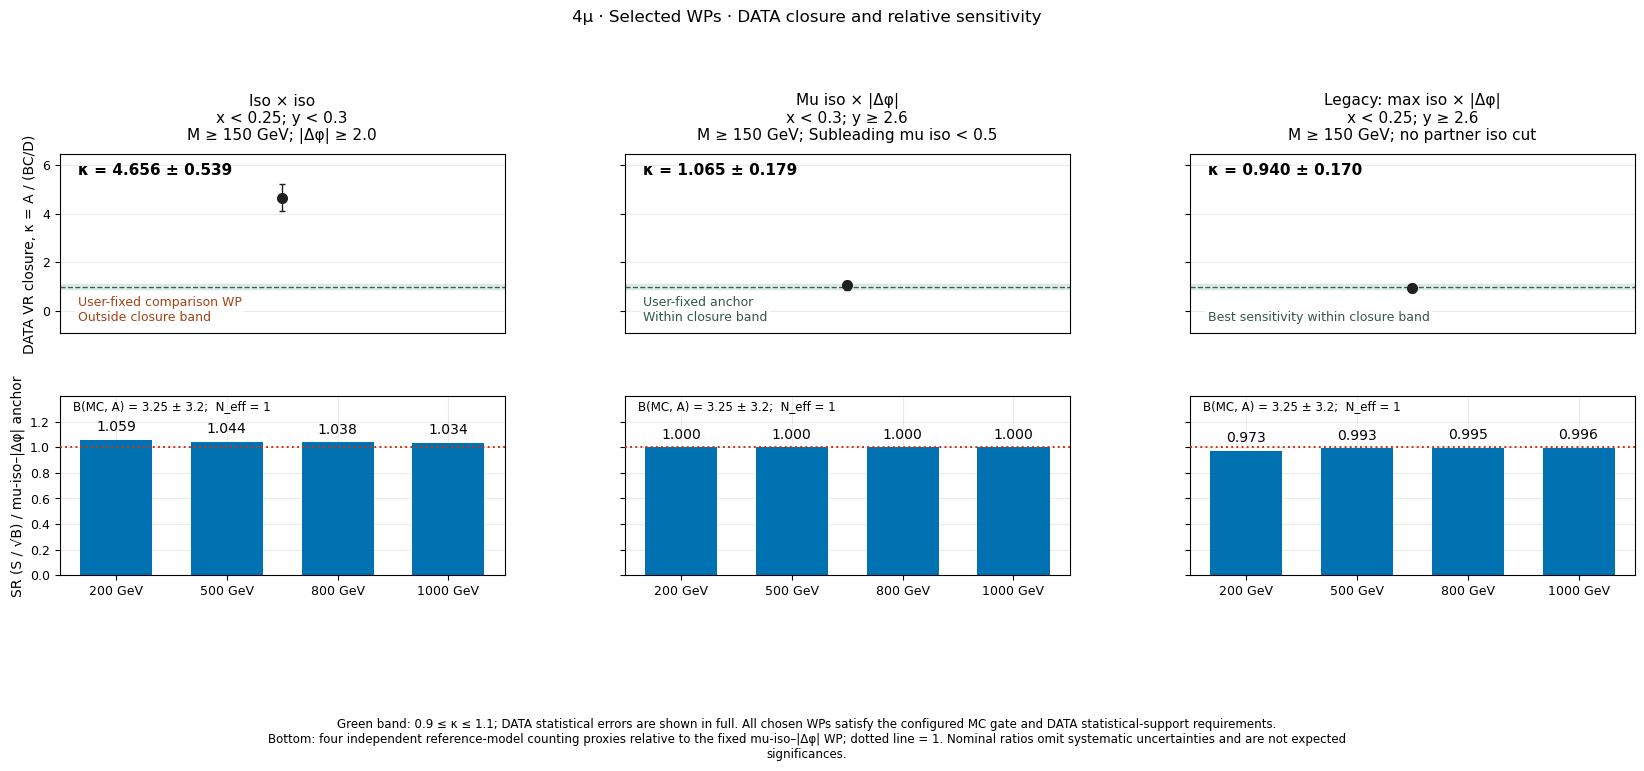

In [10]:
display(figure_lookup['selected_WP_overview'])

### 4.2. 선택된 평면 분포: MC SR

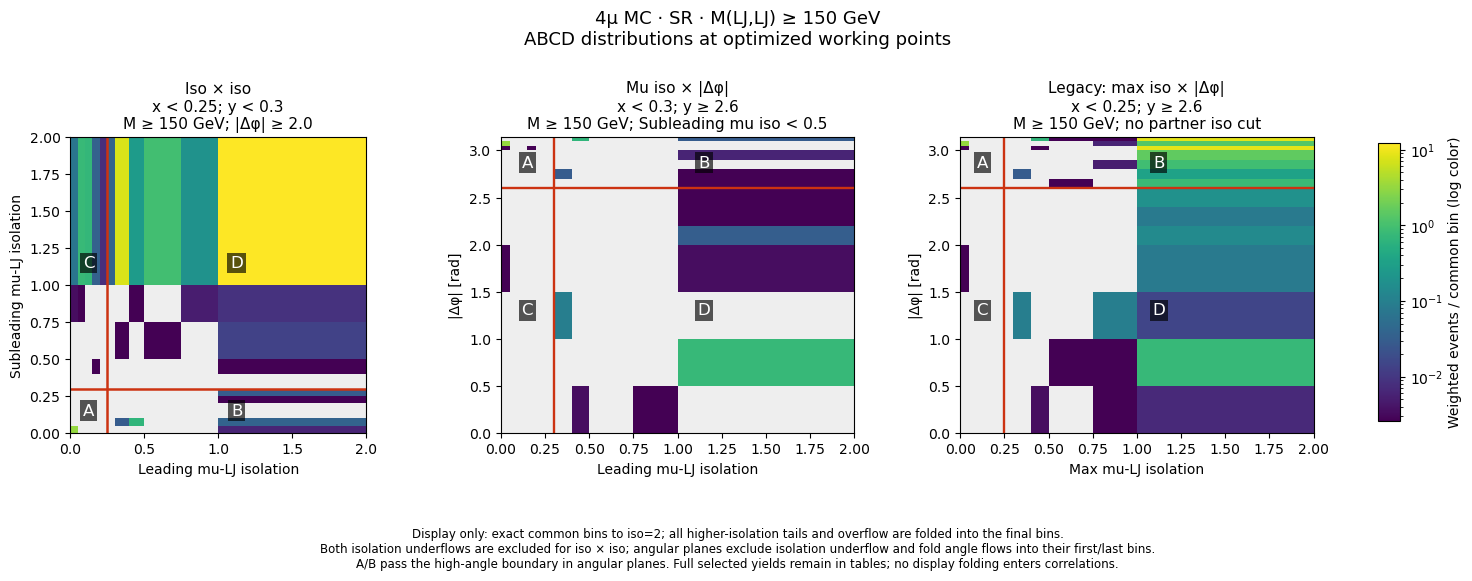

In [11]:
display(figure_lookup['mc_SR_planes'])

### 4.3. 선택된 평면 분포: MC VR

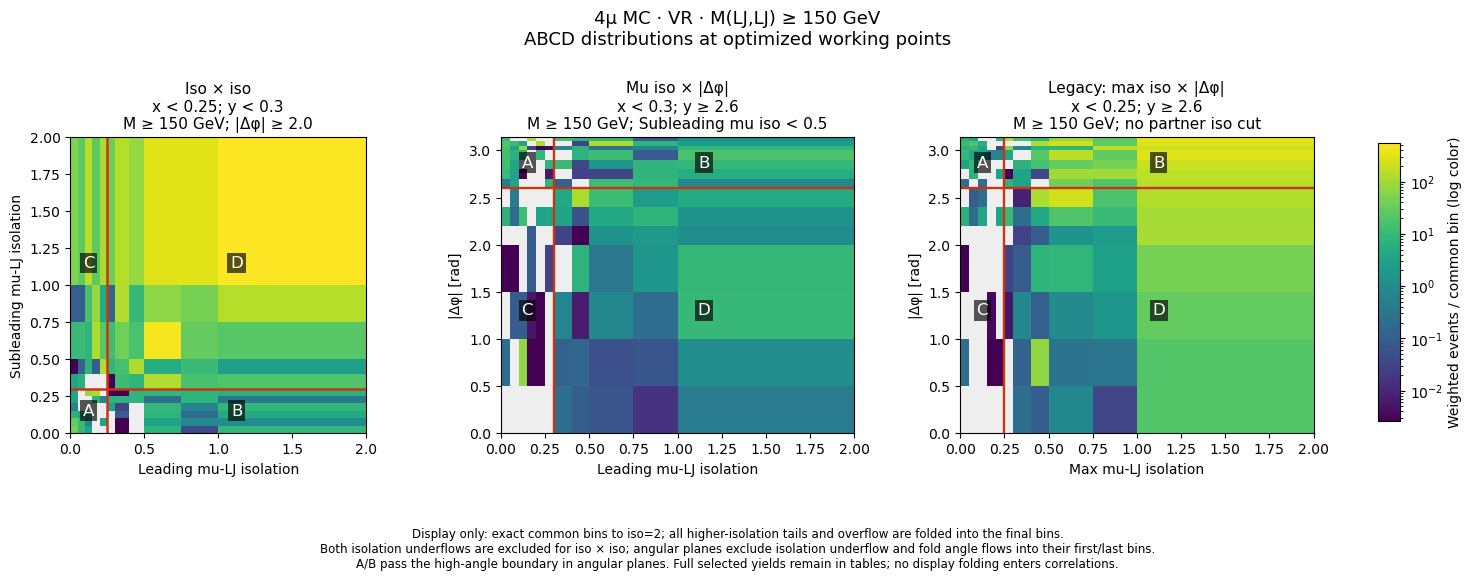

In [12]:
display(figure_lookup['mc_VR_planes'])

### 4.4. 선택된 평면 분포: DATA VR

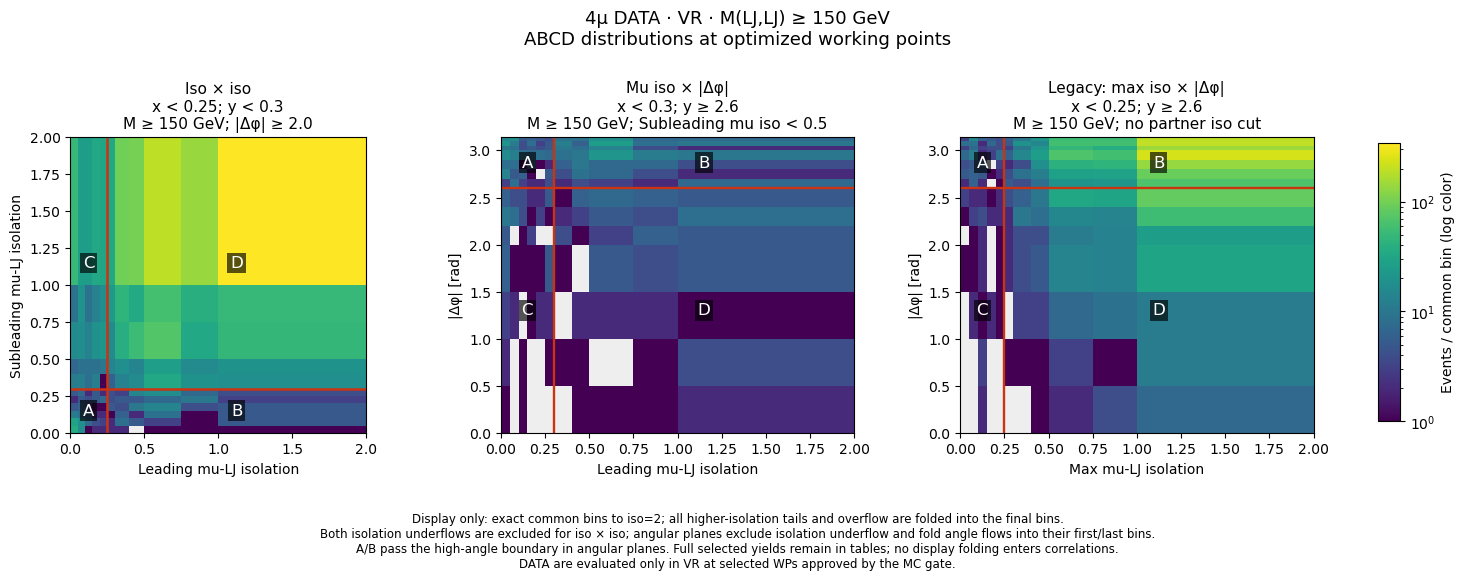

In [13]:
display(figure_lookup['data_VR_planes'])

### 4.5. 선택 WP의 관측값·ABCD 예측·closure: MC SR

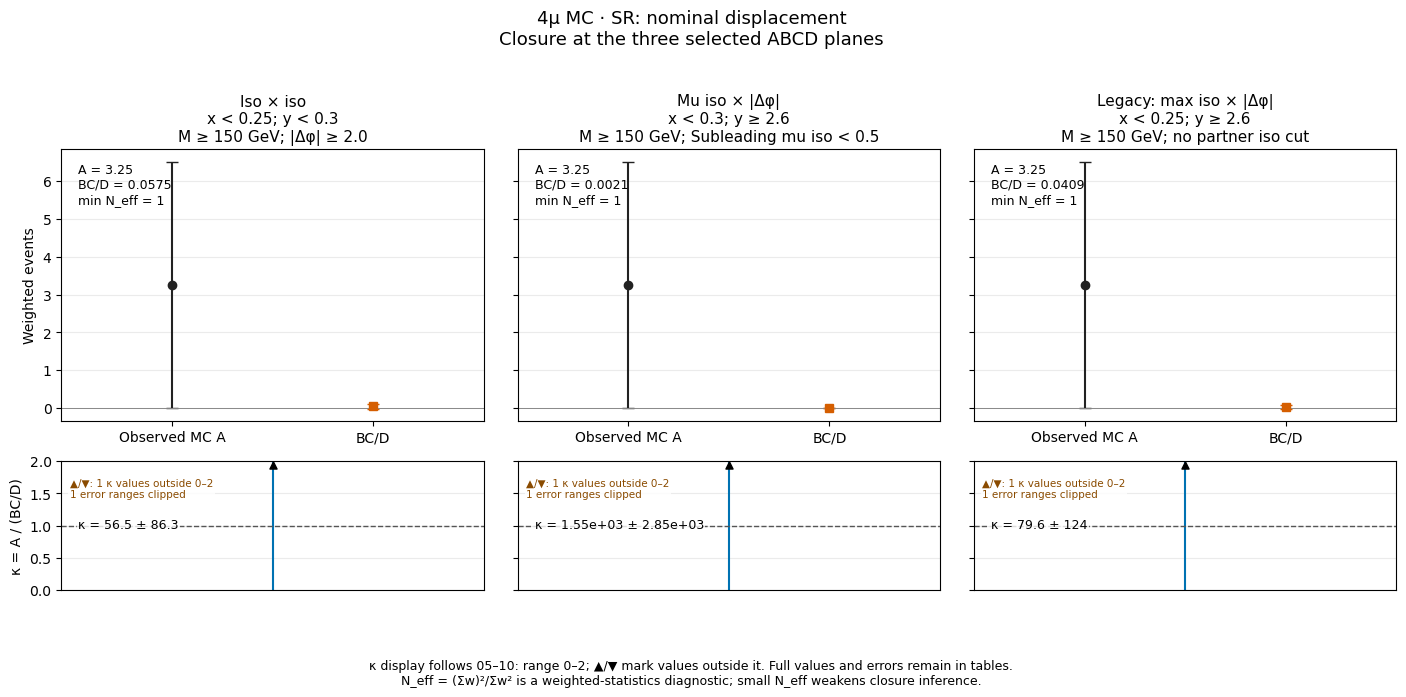

In [14]:
display(figure_lookup['mc_SR_selected_closure'])

### 4.6. 선택 WP의 관측값·ABCD 예측·closure: MC VR

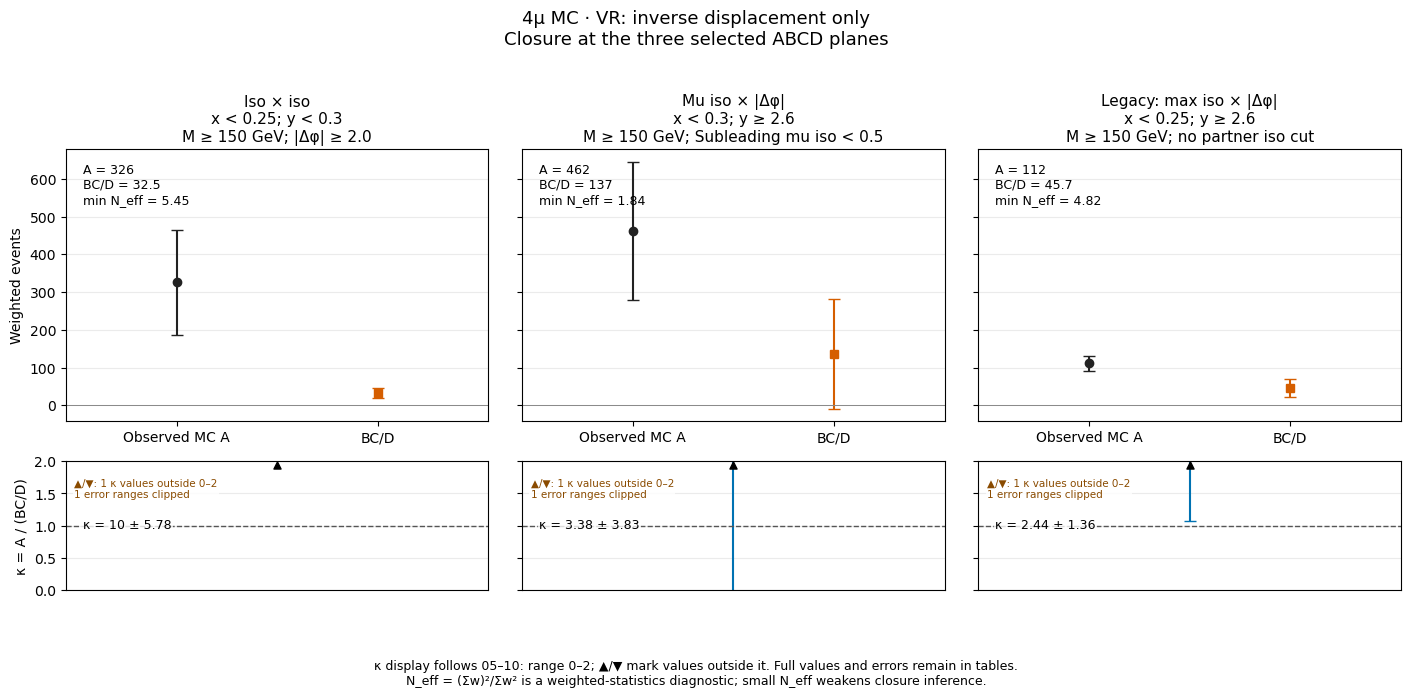

In [15]:
display(figure_lookup['mc_VR_selected_closure'])

### 4.7. 선택 WP의 관측값·ABCD 예측·closure: DATA VR

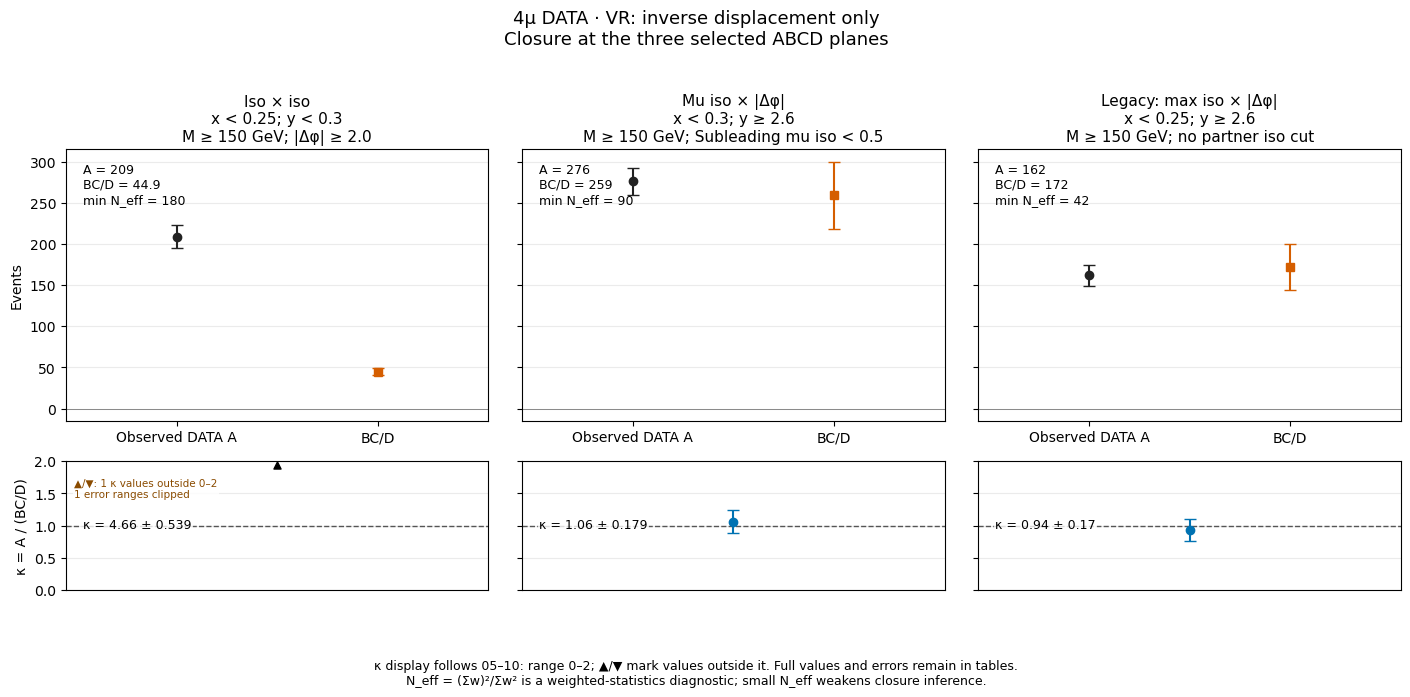

In [16]:
display(figure_lookup['data_VR_selected_closure'])

### 4.8. 주축 1D closure 스캔과 신호 진단: MC SR

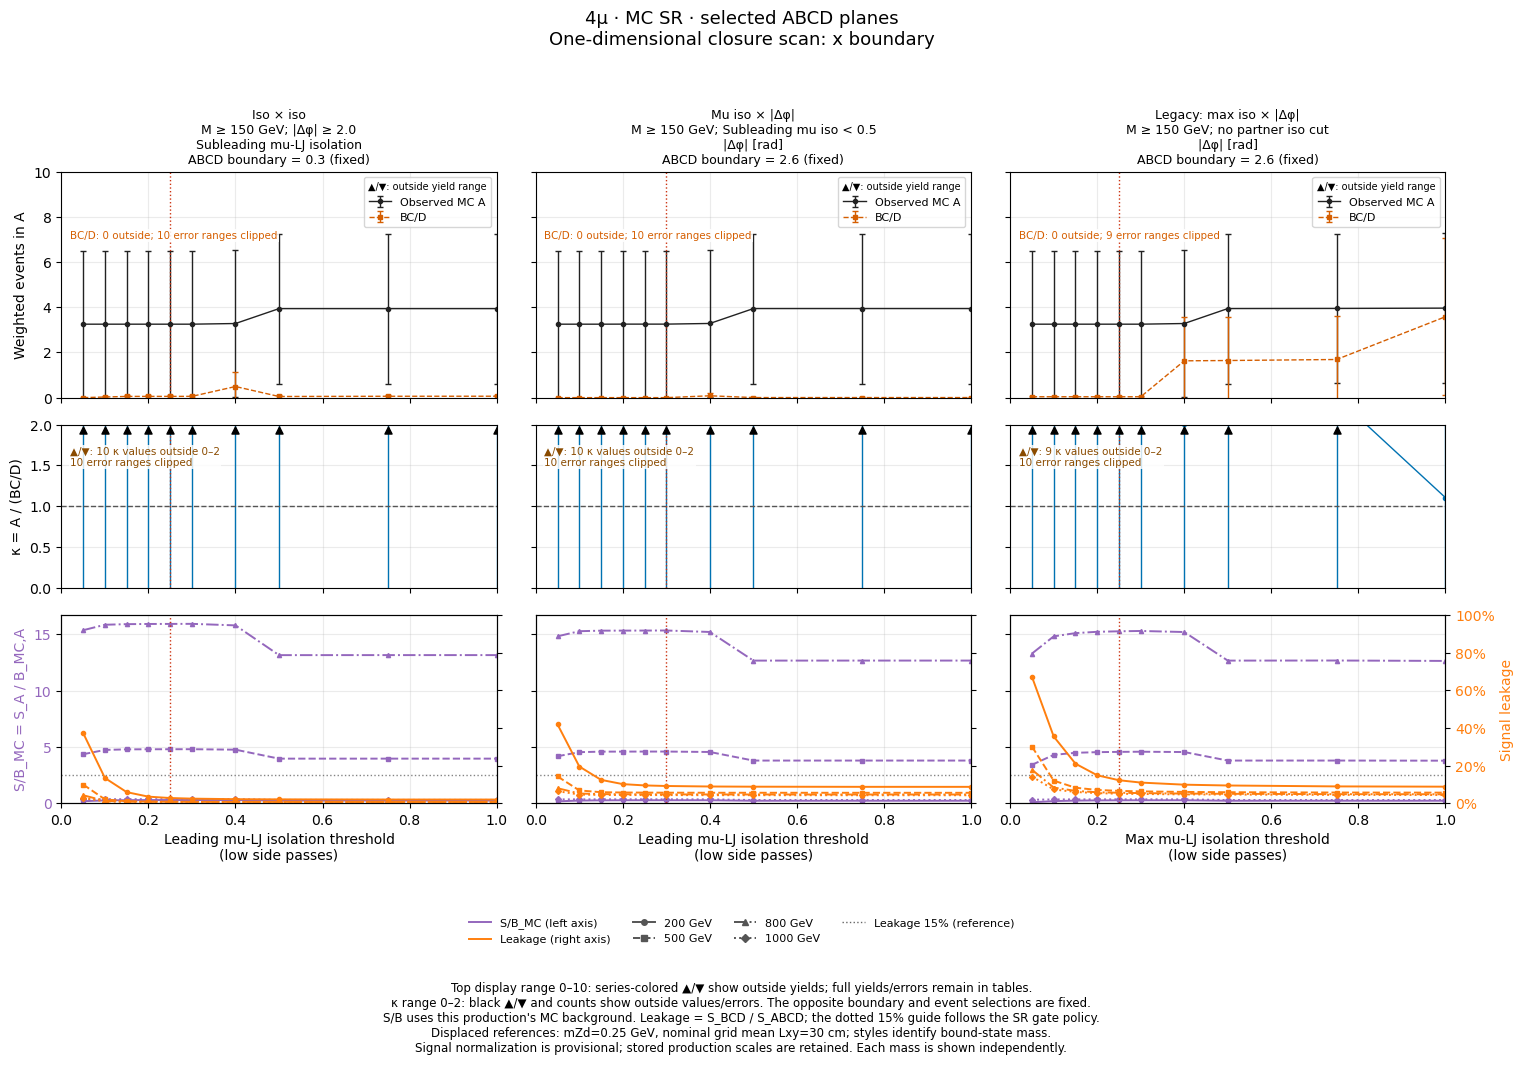

In [17]:
display(figure_lookup['mc_SR_x_scan'])

### 4.9. 두 번째 축 1D closure 스캔과 신호 진단: MC SR

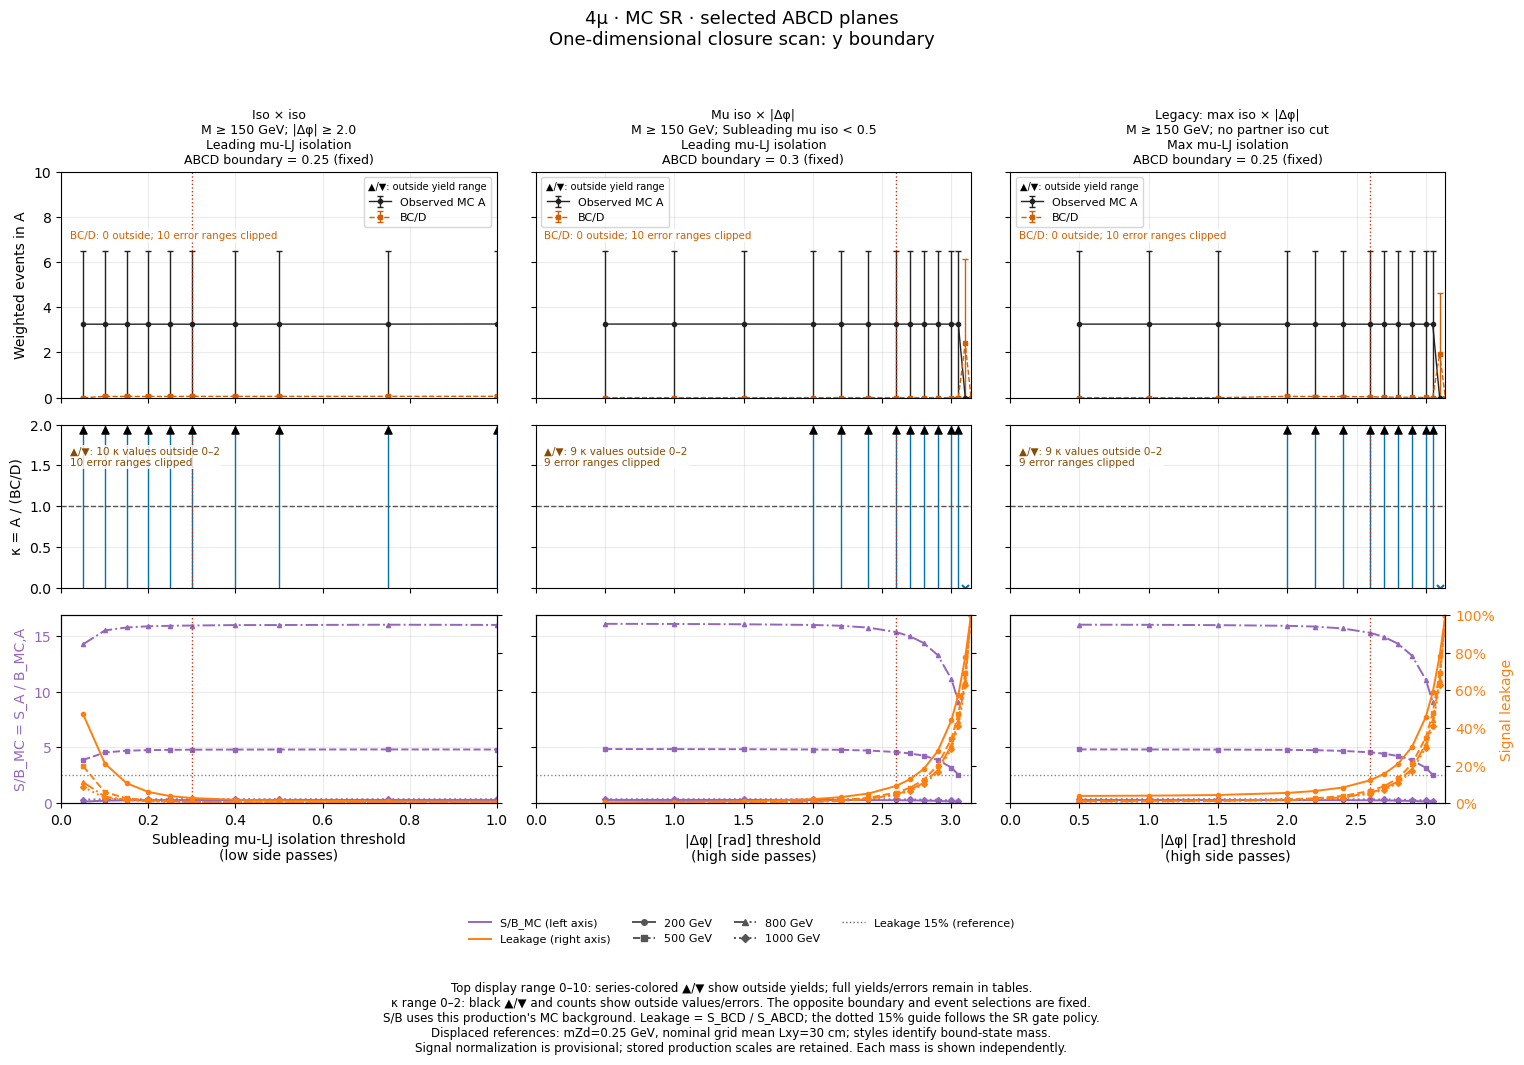

In [18]:
display(figure_lookup['mc_SR_y_scan'])

### 4.10. 주축 1D closure 스캔과 신호 진단: MC VR

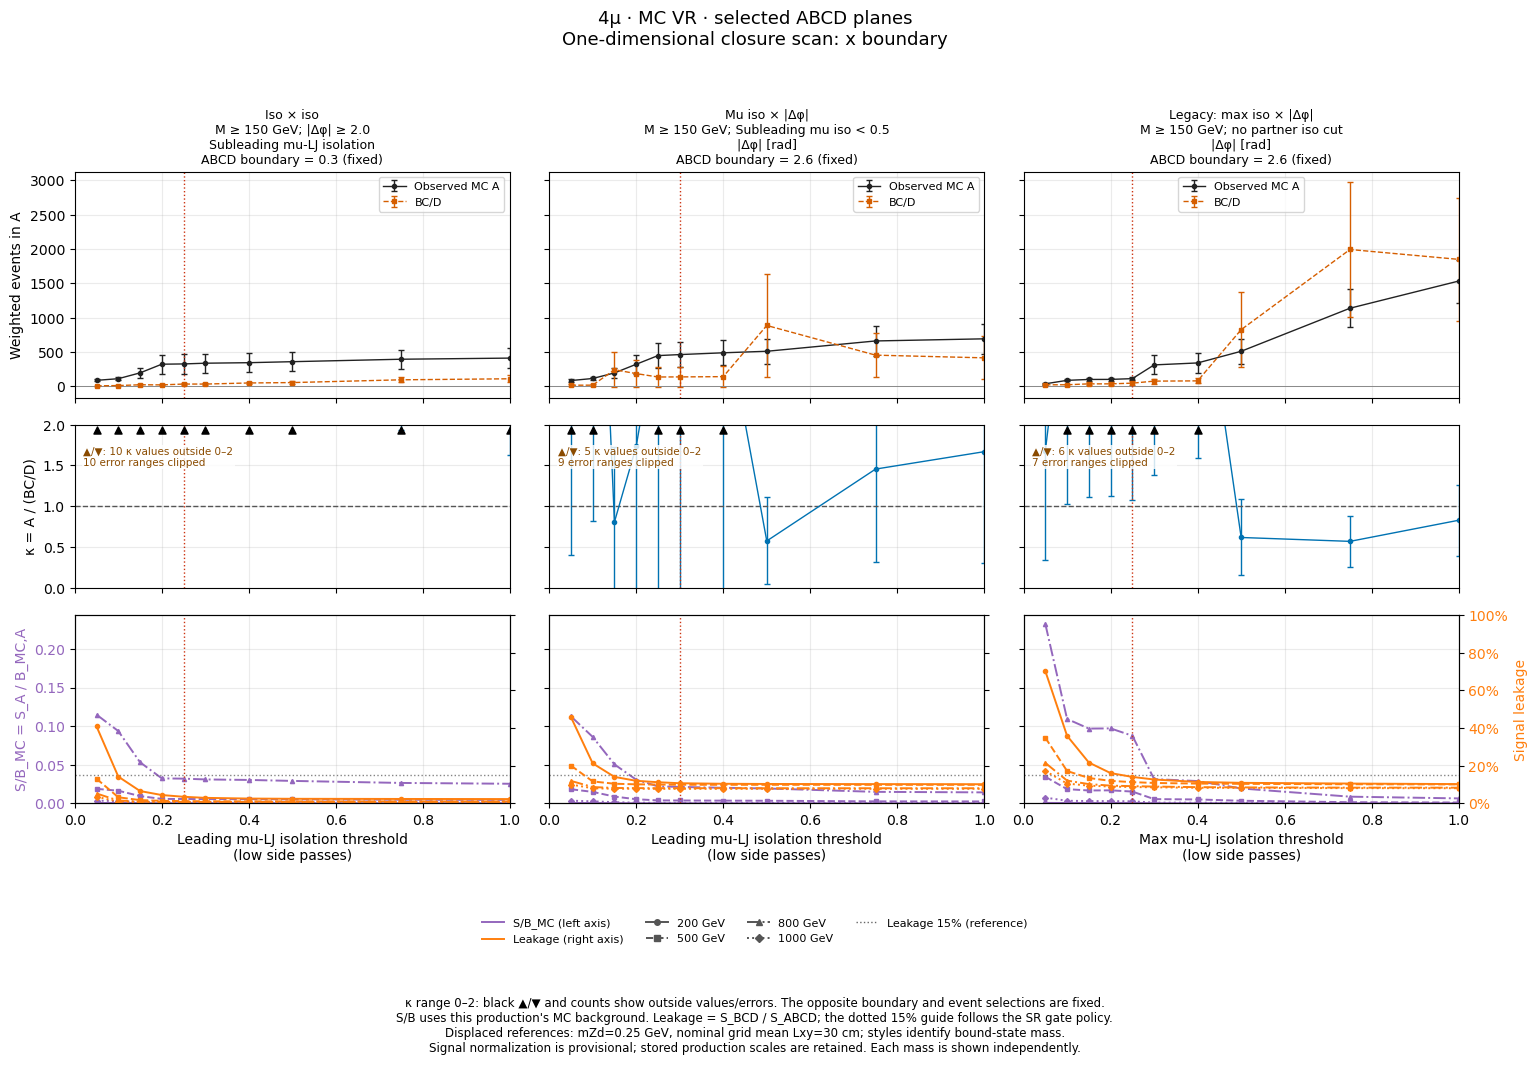

In [19]:
display(figure_lookup['mc_VR_x_scan'])

### 4.11. 두 번째 축 1D closure 스캔과 신호 진단: MC VR

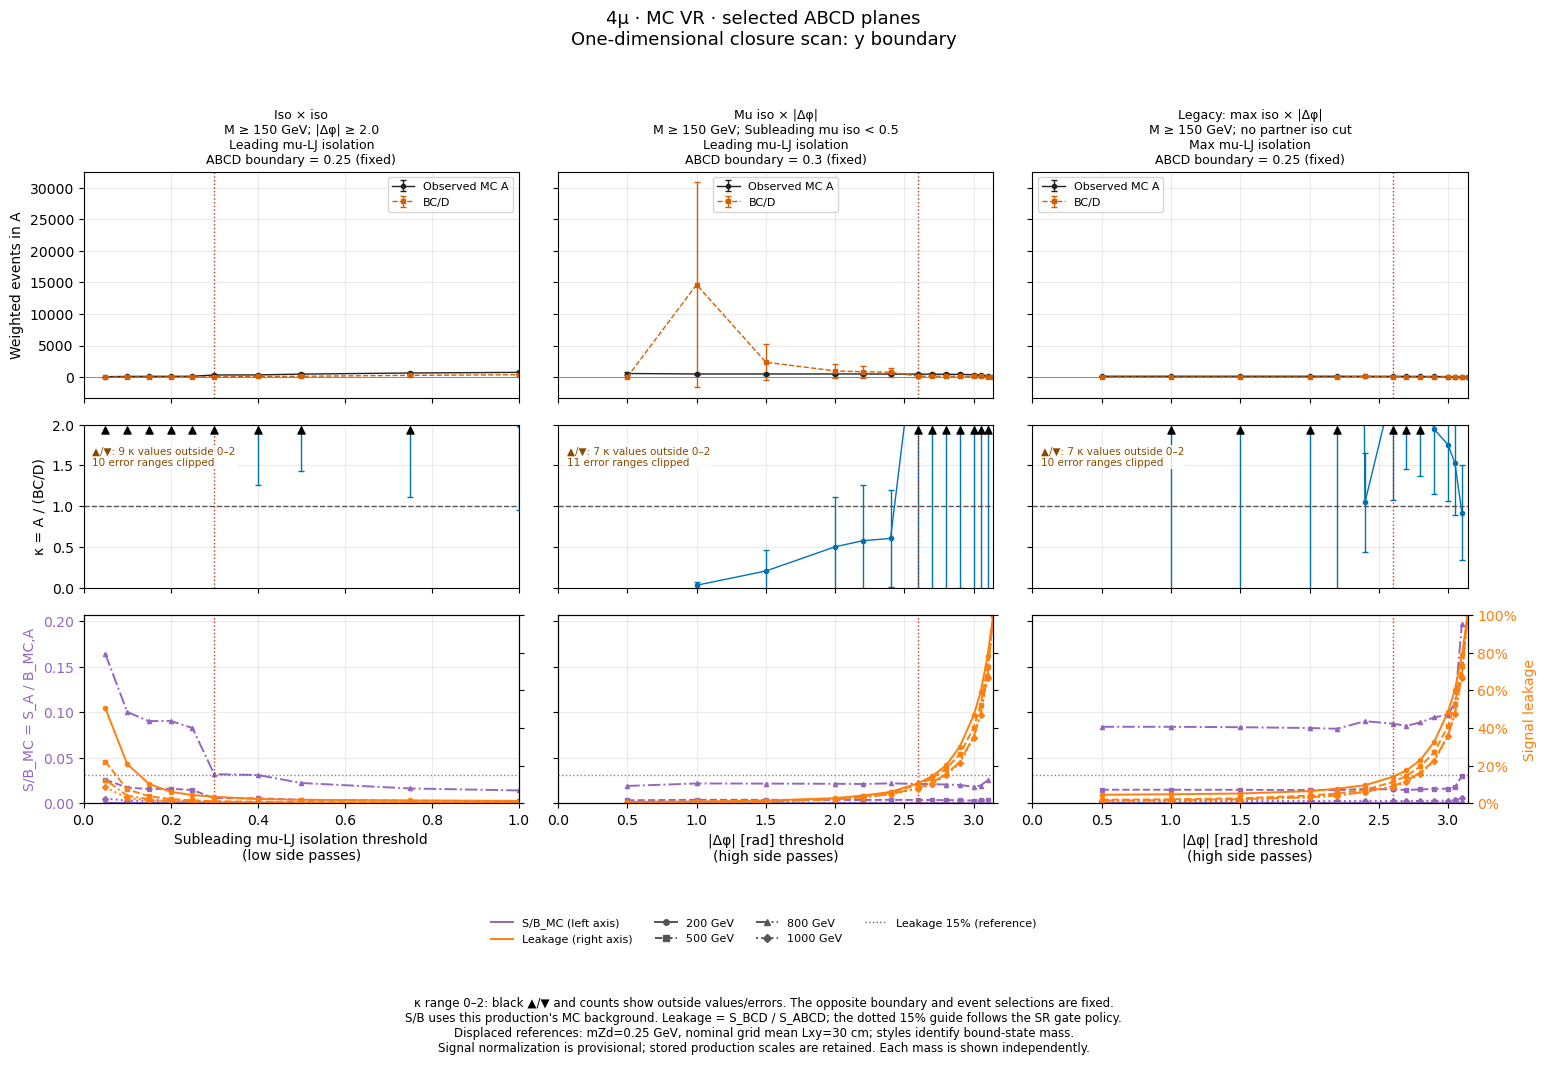

In [20]:
display(figure_lookup['mc_VR_y_scan'])

### 4.12. 주축 1D closure 스캔과 신호 진단: DATA VR

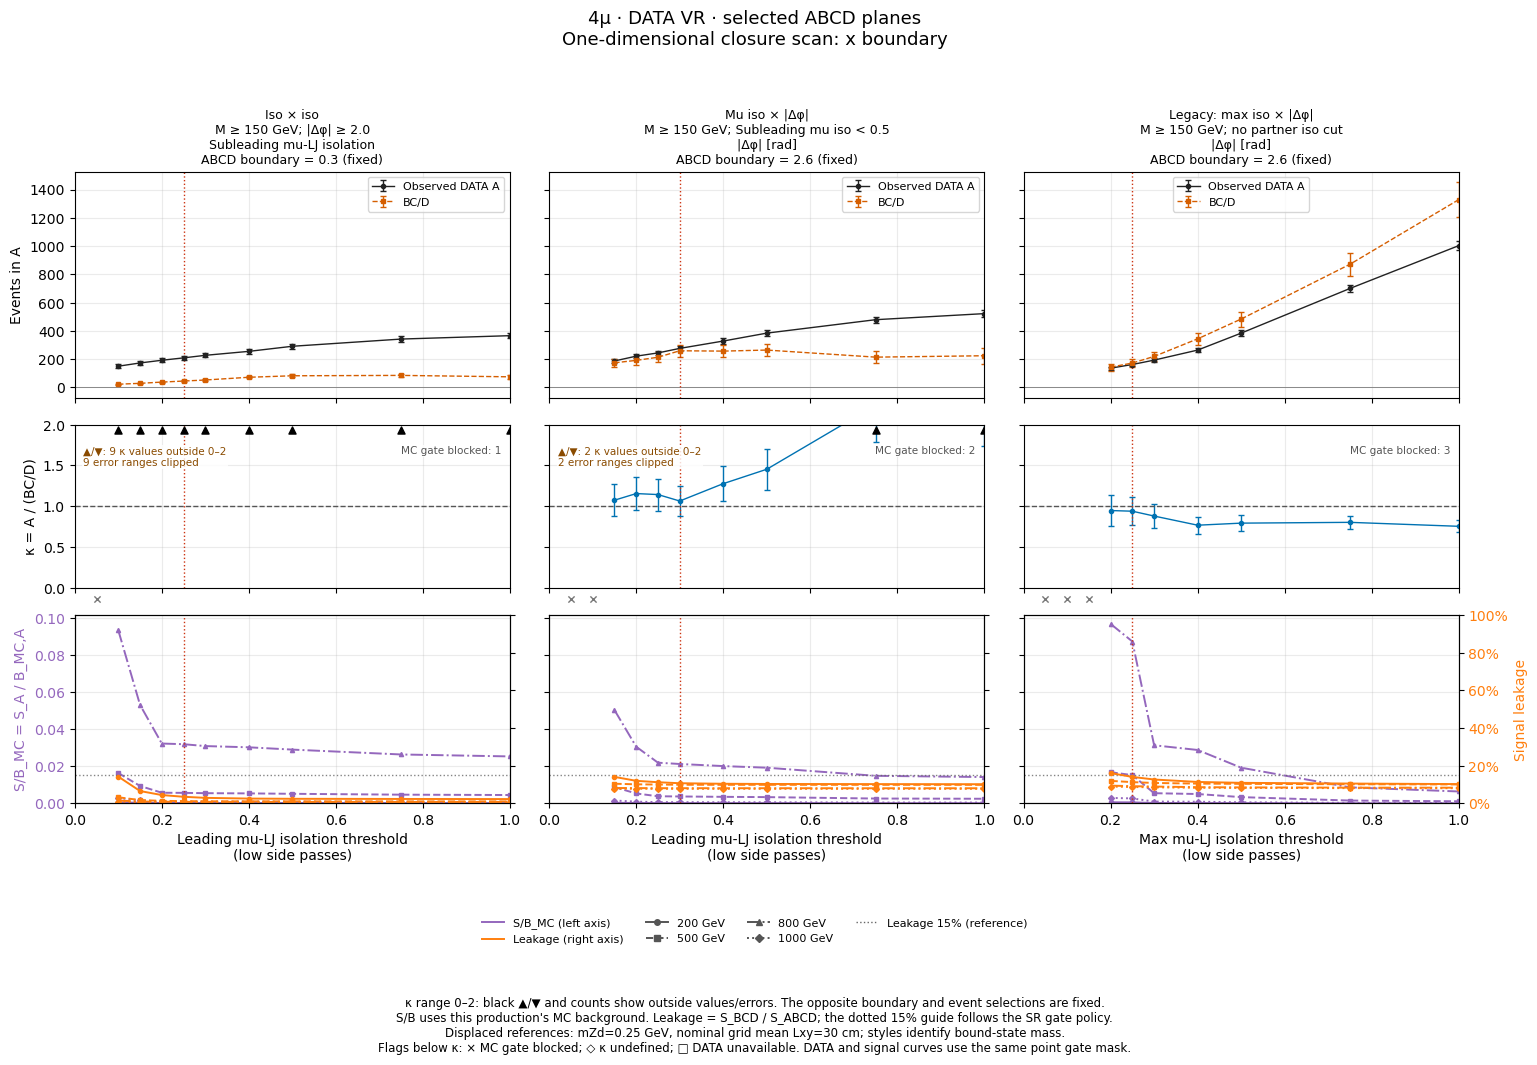

In [21]:
display(figure_lookup['data_VR_x_scan'])

### 4.13. 두 번째 축 1D closure 스캔과 신호 진단: DATA VR

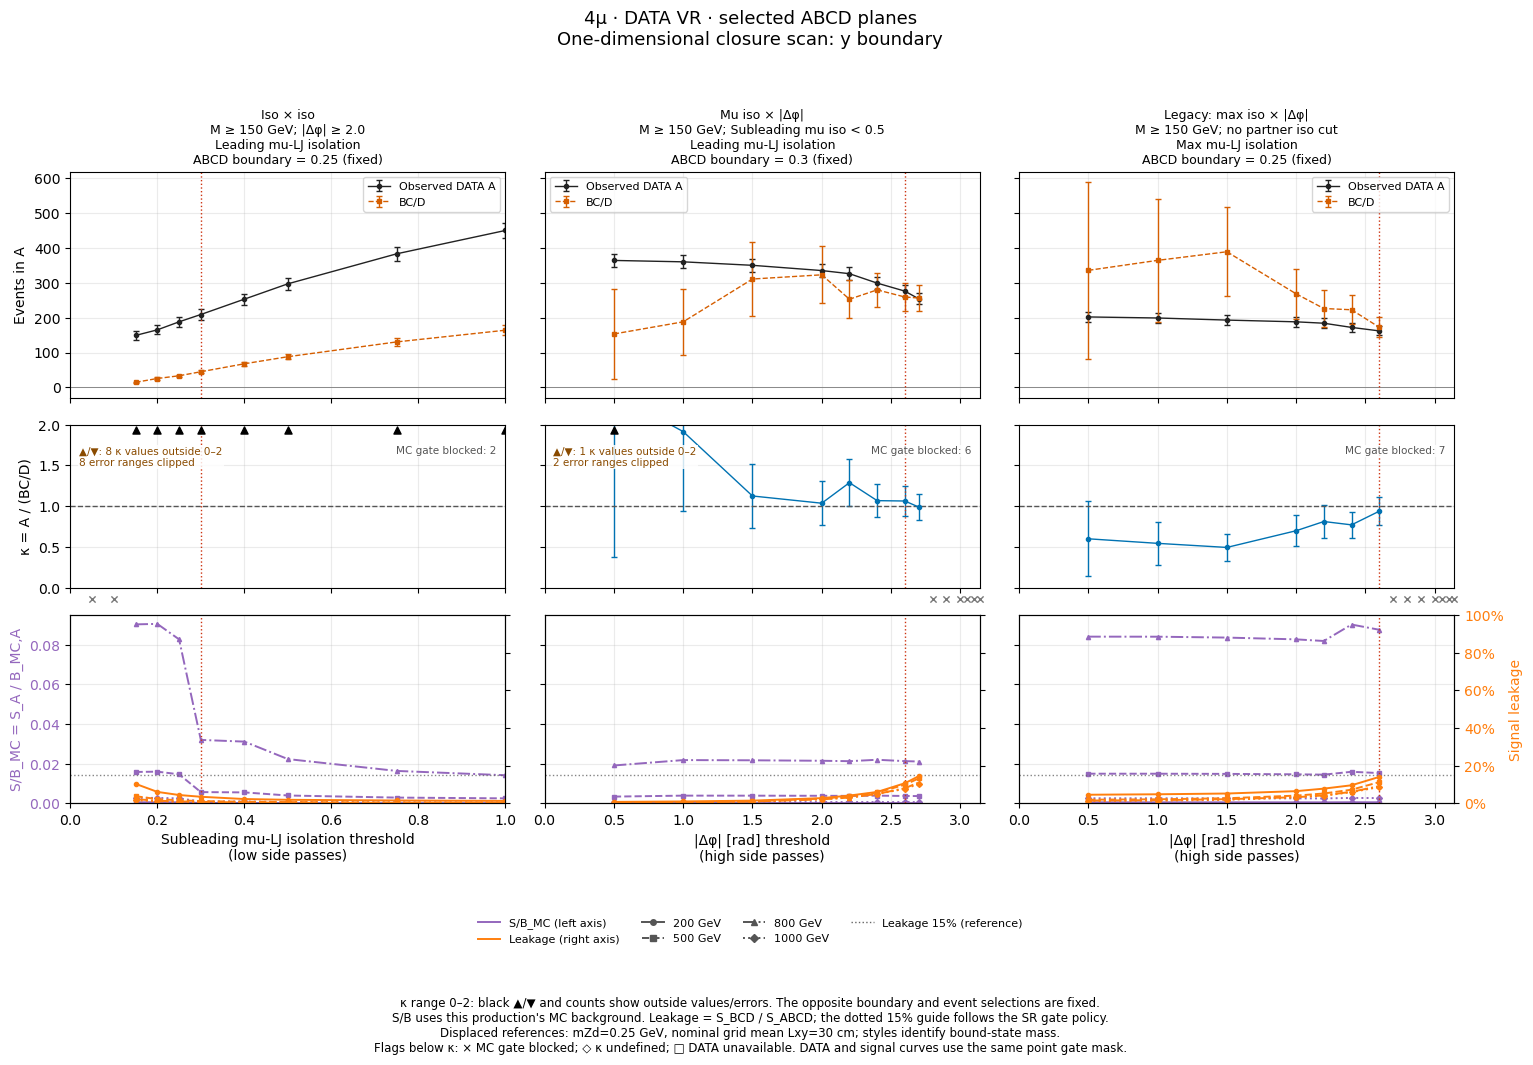

In [22]:
display(figure_lookup['data_VR_y_scan'])

### 4.14. 2D closure 지도: MC SR

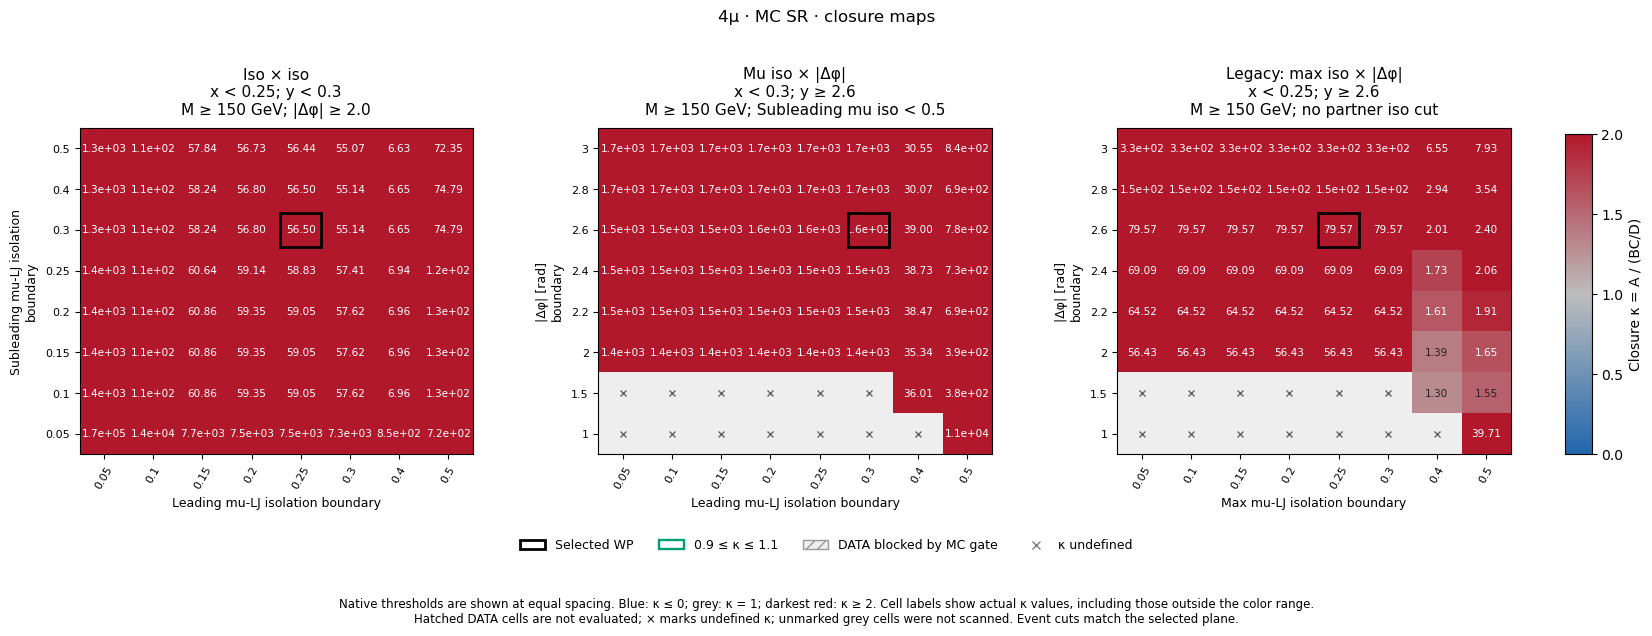

In [23]:
display(figure_lookup['mc_SR_closure_grid'])

### 4.15. 2D closure 지도: MC VR

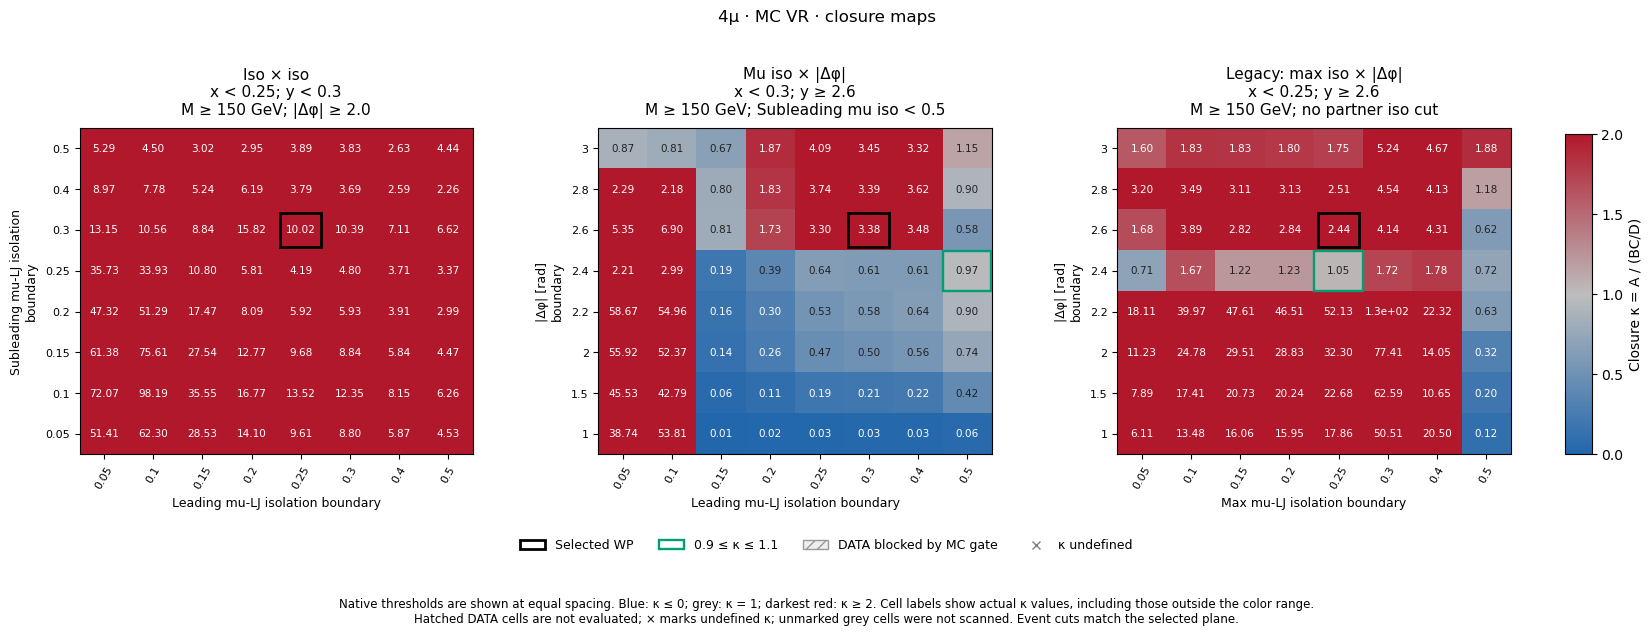

In [24]:
display(figure_lookup['mc_VR_closure_grid'])

### 4.16. 2D closure 지도: DATA VR

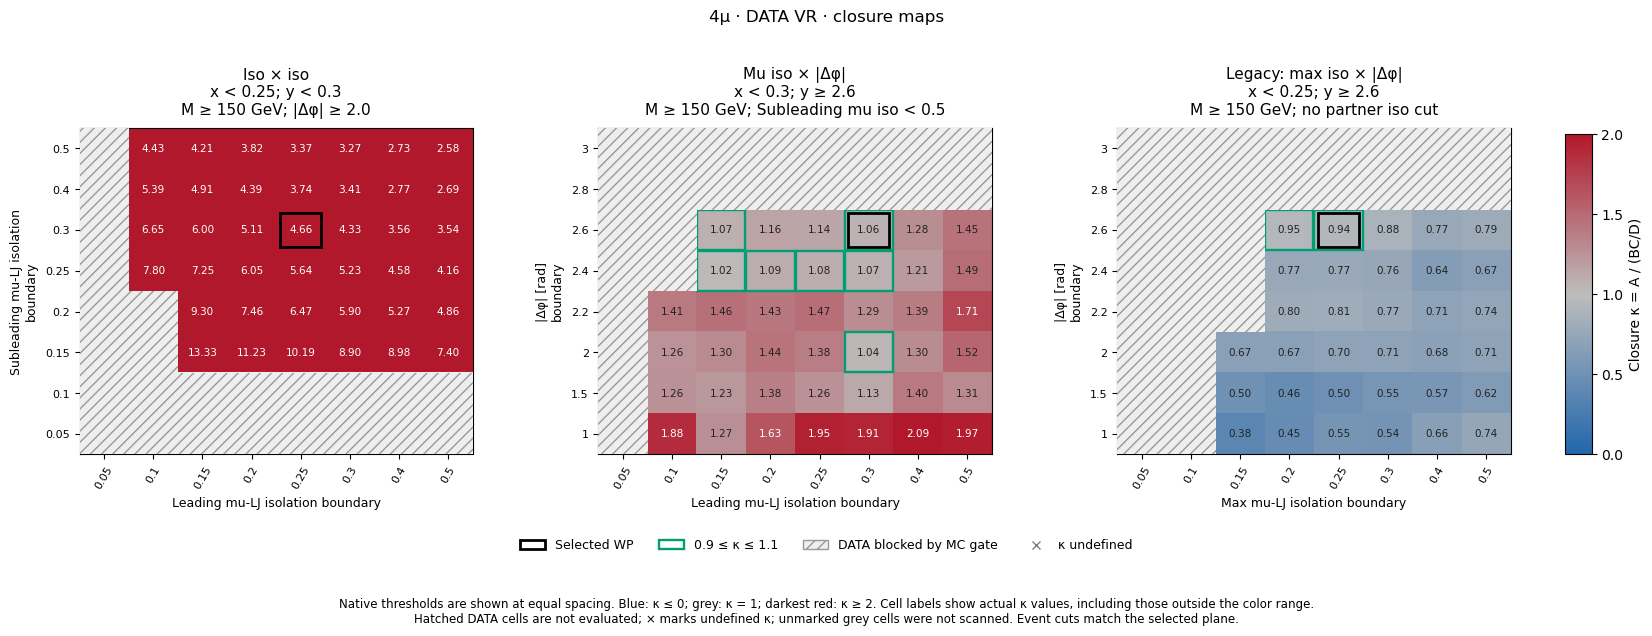

In [25]:
display(figure_lookup['data_VR_closure_grid'])

### 4.17. 신호 효율과 S/√B: SR

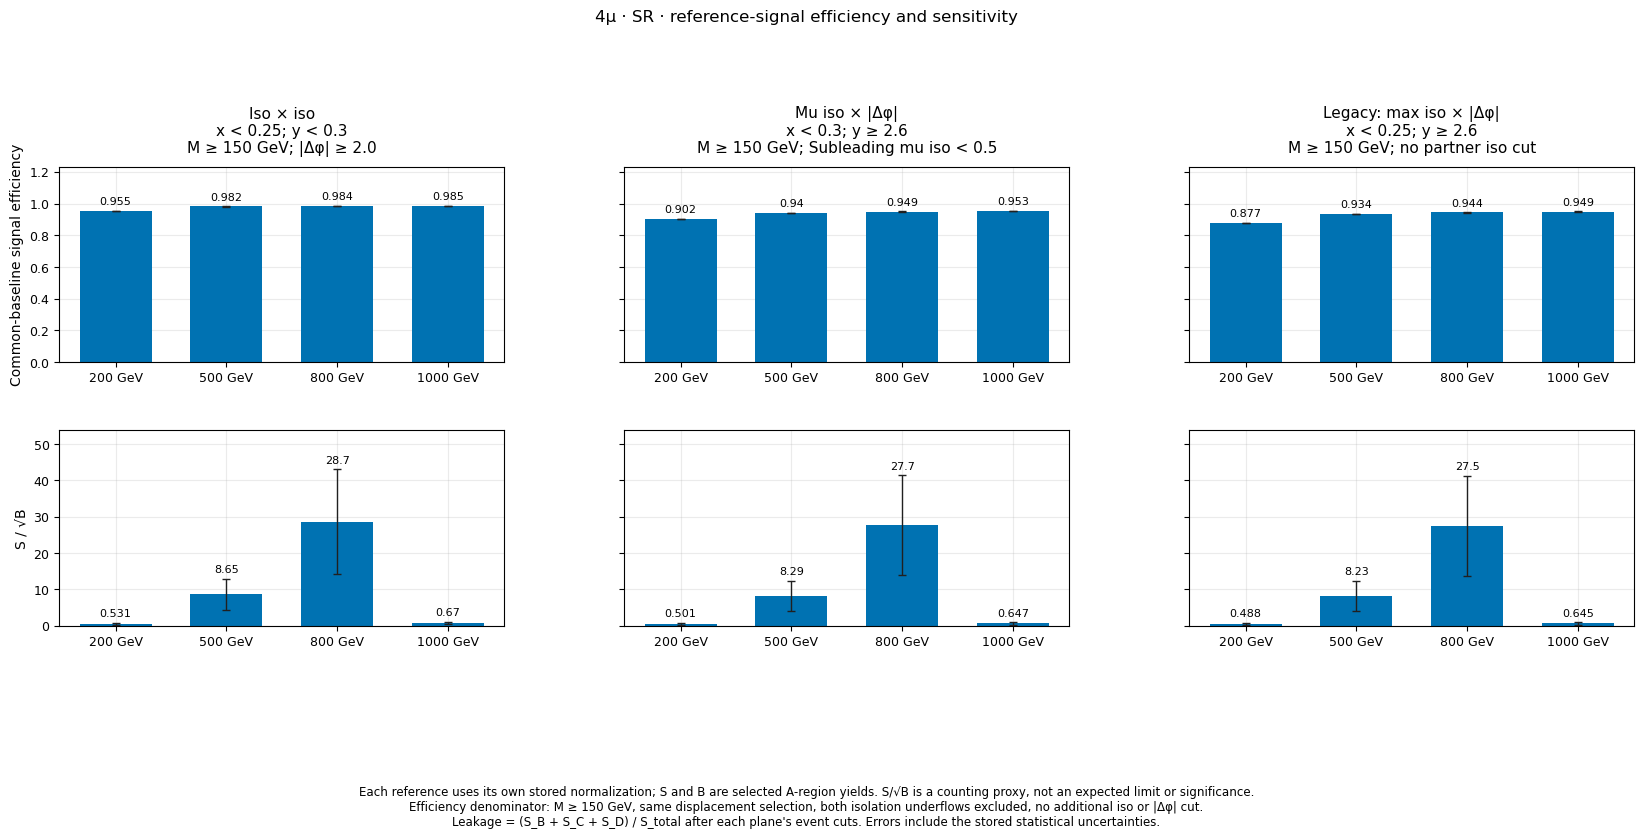

In [26]:
if 'signal_SR_efficiency_sensitivity' in figure_lookup:
    display(figure_lookup['signal_SR_efficiency_sensitivity'])
else:
    print('해당 추가 진단은 현재 설정에서 생성되지 않았습니다.')

### 4.18. 신호 S/B와 leakage: SR

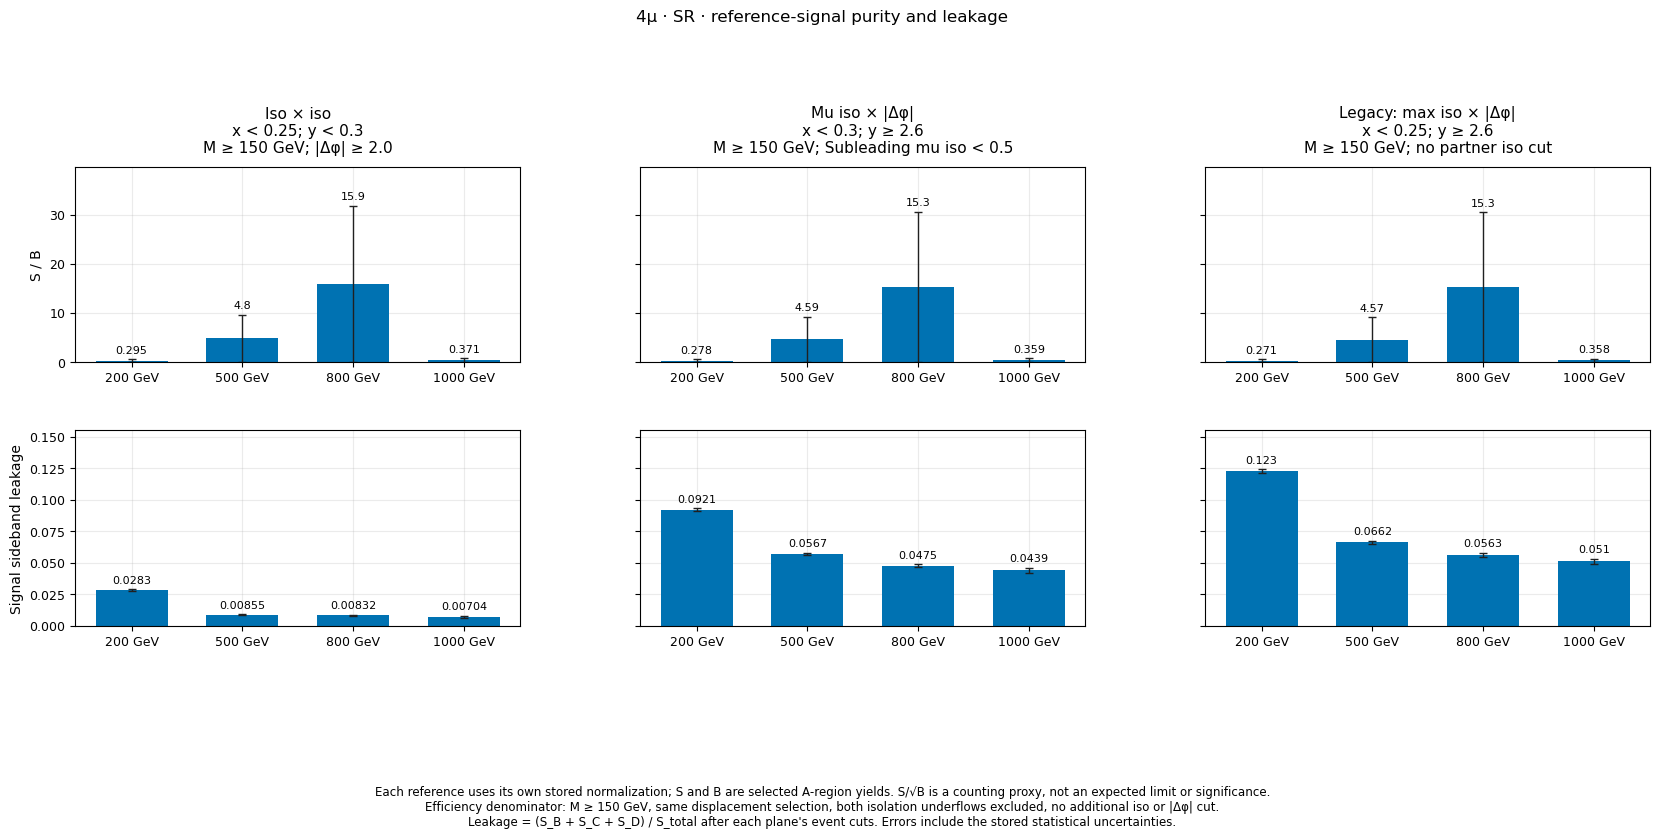

In [27]:
if 'signal_SR_purity_leakage' in figure_lookup:
    display(figure_lookup['signal_SR_purity_leakage'])
else:
    print('해당 추가 진단은 현재 설정에서 생성되지 않았습니다.')

### 4.19. 신호 효율과 S/√B: VR

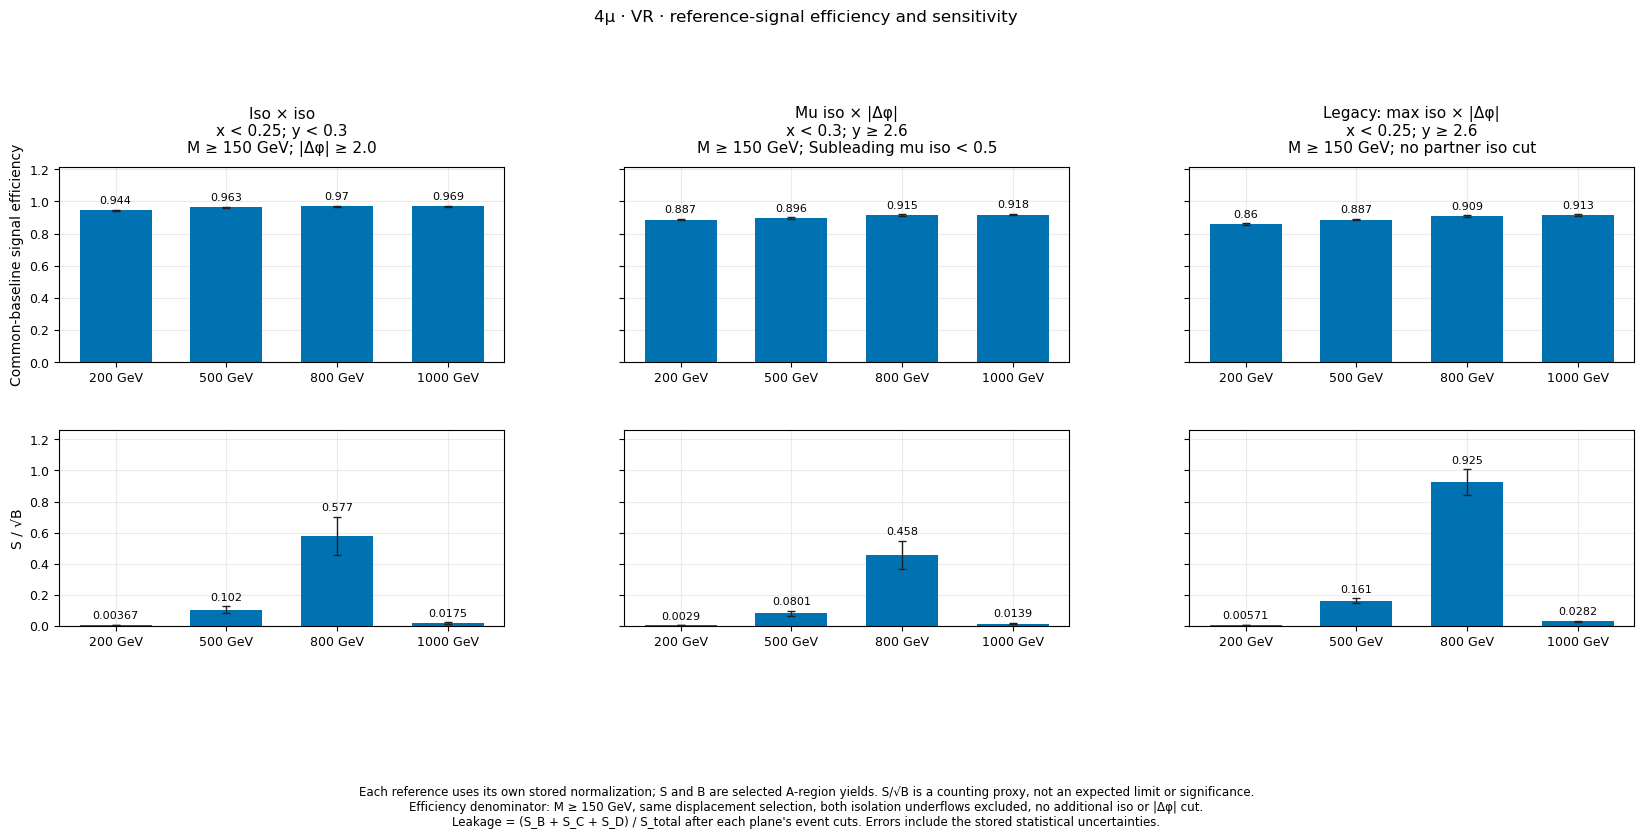

In [28]:
if 'signal_VR_efficiency_sensitivity' in figure_lookup:
    display(figure_lookup['signal_VR_efficiency_sensitivity'])
else:
    print('해당 추가 진단은 현재 설정에서 생성되지 않았습니다.')

### 4.20. 신호 S/B와 leakage: VR

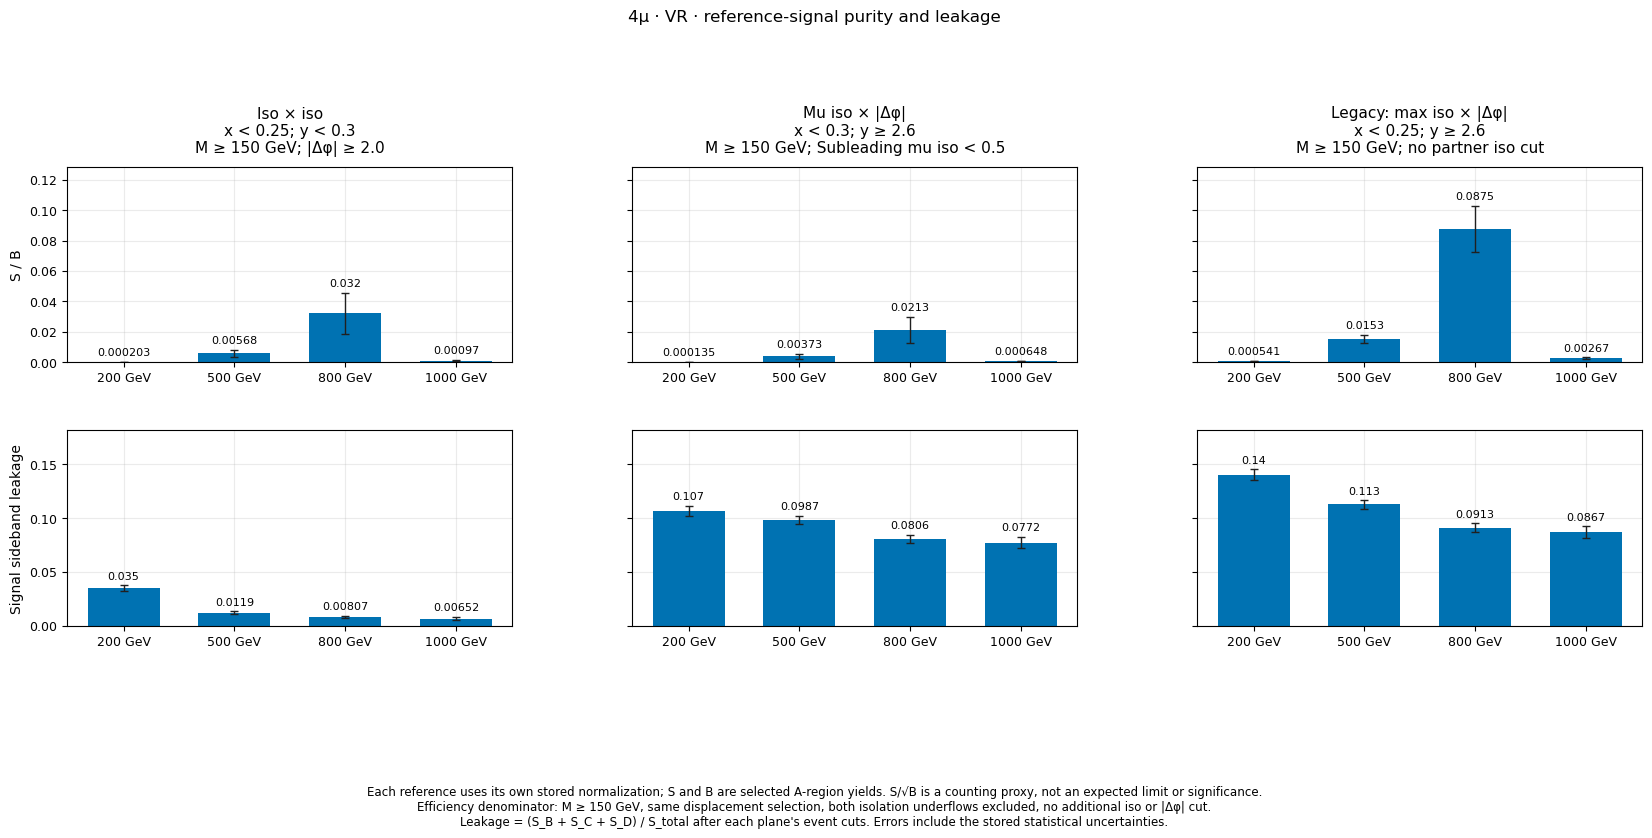

In [29]:
if 'signal_VR_purity_leakage' in figure_lookup:
    display(figure_lookup['signal_VR_purity_leakage'])
else:
    print('해당 추가 진단은 현재 설정에서 생성되지 않았습니다.')

### 4.21. 추가 최적화 진단 — S/√B와 leakage의 주축 스캔: SR

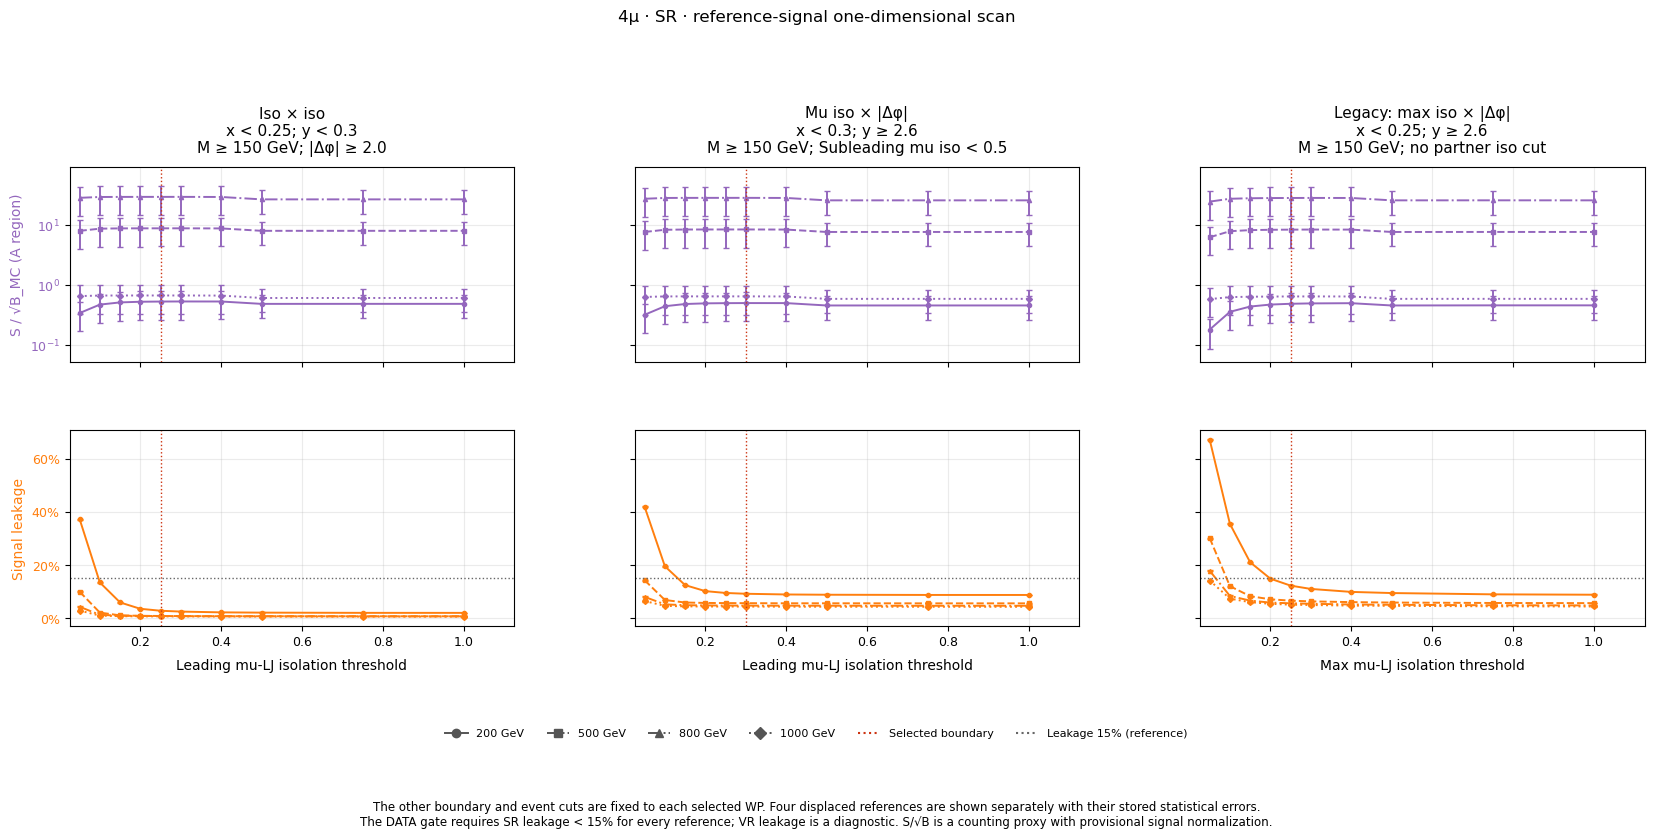

In [30]:
if 'signal_SR_x_scan' in figure_lookup:
    display(figure_lookup['signal_SR_x_scan'])
else:
    print('해당 추가 진단은 현재 설정에서 생성되지 않았습니다.')

### 4.22. 추가 최적화 진단 — S/√B와 leakage의 두 번째 축 스캔: SR

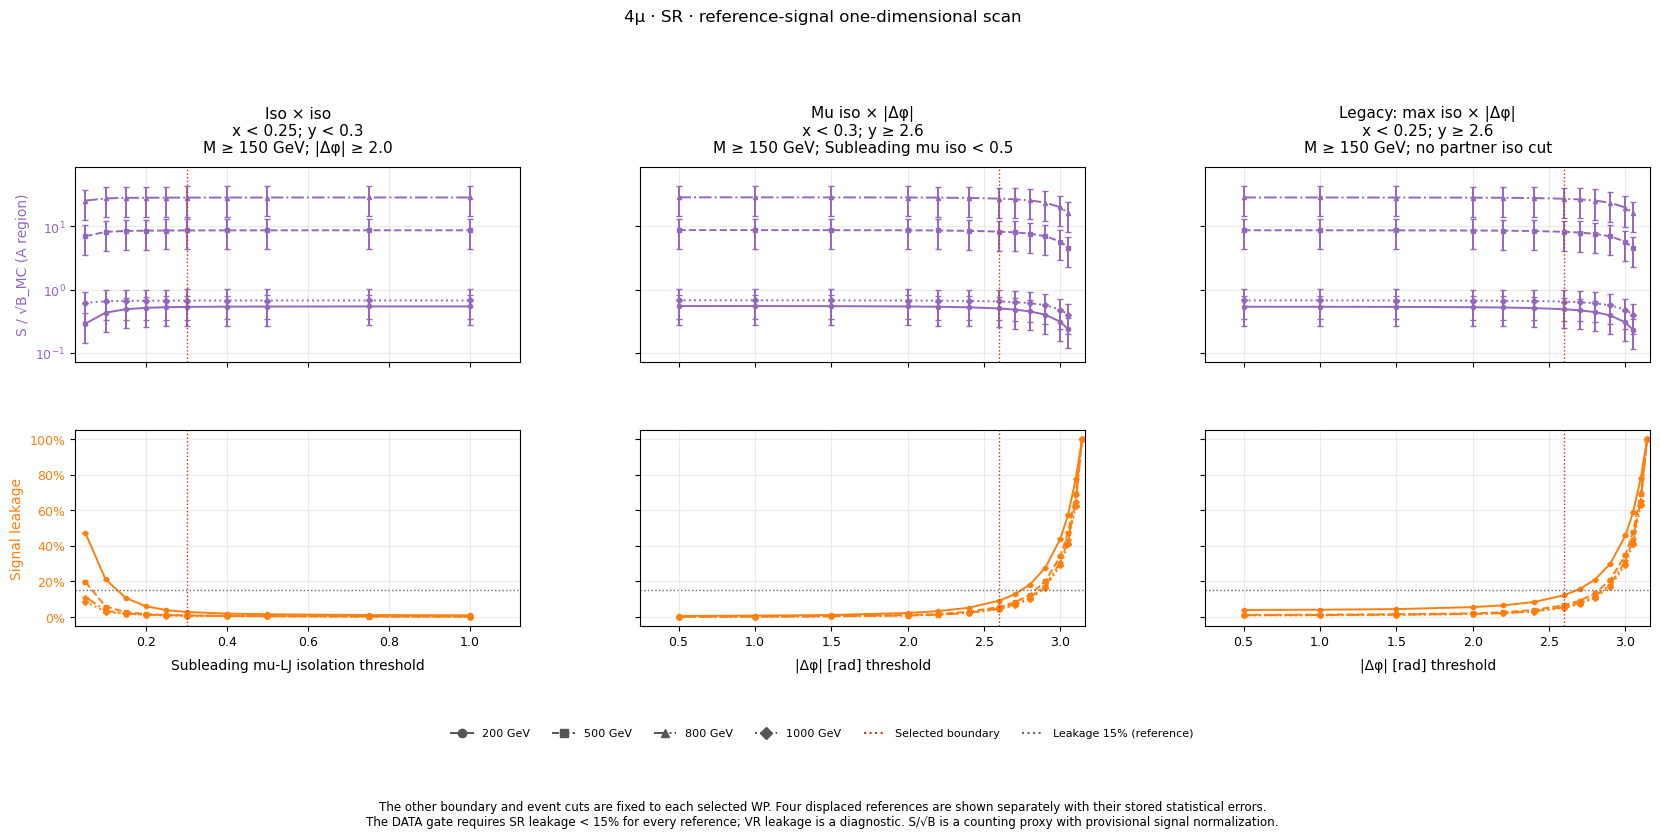

In [31]:
if 'signal_SR_y_scan' in figure_lookup:
    display(figure_lookup['signal_SR_y_scan'])
else:
    print('해당 추가 진단은 현재 설정에서 생성되지 않았습니다.')

### 4.23. 추가 최적화 진단 — S/√B와 leakage의 주축 스캔: VR

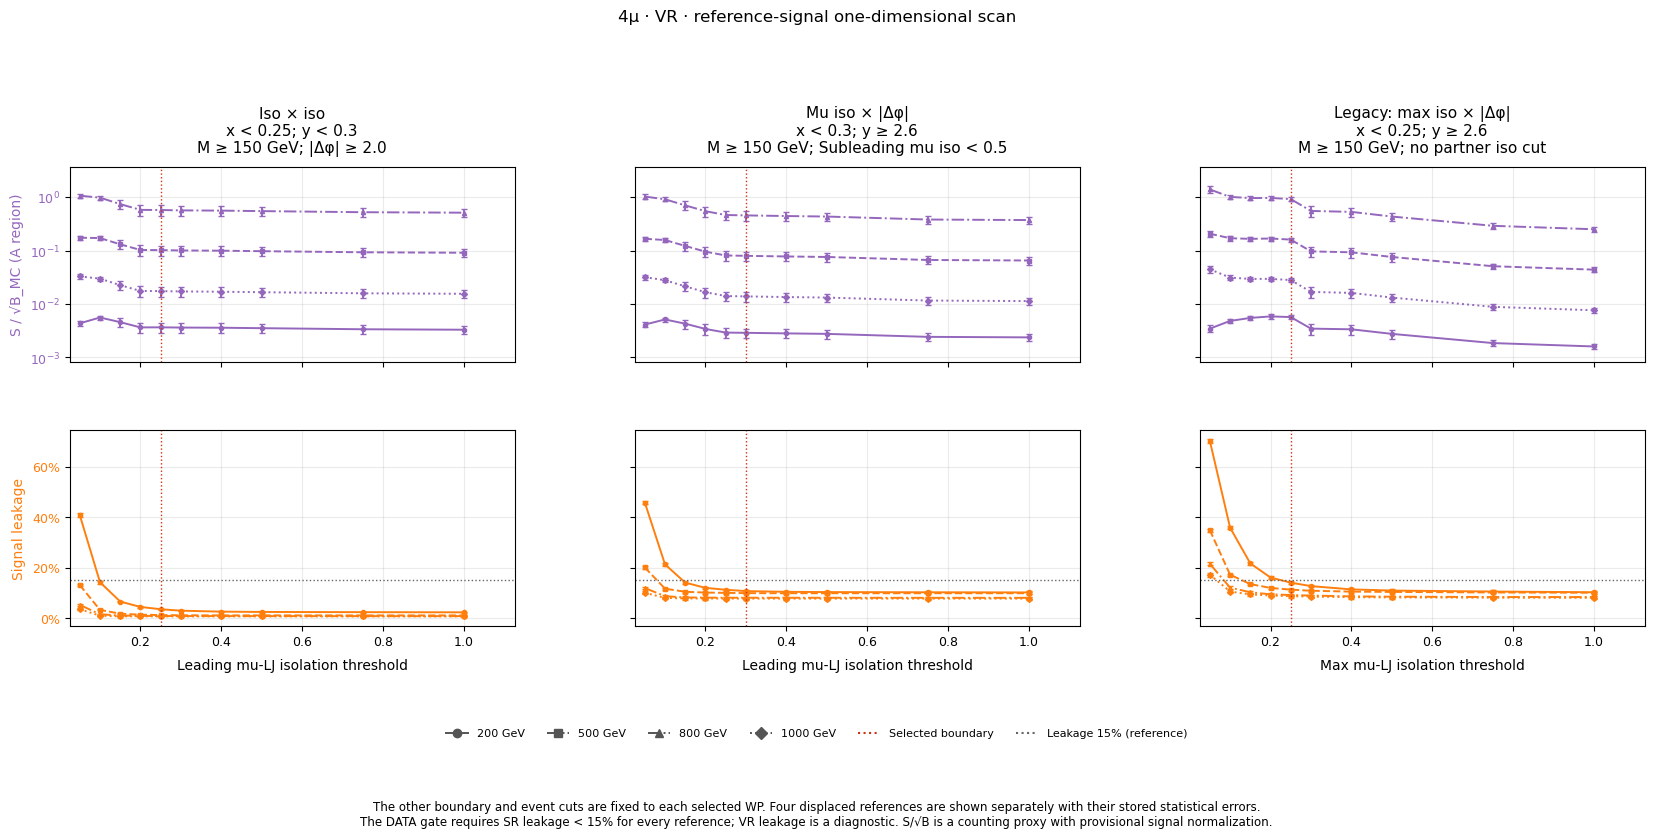

In [32]:
if 'signal_VR_x_scan' in figure_lookup:
    display(figure_lookup['signal_VR_x_scan'])
else:
    print('해당 추가 진단은 현재 설정에서 생성되지 않았습니다.')

### 4.24. 추가 최적화 진단 — S/√B와 leakage의 두 번째 축 스캔: VR

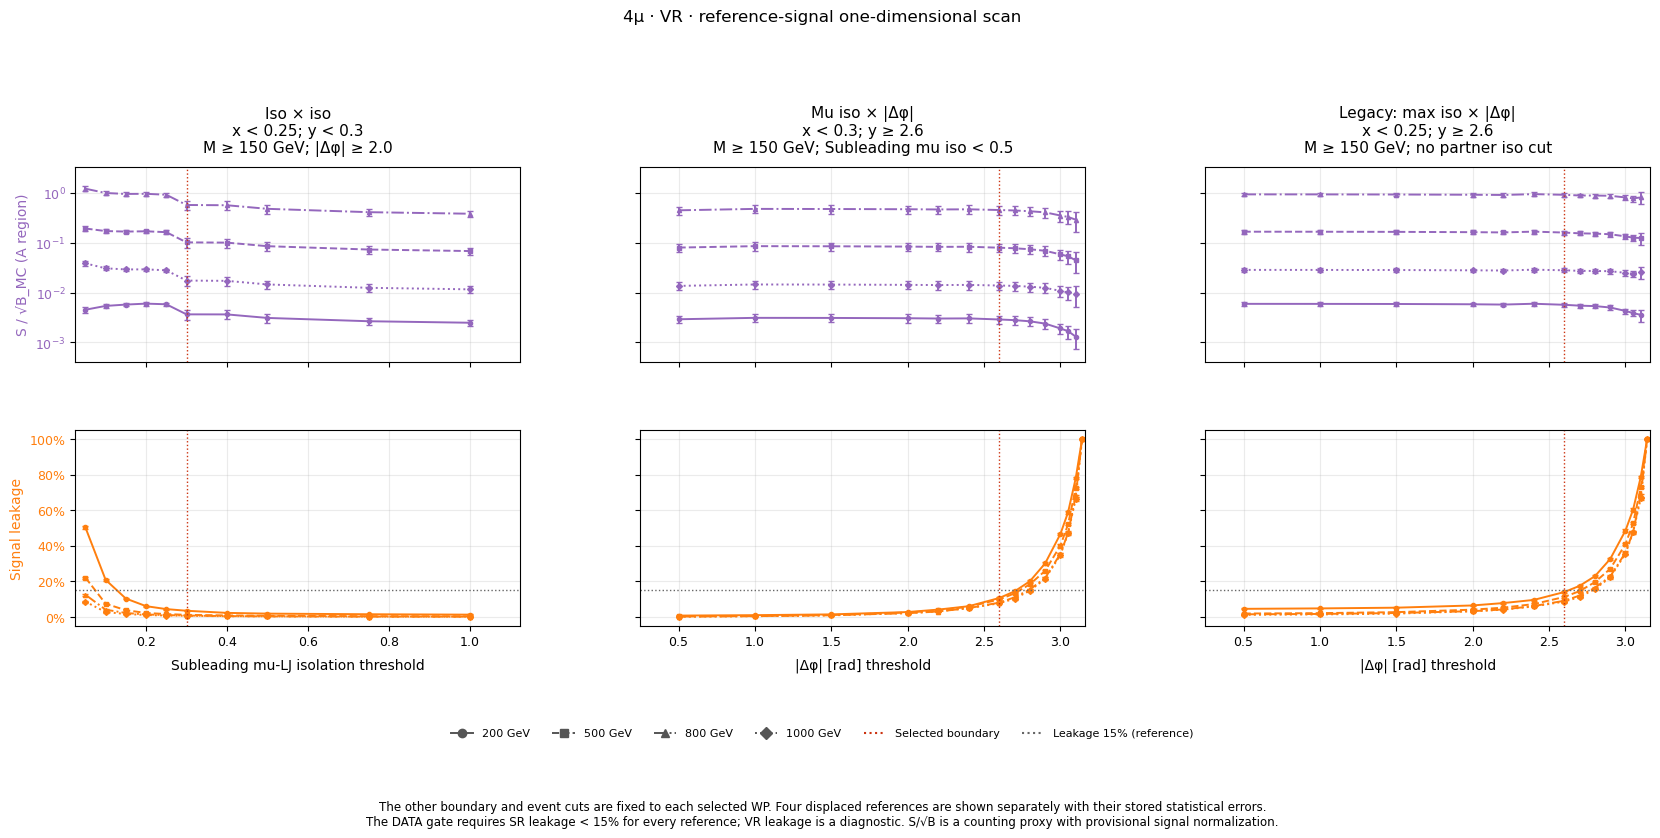

In [33]:
if 'signal_VR_y_scan' in figure_lookup:
    display(figure_lookup['signal_VR_y_scan'])
else:
    print('해당 추가 진단은 현재 설정에서 생성되지 않았습니다.')

### 4.25. 배경 process 조성: MC SR

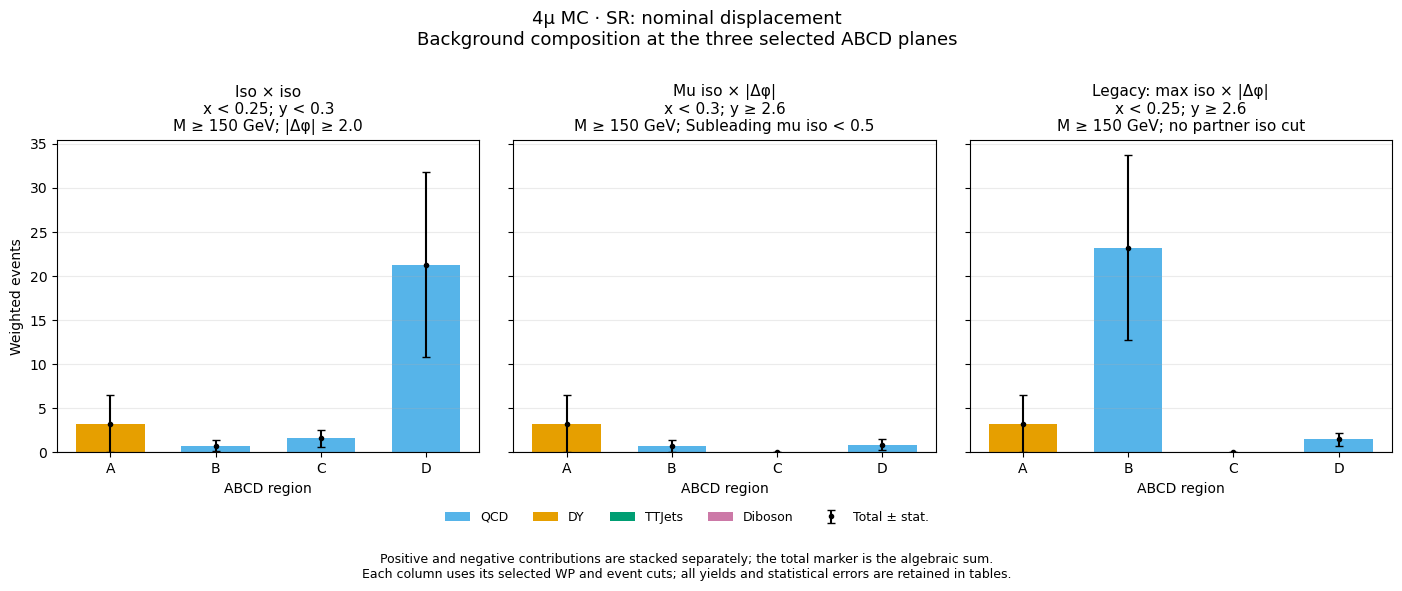

In [34]:
display(figure_lookup['mc_SR_composition'])

### 4.26. 유효 배경 통계량: MC SR

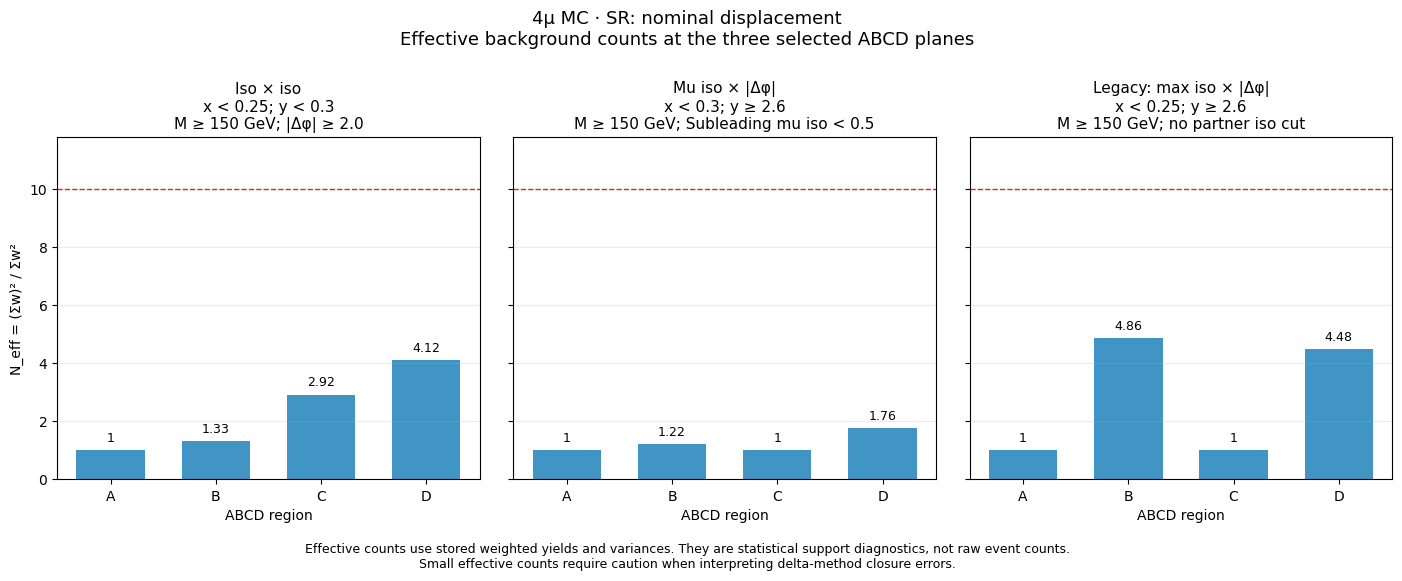

In [35]:
display(figure_lookup['mc_SR_effective_counts'])

### 4.27. 배경 process 조성: MC VR

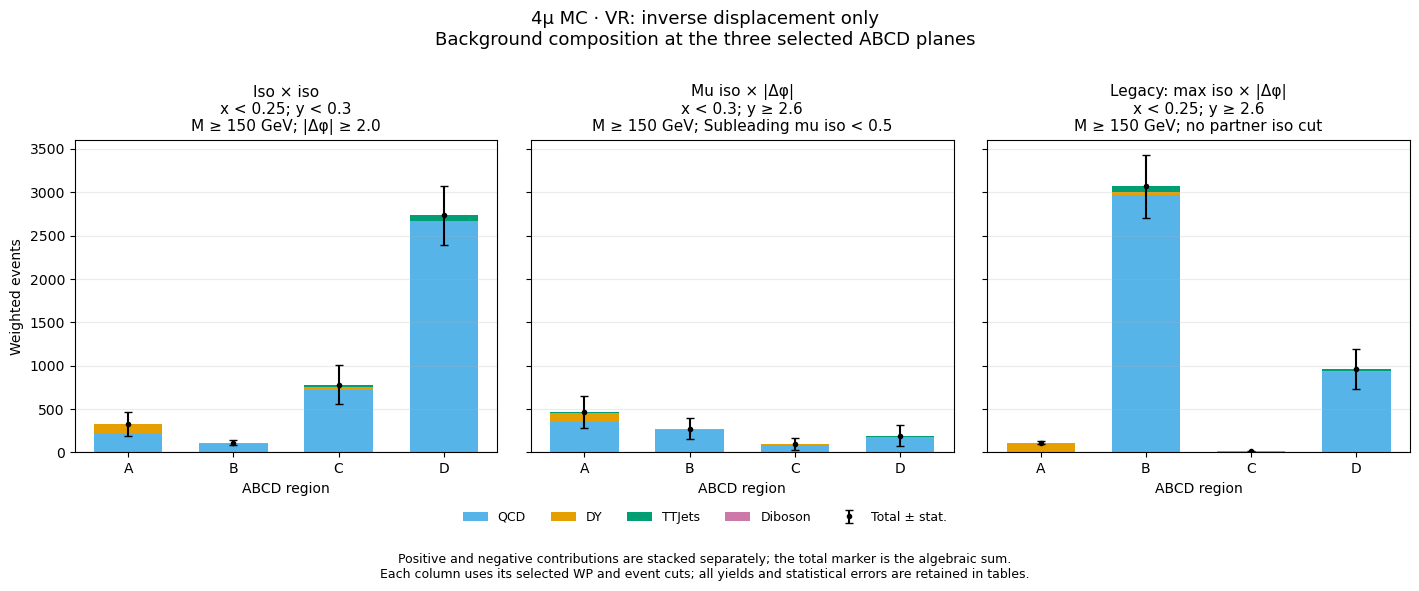

In [36]:
display(figure_lookup['mc_VR_composition'])

### 4.28. 유효 배경 통계량: MC VR

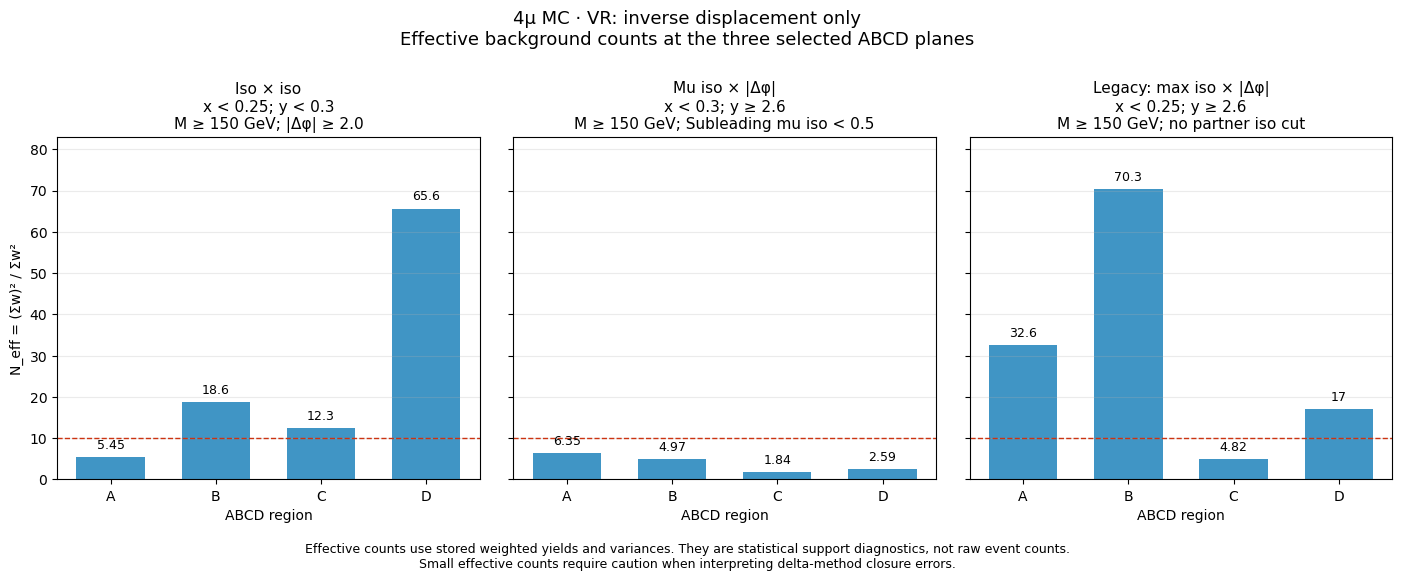

In [37]:
display(figure_lookup['mc_VR_effective_counts'])

### 4.29. 영역별 상관관계와 유효 통계: MC SR

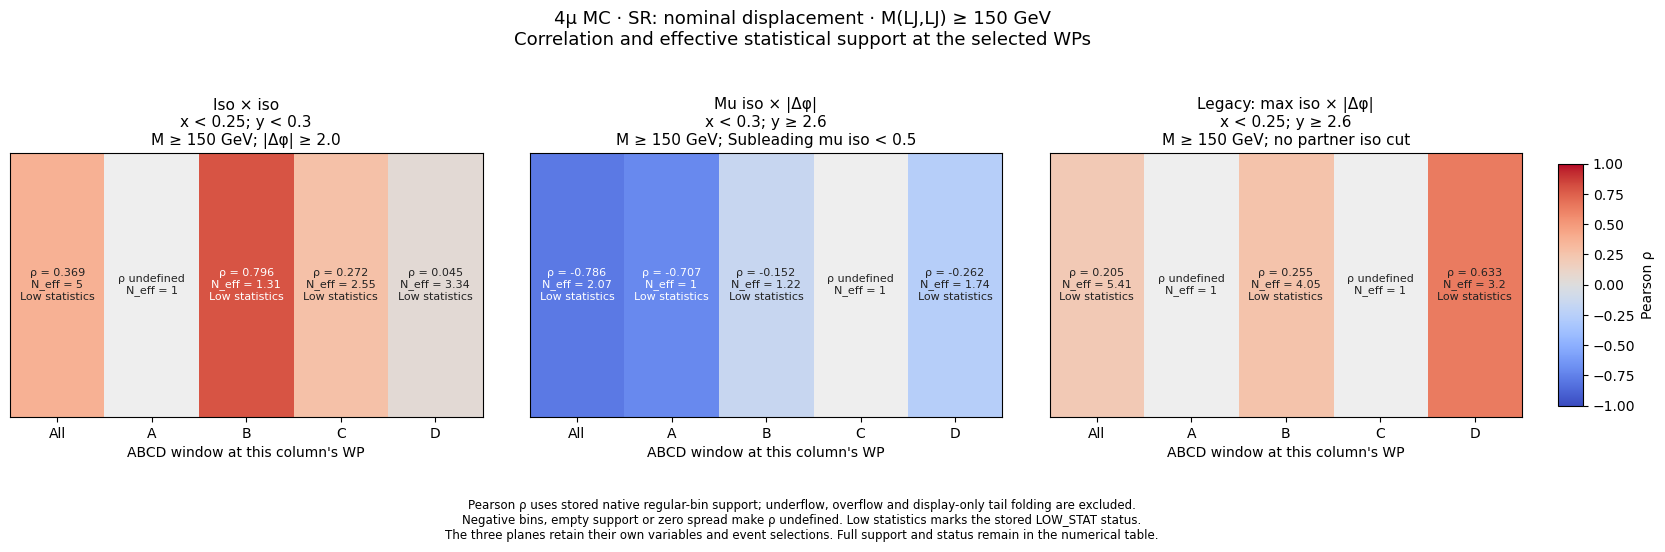

In [38]:
display(figure_lookup['mc_SR_correlations'])

### 4.30. 영역별 상관관계와 유효 통계: MC VR

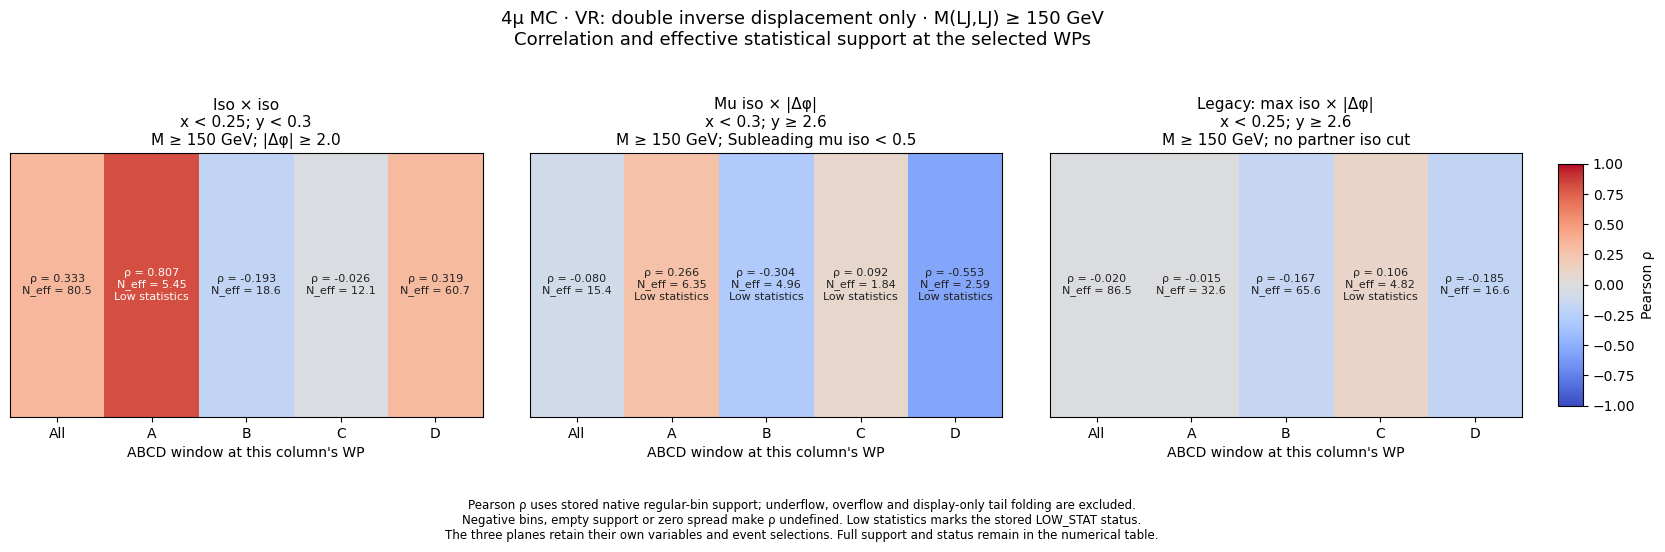

In [39]:
display(figure_lookup['mc_VR_correlations'])

### 4.31. 영역별 상관관계와 유효 통계: DATA VR

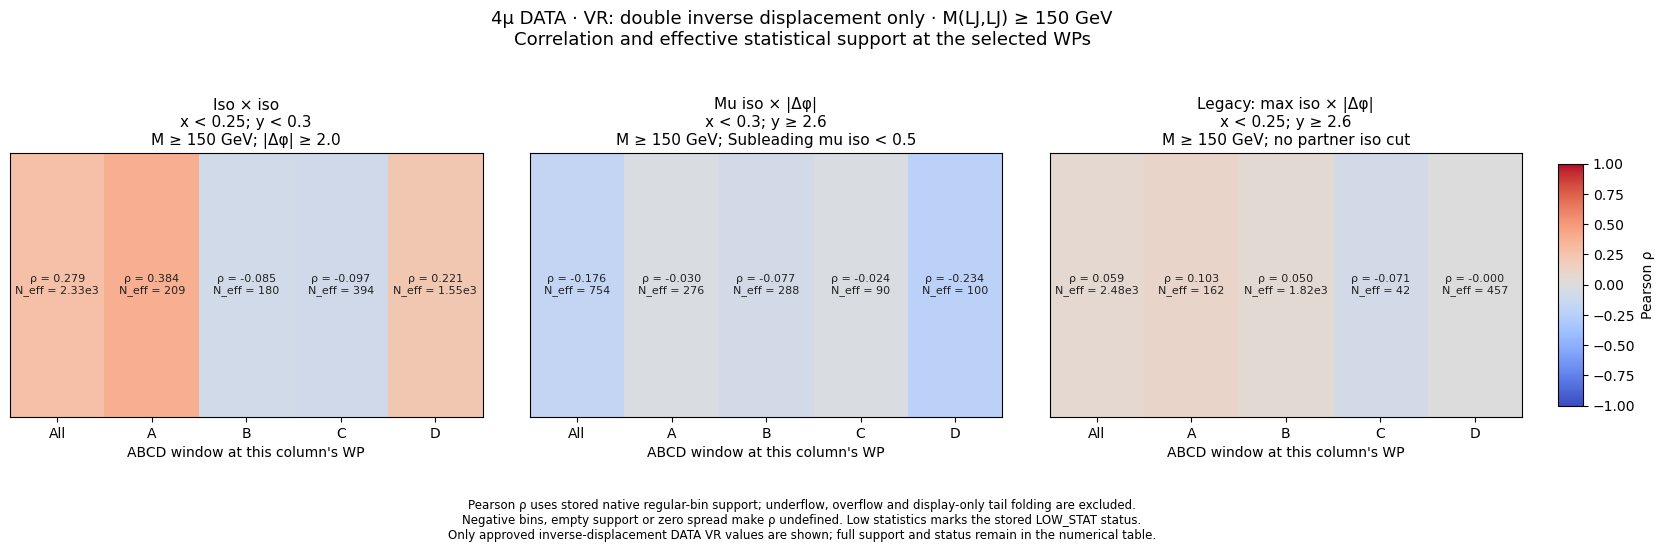

In [40]:
display(figure_lookup['data_VR_correlations'])

### 4.32. 전체 180개 신호의 pooled shape: SR

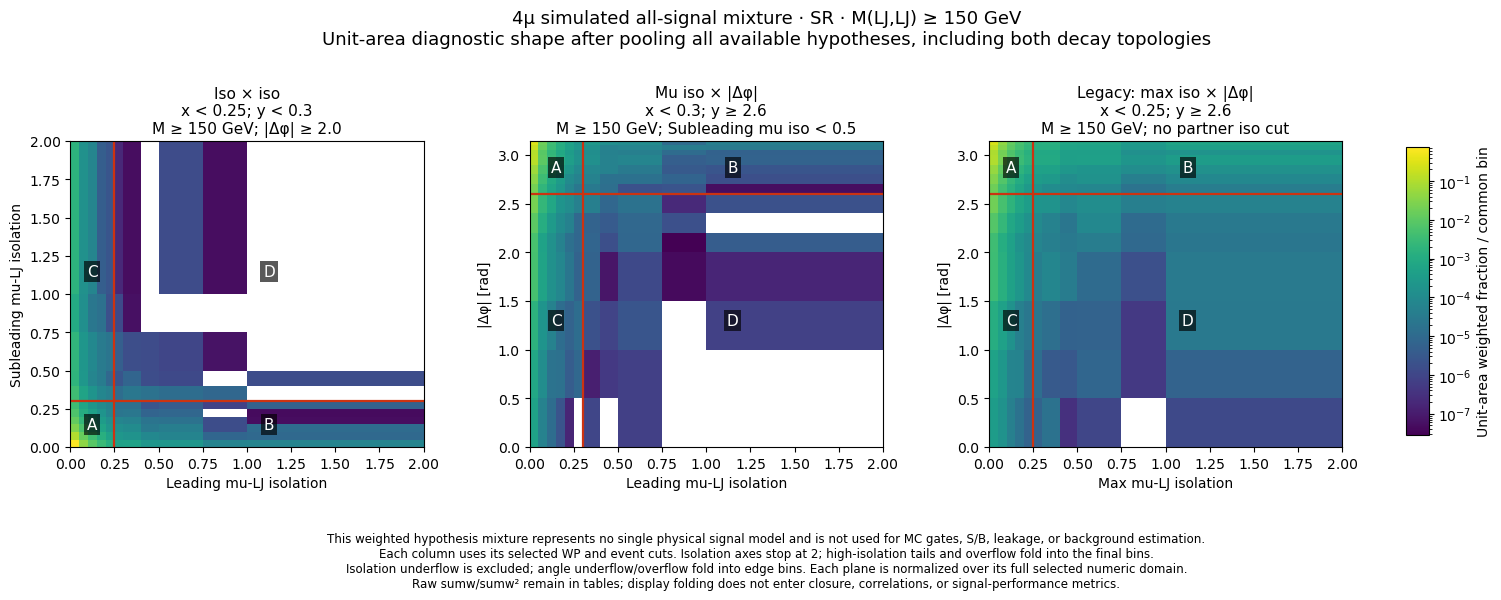

In [41]:
if 'pooled_signal_SR_planes' in figure_lookup:
    display(figure_lookup['pooled_signal_SR_planes'])
else:
    print('해당 추가 진단은 현재 설정에서 생성되지 않았습니다.')

### 4.33. 전체 180개 신호의 pooled shape: VR

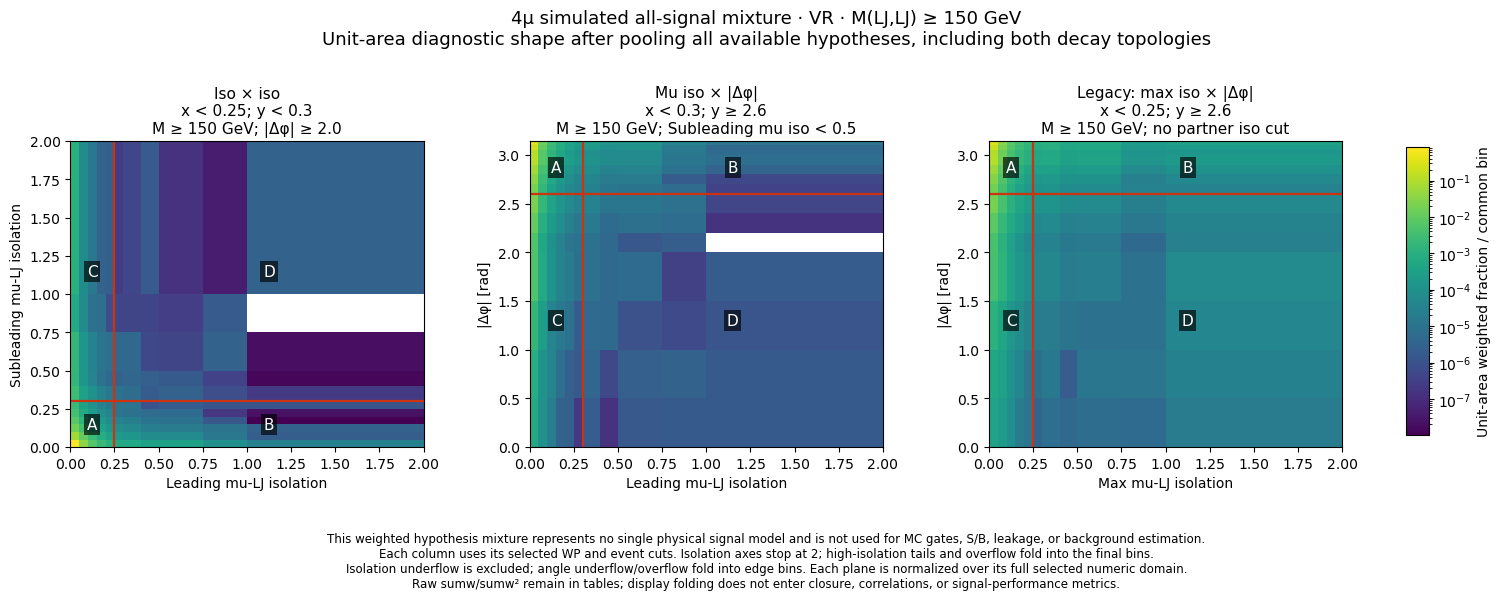

In [42]:
if 'pooled_signal_VR_planes' in figure_lookup:
    display(figure_lookup['pooled_signal_VR_planes'])
else:
    print('해당 추가 진단은 현재 설정에서 생성되지 않았습니다.')

## 5. 슬라이드와 수치 내보내기

전용 outputs 폴더에 개별 PNG/PDF, 그림 전체를 담은 `comparison_slides.pdf`, 후보·선택·신호·closure·스캔 CSV,
입력 SHA256과 재계산 검증표, 설정 manifest를 저장한다. 이전 05–10의 출력은 사용한 입력으로 기록한다.

In [43]:
export_selected_comparison(results, CONFIG, figures)
display(tables['figure_manifest'])
display(Markdown(f"[전체 비교 슬라이드 PDF]({OUTPUT_DIR.name}/comparison_slides.pdf)"))


저장: /home/cms-jovyan/workspace/CMS-SIDM-PR/sidm/studies/ABCD_plane_summary/12_Optimized_ABCD_4mu_comparison_outputs


,figure,png,pdf
0,selected_WP_overview,selected_WP_overview.png,selected_WP_overview.pdf
1,mc_SR_planes,mc_SR_planes.png,mc_SR_planes.pdf
2,mc_VR_planes,mc_VR_planes.png,mc_VR_planes.pdf
3,data_VR_planes,data_VR_planes.png,data_VR_planes.pdf
4,mc_SR_selected_closure,mc_SR_selected_closure.png,mc_SR_selected_closure.pdf
5,mc_VR_selected_closure,mc_VR_selected_closure.png,mc_VR_selected_closure.pdf
6,data_VR_selected_closure,data_VR_selected_closure.png,data_VR_selected_closure.pdf
7,mc_SR_x_scan,mc_SR_x_scan.png,mc_SR_x_scan.pdf
8,mc_SR_y_scan,mc_SR_y_scan.png,mc_SR_y_scan.pdf
9,mc_VR_x_scan,mc_VR_x_scan.png,mc_VR_x_scan.pdf


[전체 비교 슬라이드 PDF](12_Optimized_ABCD_4mu_comparison_outputs/comparison_slides.pdf)

## 결과를 발표할 때 확인할 점

- κ central value가 target band에 들어가는지와 오차의 크기를 함께 제시한다. 사용자 고정 기준점이 band 바깥이면 그 사실도 표시한다.
- 사용자 지정 WP가 closure 범위 밖이면 명시한다. 이를 자동 최적화 fallback 또는 closure를 만족한 점으로 표현하지 않는다. legacy의 fallback도 같은 방식으로 구분한다.
- 낮은 MC SR Neff에서 계산한 S/√B 순위를 확정적인 물리 최적으로 해석하지 않는다.
- 선택에 쓰지 않은 독립 데이터 또는 별도 검증이 이후 WP 확정에 필요하다.